In [ ]:

# GeoPackage retains geometries and analytical attributes
map_gdf.to_file(
    "/content/nyc_heat_project/nyc_heat_analysis.gpkg",
    driver="GPKG",
    layer="neighborhood_heat"
)

print("Saved GIS-ready neighborhood dataset.")
print("Neighborhoods:", len(map_gdf))
print("Priority neighborhoods:", map_gdf["Priority_Neighborhood"].sum())


Saved GIS-ready neighborhood dataset.
Neighborhoods: 262
Priority neighborhoods: 14


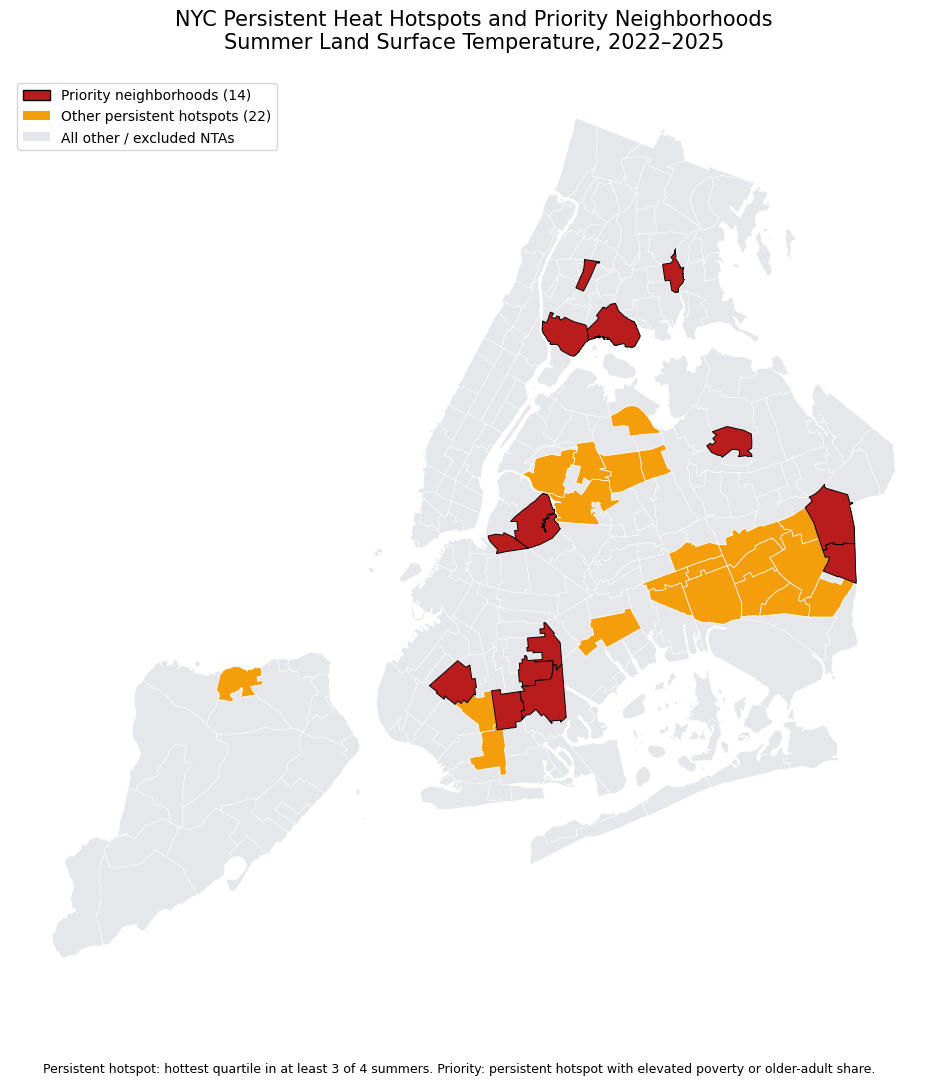

In [ ]:

import matplotlib.pyplot as plt
from matplotlib.patches import Patch

fig, ax = plt.subplots(figsize=(12, 12))

# Background: all 262 NTAs
map_gdf.plot(
    ax=ax,
    color="#e5e7eb",
    edgecolor="white",
    linewidth=0.35
)

# Persistent hotspots that are NOT priority neighborhoods
map_gdf[
    (map_gdf["Revised_Persistent"] == True)
    & (~map_gdf["Priority_Neighborhood"])
].plot(
    ax=ax,
    color="#f59e0b",
    edgecolor="white",
    linewidth=0.5
)

# Priority neighborhoods
map_gdf[
    map_gdf["Priority_Neighborhood"]
].plot(
    ax=ax,
    color="#b91c1c",
    edgecolor="black",
    linewidth=0.7
)

legend_elements = [
    Patch(
        facecolor="#b91c1c",
        edgecolor="black",
        label="Priority neighborhoods (14)"
    ),
    Patch(
        facecolor="#f59e0b",
        label="Other persistent hotspots (22)"
    ),
    Patch(
        facecolor="#e5e7eb",
        label="All other / excluded NTAs"
    )
]

ax.legend(
    handles=legend_elements,
    loc="upper left",
    frameon=True,
    fontsize=10
)

ax.set_title(
    "NYC Persistent Heat Hotspots and Priority Neighborhoods\n"
    "Summer Land Surface Temperature, 2022–2025",
    fontsize=15,
    pad=20
)

ax.set_axis_off()

fig.text(
    0.5, 0.05,
    "Persistent hotspot: hottest quartile in at least 3 of 4 summers. "
    "Priority: persistent hotspot with elevated poverty or older-adult share.",
    ha="center",
    fontsize=9,
    wrap=True
)

plt.savefig(
    "/content/nyc_heat_project/nyc_priority_map_final.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


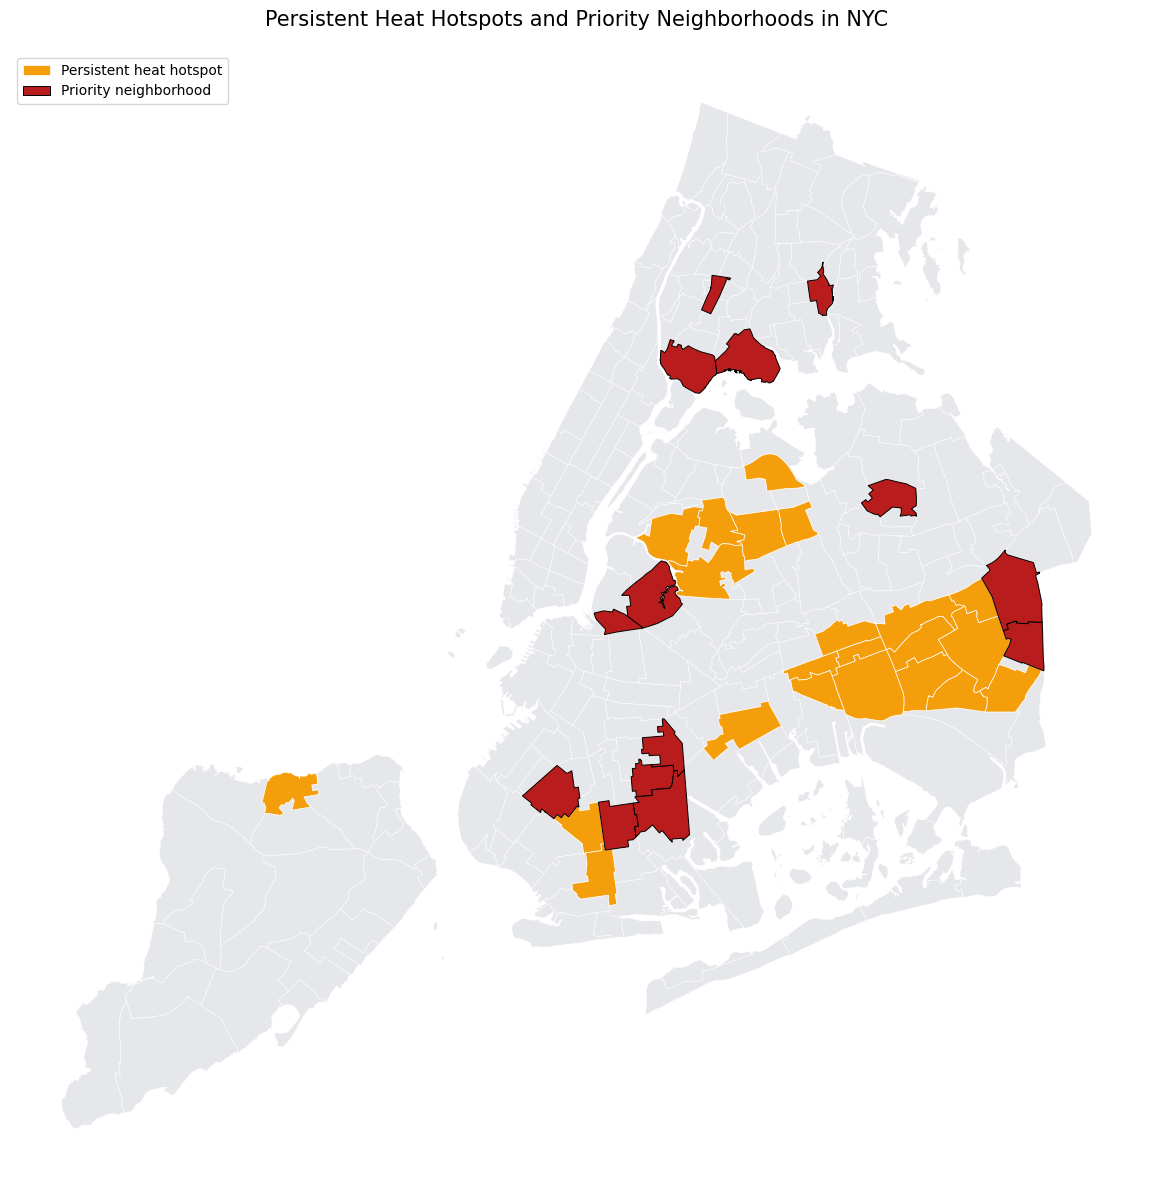

In [ ]:

fig, ax = plt.subplots(figsize=(12, 12))

# NYC background
map_gdf.plot(
    ax=ax,
    color="#e5e7eb",
    edgecolor="white",
    linewidth=0.35
)

# Persistent heat hotspots
map_gdf[
    map_gdf["Revised_Persistent"] == True
].plot(
    ax=ax,
    color="#f59e0b",
    edgecolor="white",
    linewidth=0.5,
    label="Persistent heat hotspot"
)

# Priority neighborhoods
map_gdf[
    map_gdf["Priority_Neighborhood"]
].plot(
    ax=ax,
    color="#b91c1c",
    edgecolor="black",
    linewidth=0.7,
    label="Priority neighborhood"
)

ax.set_title(
    "Persistent Heat Hotspots and Priority Neighborhoods in NYC",
    fontsize=15,
    pad=18
)

ax.legend(loc="upper left")
ax.set_axis_off()

plt.tight_layout()

plt.savefig(
    "/content/nyc_heat_project/nyc_priority_neighborhood_map.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


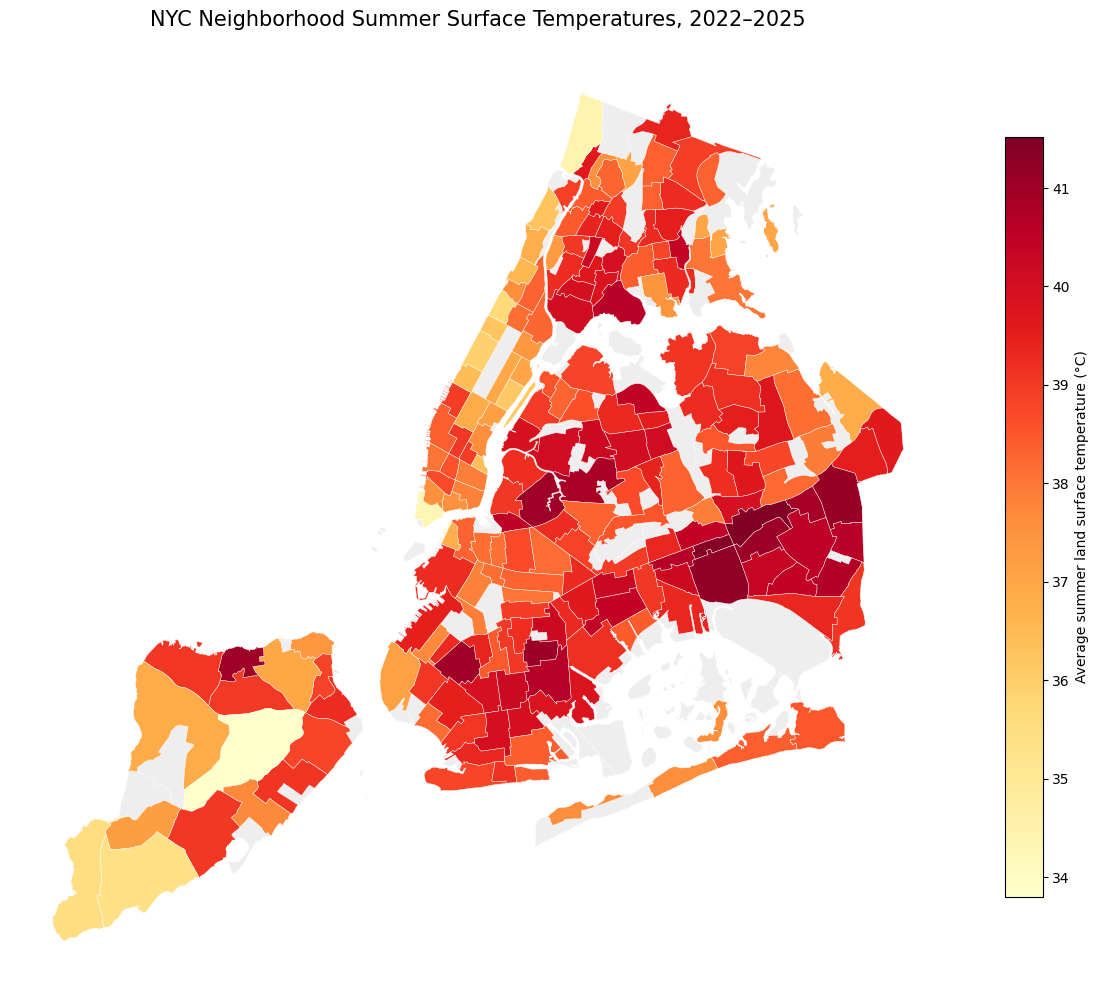

In [ ]:

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 12))

# Show all NYC neighborhood boundaries
map_gdf.plot(
    ax=ax,
    color="#eeeeee",
    edgecolor="white",
    linewidth=0.3
)

# Color standard NTAs by average summer temperature
map_gdf[
    map_gdf["Avg_LST_2022_2025"].notna()
].plot(
    column="Avg_LST_2022_2025",
    ax=ax,
    cmap="YlOrRd",
    legend=True,
    legend_kwds={
        "label": "Average summer land surface temperature (°C)",
        "shrink": 0.65
    },
    edgecolor="white",
    linewidth=0.3
)

ax.set_title(
    "NYC Neighborhood Summer Surface Temperatures, 2022–2025",
    fontsize=15,
    pad=18
)

ax.set_axis_off()
plt.tight_layout()

plt.savefig(
    "/content/nyc_heat_project/nyc_summer_lst_map.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [ ]:


import geopandas as gpd

# Use only the neighborhood ID and geometry from the spatial dataset
map_base = nta_clean[
    ["nta2020", "geometry"]
].copy()

# Merge the final validated analytical indicators
map_gdf = map_base.merge(
    final_analysis[
        [
            "nta2020",
            "Avg_LST_2022_2025",
            "Revised_Persistent",
            "Elevated_Social_Vulnerability",
            "Impervious_Percent",
            "Avg_NDVI_2022_2025"
        ]
    ],
    on="nta2020",
    how="left",
    validate="one_to_one"
)

# Identify priority neighborhoods
priority_ids = set(priority_final["nta2020"])

map_gdf["Priority_Neighborhood"] = (
    map_gdf["nta2020"].isin(priority_ids)
)

# Validate the merged spatial dataset
print("Total mapped NTAs:", len(map_gdf))

print(
    "NTAs with temperature data:",
    map_gdf["Avg_LST_2022_2025"].notna().sum()
)

print(
    "Persistent hotspots:",
    map_gdf["Revised_Persistent"].fillna(False).sum()
)

print(
    "Priority neighborhoods:",
    map_gdf["Priority_Neighborhood"].sum()
)

print("\nCoordinate system:", map_gdf.crs)


Total mapped NTAs: 262
NTAs with temperature data: 197
Persistent hotspots: 36
Priority neighborhoods: 14

Coordinate system: EPSG:4326


/tmp/ipykernel_2718/3070119277.py:42: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  map_gdf["Revised_Persistent"].fillna(False).sum()


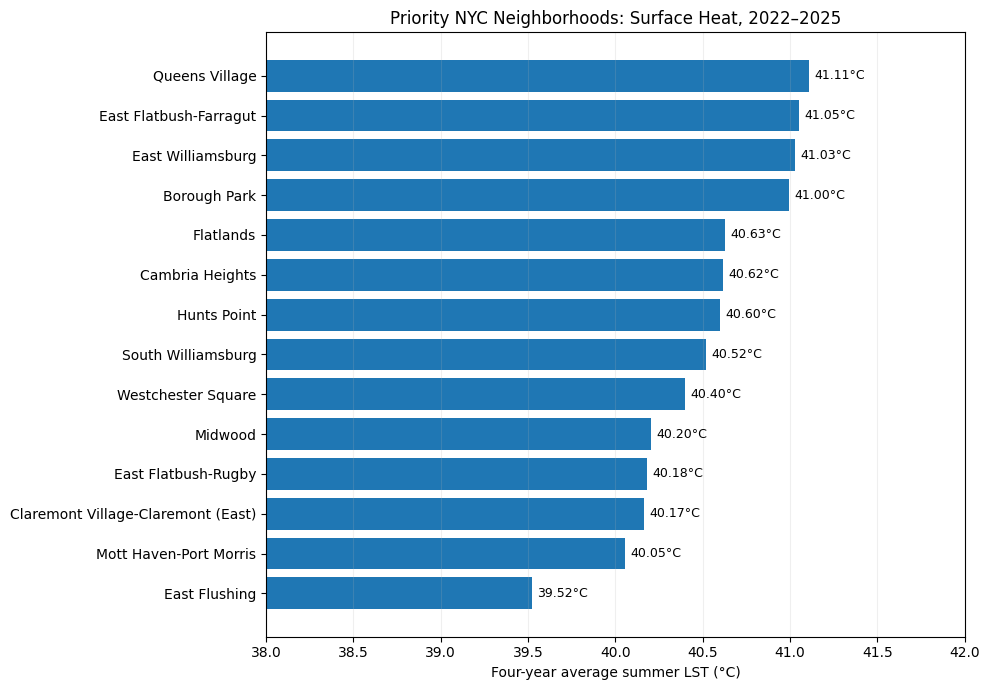

In [ ]:

priority_plot = priority_final.sort_values(
    "Avg_LST_2022_2025"
)

fig, ax = plt.subplots(figsize=(10, 7))

bars = ax.barh(
    priority_plot["ntaname"],
    priority_plot["Avg_LST_2022_2025"]
)

ax.set_xlim(38, 42)
ax.set_xlabel("Four-year average summer LST (°C)")
ax.set_title("Priority NYC Neighborhoods: Surface Heat, 2022–2025")
ax.grid(axis="x", alpha=0.2)

for bar, value in zip(bars, priority_plot["Avg_LST_2022_2025"]):
    ax.text(
        value + 0.03,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.2f}°C",
        va="center",
        fontsize=9
    )

plt.tight_layout()
plt.savefig(
    "/content/nyc_heat_project/priority_neighborhood_temperatures.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


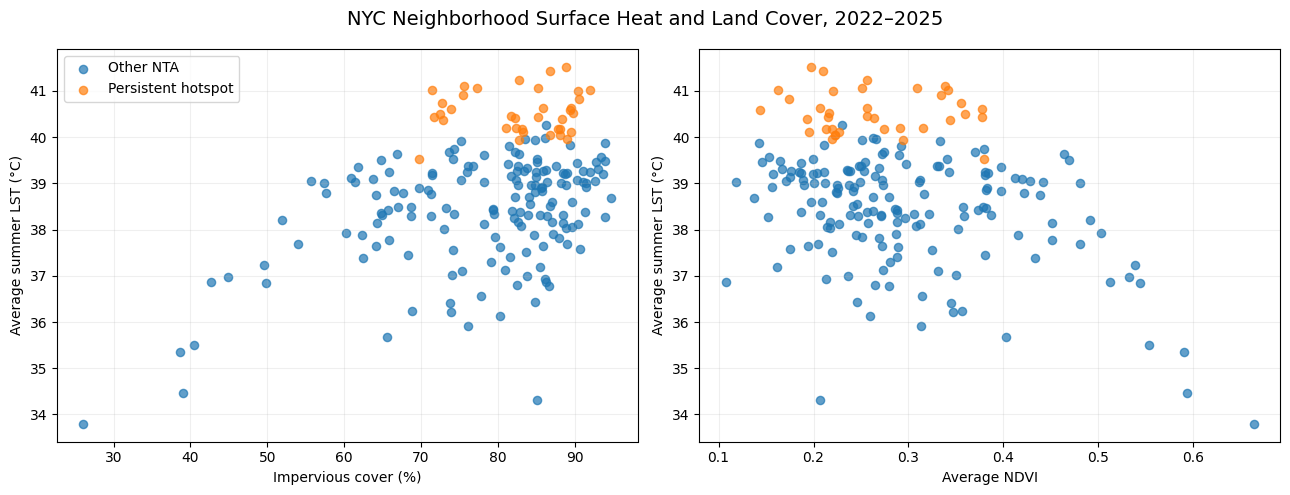

In [ ]:

import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

variables = [
    ("Impervious_Percent", "Impervious cover (%)"),
    ("Avg_NDVI_2022_2025", "Average NDVI")
]

for ax, (column, label) in zip(axes, variables):
    for is_hot, group in final_analysis.groupby("Revised_Persistent"):
        ax.scatter(
            group[column],
            group["Avg_LST_2022_2025"],
            alpha=0.7,
            s=35,
            label="Persistent hotspot" if is_hot else "Other NTA"
        )

    ax.set_xlabel(label)
    ax.set_ylabel("Average summer LST (°C)")
    ax.grid(alpha=0.2)

axes[0].legend()
fig.suptitle(
    "NYC Neighborhood Surface Heat and Land Cover, 2022–2025",
    fontsize=14
)
plt.tight_layout()
plt.savefig(
    "/content/nyc_heat_project/land_cover_relationships.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


In [ ]:

priority_final = final_analysis[
    final_analysis["nta2020"].isin(
        priority_neighborhoods["nta2020"]
    )
].copy()

priority_final = priority_final.sort_values(
    "Avg_LST_2022_2025",
    ascending=False
)

print(
    priority_final[
        [
            "ntaname",
            "boroname",
            "Avg_LST_2022_2025",
            "Poverty_Rate",
            "Percent_65_Plus",
            "Impervious_Percent",
            "Avg_NDVI_2022_2025",
            "Revised_Hot_Years"
        ]
    ].round(3).to_string(index=False)
)


                           ntaname boroname  Avg_LST_2022_2025  Poverty_Rate  Percent_65_Plus  Impervious_Percent  Avg_NDVI_2022_2025  Revised_Hot_Years
                    Queens Village   Queens             41.109         9.550           21.357              75.570               0.339                  4
            East Flatbush-Farragut Brooklyn             41.054        12.997           22.101              85.170               0.251                  4
                 East Williamsburg Brooklyn             41.028        24.054           13.296              91.955               0.163                  4
                      Borough Park Brooklyn             40.996        33.696            9.780              90.484               0.221                  4
                         Flatlands Brooklyn             40.629        11.601           20.487              85.915               0.256                  4
                   Cambria Heights   Queens             40.615         7.575      

In [ ]:

correlation_columns = [
    "Avg_LST_2022_2025",
    "Impervious_Percent",
    "Avg_NDVI_2022_2025",
    "Poverty_Rate",
    "Percent_65_Plus"
]

correlations = (
    final_analysis[correlation_columns]
    .corr(method="spearman")["Avg_LST_2022_2025"]
    .drop("Avg_LST_2022_2025")
    .sort_values(ascending=False)
)

print("Spearman correlations with average summer LST:\n")
print(correlations.round(3).to_string())


Spearman correlations with average summer LST:

Impervious_Percent    0.283
Poverty_Rate          0.182
Percent_65_Plus      -0.171
Avg_NDVI_2022_2025   -0.238


In [ ]:

comparison_columns = [
    "Avg_LST_2022_2025",
    "Impervious_Percent",
    "Avg_NDVI_2022_2025",
    "Poverty_Rate",
    "Percent_65_Plus"
]

hotspot_comparison = (
    final_analysis
    .groupby("Revised_Persistent")[comparison_columns]
    .mean()
    .round(3)
)

hotspot_comparison.index = hotspot_comparison.index.map({
    False: "Other neighborhoods",
    True: "Persistent hotspots"
})

print(hotspot_comparison.to_string())


                     Avg_LST_2022_2025  Impervious_Percent  Avg_NDVI_2022_2025  Poverty_Rate  Percent_65_Plus
Revised_Persistent                                                                                           
Other neighborhoods             38.375              77.725               0.297        17.361           16.978
Persistent hotspots             40.543              82.874               0.262        17.986           16.130


In [ ]:

assert len(final_analysis) == 197, (
    "Expected 197 standard NTAs."
)

assert final_analysis["nta2020"].is_unique, (
    "Duplicate NTA identifiers found."
)

assert final_analysis["Revised_Persistent"].sum() == 36, (
    "Persistent hotspot count differs from validation."
)

print("Dataset integrity checks passed.")
print("Standard neighborhoods:", len(final_analysis))
print(
    "Persistent hotspots:",
    final_analysis["Revised_Persistent"].sum()
)

print(
    "Neighborhoods with complete analytical indicators:",
    final_analysis[
        [
            "Avg_LST_2022_2025",
            "Poverty_Rate",
            "Percent_65_Plus",
            "Impervious_Percent",
            "Avg_NDVI_2022_2025"
        ]
    ].notna().all(axis=1).sum()
)


Dataset integrity checks passed.
Standard neighborhoods: 197
Persistent hotspots: 36
Neighborhoods with complete analytical indicators: 197


In [ ]:

# Start with the validated residential socioeconomic dataset
final_analysis = residential_socioeconomic.copy()

# Add infrastructure characteristics
final_analysis = final_analysis.merge(
    impervious_df[["nta2020", "Impervious_Percent"]],
    on="nta2020",
    how="left",
    validate="one_to_one"
)

# Calculate four-year average NDVI
ndvi_4yr = (
    ndvi_df[ndvi_df["Year"].between(2022, 2025)]
    .groupby("nta2020", as_index=False)
    .agg(
        Avg_NDVI_2022_2025=("Mean_NDVI", "mean"),
        NDVI_Years=("Mean_NDVI", "count")
    )
)

final_analysis = final_analysis.merge(
    ndvi_4yr,
    on="nta2020",
    how="left",
    validate="one_to_one"
)

# Add revised-mask persistence validation
final_analysis = final_analysis.merge(
    persistence_comparison[
        ["nta2020", "Revised_Hot_Years", "Revised_Persistent"]
    ],
    on="nta2020",
    how="left",
    validate="one_to_one"
)

print("Neighborhoods:", len(final_analysis))
print("\nMissing values:")
print(
    final_analysis[
        [
            "Avg_LST_2022_2025",
            "Poverty_Rate",
            "Percent_65_Plus",
            "Impervious_Percent",
            "Avg_NDVI_2022_2025",
            "Revised_Hot_Years"
        ]
    ].isna().sum()
)

print("\nSample:")
print(final_analysis.head(5).round(3).to_string(index=False))


Neighborhoods: 197

Missing values:
Avg_LST_2022_2025     0
Poverty_Rate          0
Percent_65_Plus       0
Impervious_Percent    0
Avg_NDVI_2022_2025    0
Revised_Hot_Years     0
dtype: int64

Sample:
nta2020            ntaname boroname  Avg_LST_2022_2025  Min_LST  Max_LST  Avg_Completeness  Years_Observed  Poverty_Rate  Percent_65_Plus  Total_Population  Years_In_Top_Quartile  Persistent_Hotspot  High_Poverty  High_Older_Adult  Elevated_Social_Vulnerability  Impervious_Percent  Avg_NDVI_2022_2025  NDVI_Years  Revised_Hot_Years  Revised_Persistent
 BK0101         Greenpoint Brooklyn             39.200   37.173   40.420            93.014               4         9.031            9.195             39784                      1               False         False             False                          False              93.677               0.158           4                  1               False
 BK0102       Williamsburg Brooklyn             39.017   36.999   40.126            98.531  

In [ ]:

validation_summary = (
    four_year_sensitivity
    .groupby("Year")["LST_Change_C"]
    .agg(
        Neighborhoods_Compared="count",
        Mean_Absolute_Change_C=lambda x: x.abs().mean(),
        Maximum_Absolute_Change_C=lambda x: x.abs().max()
    )
    .reset_index()
)

validation_summary["Persistent_Hotspots_Original"] = 36
validation_summary["Persistent_Hotspots_Revised"] = 36
validation_summary["Persistence_Classification_Changes"] = 0

validation_summary.to_csv(
    output_dir / "water_mask_validation_summary.csv",
    index=False
)

print(validation_summary.round(4).to_string(index=False))


 Year  Neighborhoods_Compared  Mean_Absolute_Change_C  Maximum_Absolute_Change_C  Persistent_Hotspots_Original  Persistent_Hotspots_Revised  Persistence_Classification_Changes
 2022                     262                  0.0300                     0.3045                            36                           36                                   0
 2023                     262                  0.0295                     0.3950                            36                           36                                   0
 2024                     262                  0.0289                     0.2776                            36                           36                                   0
 2025                     262                  0.0306                     0.3748                            36                           36                                   0


In [ ]:

from pathlib import Path

output_dir = Path("/content/nyc_heat_project")
output_dir.mkdir(parents=True, exist_ok=True)

# Full neighborhood-by-year sensitivity results
four_year_sensitivity.to_csv(
    output_dir / "water_mask_sensitivity_2022_2025.csv",
    index=False
)

# Original vs. revised persistent-hotspot classifications
persistence_comparison.to_csv(
    output_dir / "heat_persistence_validation.csv",
    index=False
)

# Priority neighborhood validation
priority_persistence_check.to_csv(
    output_dir / "priority_neighborhood_validation.csv",
    index=False
)

print("Saved 3 validation files to:", output_dir)


Saved 3 validation files to: /content/nyc_heat_project


In [ ]:

priority_persistence_check = priority_neighborhoods[
    ["nta2020", "ntaname", "boroname"]
].merge(
    persistence_comparison[
        [
            "nta2020",
            "Original_Hot_Years",
            "Revised_Hot_Years",
            "Revised_Persistent"
        ]
    ],
    on="nta2020",
    how="left",
    validate="one_to_one"
)

print(
    priority_persistence_check[
        [
            "ntaname",
            "Original_Hot_Years",
            "Revised_Hot_Years",
            "Revised_Persistent"
        ]
    ].to_string(index=False)
)

print(
    "\nOriginal priority neighborhoods retaining persistent heat:",
    priority_persistence_check["Revised_Persistent"].sum(),
    "of",
    len(priority_persistence_check)
)


                           ntaname  Original_Hot_Years  Revised_Hot_Years  Revised_Persistent
                    Queens Village                   4                  4                True
            East Flatbush-Farragut                   4                  4                True
                 East Williamsburg                   4                  4                True
                      Borough Park                   4                  4                True
                         Flatlands                   4                  4                True
                   Cambria Heights                   4                  4                True
                       Hunts Point                   4                  4                True
                South Williamsburg                   3                  3                True
                Westchester Square                   4                  4                True
                           Midwood                   4      

In [ ]:

residential_sensitivity = four_year_sensitivity[
    four_year_sensitivity["ntatype"].astype(str) == "0"
].copy()

# Determine hottest-quartile membership for each year
residential_sensitivity["Original_Hot"] = False
residential_sensitivity["Revised_Hot"] = False

for year in [2022, 2023, 2024, 2025]:

    mask = residential_sensitivity["Year"] == year

    original_threshold = residential_sensitivity.loc[
        mask, "Summer_LST_C"
    ].quantile(0.75)

    revised_threshold = residential_sensitivity.loc[
        mask, "Revised_LST_C"
    ].quantile(0.75)

    residential_sensitivity.loc[mask, "Original_Hot"] = (
        residential_sensitivity.loc[mask, "Summer_LST_C"]
        >= original_threshold
    )

    residential_sensitivity.loc[mask, "Revised_Hot"] = (
        residential_sensitivity.loc[mask, "Revised_LST_C"]
        >= revised_threshold
    )

# Count hottest-quartile years per neighborhood
persistence_comparison = (
    residential_sensitivity.groupby(
        ["nta2020", "ntaname", "boroname"],
        as_index=False
    )
    .agg(
        Original_Hot_Years=("Original_Hot", "sum"),
        Revised_Hot_Years=("Revised_Hot", "sum")
    )
)

persistence_comparison["Original_Persistent"] = (
    persistence_comparison["Original_Hot_Years"] >= 3
)

persistence_comparison["Revised_Persistent"] = (
    persistence_comparison["Revised_Hot_Years"] >= 3
)

persistence_comparison["Classification_Changed"] = (
    persistence_comparison["Original_Persistent"]
    != persistence_comparison["Revised_Persistent"]
)

print(
    "Original persistent hotspots:",
    persistence_comparison["Original_Persistent"].sum()
)

print(
    "Revised persistent hotspots:",
    persistence_comparison["Revised_Persistent"].sum()
)

print(
    "Neighborhoods changing persistence classification:",
    persistence_comparison["Classification_Changed"].sum()
)

print("\nChanged neighborhoods:")
print(
    persistence_comparison.loc[
        persistence_comparison["Classification_Changed"],
        [
            "ntaname",
            "Original_Hot_Years",
            "Revised_Hot_Years"
        ]
    ].to_string(index=False)
)


Original persistent hotspots: 36
Revised persistent hotspots: 36
Neighborhoods changing persistence classification: 0

Changed neighborhoods:
Empty DataFrame
Columns: [ntaname, Original_Hot_Years, Revised_Hot_Years]
Index: []


In [ ]:

revised_annual_results = []

for year, img in revised_summer_layers.items():

    stats = img.reduceRegions(
        collection=nta_ee,
        reducer=ee.Reducer.mean(),
        scale=30,
        tileScale=4
    )

    df = geemap.ee_to_df(stats)

    df = df[
        ["nta2020", "mean"]
    ].rename(columns={"mean": "Revised_LST_C"})

    df["Year"] = year

    revised_annual_results.append(df)

revised_annual_df = pd.concat(
    revised_annual_results,
    ignore_index=True
)

four_year_sensitivity = neighborhood_final[
    [
        "nta2020",
        "ntaname",
        "boroname",
        "ntatype",
        "Year",
        "Summer_LST_C"
    ]
].merge(
    revised_annual_df,
    on=["nta2020", "Year"],
    how="left",
    validate="one_to_one"
)

four_year_sensitivity["LST_Change_C"] = (
    four_year_sensitivity["Revised_LST_C"]
    - four_year_sensitivity["Summer_LST_C"]
)

print(
    four_year_sensitivity.groupby("Year")["LST_Change_C"]
    .agg(
        Compared="count",
        Mean_Absolute_Change=lambda x: x.abs().mean(),
        Maximum_Absolute_Change=lambda x: x.abs().max()
    )
    .round(4)
    .to_string()
)


      Compared  Mean_Absolute_Change  Maximum_Absolute_Change
Year                                                         
2022       262                0.0300                   0.3045
2023       262                0.0295                   0.3950
2024       262                0.0289                   0.2776
2025       262                0.0306                   0.3748


In [ ]:

# Apply improved land mask to validated annual composites
revised_summer_layers = {}

for year in [2022, 2023, 2024, 2025]:
    revised_summer_layers[year] = (
        candidate_summer_layers[year]
        .updateMask(improved_land_mask)
        .rename("LST_C")
    )

print(
    "Revised images created for:",
    list(revised_summer_layers.keys())
)


Revised images created for: [2022, 2023, 2024, 2025]


In [ ]:

candidate_validation = []

for year, img in candidate_summer_layers.items():

    stats = img.reduceRegions(
        collection=nta_ee,
        reducer=ee.Reducer.mean(),
        scale=30,
        tileScale=4
    )

    df = geemap.ee_to_df(stats)

    df = df[
        ["nta2020", "mean"]
    ].rename(columns={"mean": "Candidate_LST_C"})

    original = neighborhood_final[
        neighborhood_final["Year"] == year
    ][["nta2020", "Summer_LST_C"]]

    comparison = original.merge(
        df,
        on="nta2020",
        how="left",
        validate="one_to_one"
    )

    differences = (
        comparison["Candidate_LST_C"]
        - comparison["Summer_LST_C"]
    ).abs()

    candidate_validation.append({
        "Year": year,
        "Compared_NTAs": differences.notna().sum(),
        "Mean_Absolute_Difference_C": differences.mean(),
        "Maximum_Difference_C": differences.max(),
        "NTAs_Above_0_01C": (differences > 0.01).sum()
    })

print(
    pd.DataFrame(candidate_validation)
    .round(6)
    .to_string(index=False)
)


 Year  Compared_NTAs  Mean_Absolute_Difference_C  Maximum_Difference_C  NTAs_Above_0_01C
 2022            262                         0.0                   0.0                 0
 2023            262                         0.0                   0.0                 0
 2024            262                         0.0                   0.0                 0
 2025            262                         0.0                   0.0                 0


In [ ]:

# Generate candidate month-balanced images
candidate_summer_layers = {}

for year in [2022, 2023, 2024, 2025]:
    candidate_summer_layers[year] = (
        create_summer_layers(year).select("LST_C")
    )

print(
    "Candidate summer layers created:",
    list(candidate_summer_layers.keys())
)


Candidate summer layers created: [2022, 2023, 2024, 2025]


In [ ]:

import inspect

for name in [
    "get_all_summer_images",
    "create_summer_layers"
]:
    fn = globals().get(name)

    if callable(fn):
        print(f"\n{'=' * 15} {name} {'=' * 15}")
        print(inspect.getsource(fn))

print("\nCombined monthly results type:",
      type(combined_monthly_results).__name__)

print("Combined monthly results count:",
      len(combined_monthly_results))

print("\nCombined monthly DataFrame columns:")
print(combined_monthly_df.columns.tolist())

print("\nFirst few monthly records:")
print(combined_monthly_df.head(3).to_string(index=False))



=============== get_all_summer_images ===============
def get_all_summer_images(year):

    start = f"{year}-06-01"
    end = f"{year}-09-01"

    l8 = (
        ee.ImageCollection("LANDSAT/LC08/C02/T1_L2")
        .filterBounds(nyc)
        .filterDate(start, end)
    )

    l9 = (
        ee.ImageCollection("LANDSAT/LC09/C02/T1_L2")
        .filterBounds(nyc)
        .filterDate(start, end)
    )

    return l8.merge(l9).map(process_landsat)


=============== create_summer_layers ===============
def create_summer_layers(year):

    images = get_all_summer_images(year)

    monthly_means = []
    monthly_counts = []

    for month in [6, 7, 8]:

        start = ee.Date.fromYMD(year, month, 1)
        end = start.advance(1, "month")

        monthly = images.filterDate(start, end)

        monthly_mean = monthly.mean().select("LST_C")

        monthly_count = (
            monthly.select("LST_C")
            .count()
            .unmask(0)
            .gt(0)
            .rename("valid

In [ ]:

saved_image_validation = []

for year in [2022, 2023, 2024, 2025]:

    img = summer_images[year].select("LST_C")

    stats = img.reduceRegions(
        collection=nta_ee,
        reducer=ee.Reducer.mean(),
        scale=30,
        tileScale=4
    )

    df = geemap.ee_to_df(stats)

    df = df[
        ["nta2020", "mean"]
    ].rename(columns={"mean": "Saved_Image_LST"})

    original = neighborhood_final[
        neighborhood_final["Year"] == year
    ][["nta2020", "Summer_LST_C"]]

    comparison = original.merge(
        df,
        on="nta2020",
        how="left",
        validate="one_to_one"
    )

    differences = (
        comparison["Saved_Image_LST"]
        - comparison["Summer_LST_C"]
    ).abs()

    saved_image_validation.append({
        "Year": year,
        "Compared_NTAs": differences.notna().sum(),
        "Mean_Absolute_Difference_C": differences.mean(),
        "Maximum_Difference_C": differences.max()
    })

print(
    pd.DataFrame(saved_image_validation)
    .round(6)
    .to_string(index=False)
)


 Year  Compared_NTAs  Mean_Absolute_Difference_C  Maximum_Difference_C
 2022            262                    0.667674              3.124705
 2023            262                    1.398938              3.150681
 2024            262                    0.671847              1.949611
 2025            262                    1.446917              3.517994


In [ ]:

validation_results = []

for year, img in baseline_images.items():

    annual_stats = img.select("LST_C").reduceRegions(
        collection=nta_ee,
        reducer=ee.Reducer.mean(),
        scale=30,
        tileScale=4
    )

    annual_df = geemap.ee_to_df(annual_stats)

    annual_df = annual_df[
        ["nta2020", "mean"]
    ].rename(columns={"mean": "Reconstructed_LST_C"})

    original_year = neighborhood_final[
        neighborhood_final["Year"] == year
    ][["nta2020", "Summer_LST_C"]]

    comparison = original_year.merge(
        annual_df,
        on="nta2020",
        how="left",
        validate="one_to_one"
    )

    difference = (
        comparison["Reconstructed_LST_C"]
        - comparison["Summer_LST_C"]
    ).abs()

    validation_results.append({
        "Year": year,
        "Compared_NTAs": difference.notna().sum(),
        "Mean_Absolute_Difference_C": difference.mean(),
        "Maximum_Difference_C": difference.max()
    })

validation_summary = pd.DataFrame(validation_results)

print(validation_summary.round(6).to_string(index=False))


 Year  Compared_NTAs  Mean_Absolute_Difference_C  Maximum_Difference_C
 2022            262                    0.667674              3.124705
 2023            262                    1.398938              3.150681
 2024            262                    0.671847              1.949611


In [ ]:

# Reconstruct annual summer LST images
baseline_images = {}

for year in [2022, 2023, 2024]:
    baseline_images[year] = get_summer_temperature(year)

print("Created baseline images for:", list(baseline_images.keys()))


Created baseline images for: [2022, 2023, 2024]


In [ ]:

import inspect

print("Original temperature function:")
print(inspect.getsource(get_summer_temperature))

print("\nOriginal Landsat processing function:")
print(inspect.getsource(process_landsat))


Original temperature function:
def get_summer_temperature(year):

    start = f"{year}-06-01"
    end = f"{year}-09-01"

    images = (
        ee.ImageCollection("LANDSAT/LC08/C02/T1_L2")
        .filterBounds(nyc)
        .filterDate(start, end)
        .filter(ee.Filter.lt("CLOUD_COVER", 50))
        .map(process_landsat)
    )

    return images.mean().set("year", year)


Original Landsat processing function:
def process_landsat(image):

    # Get quality assessment band
    qa = image.select("QA_PIXEL")

    # Mask fill, dilated cloud, cirrus, cloud, and shadow
    cloud_mask = qa.bitwiseAnd(int("11111", 2)).eq(0)

    # Mask saturated pixels
    saturation_mask = image.select("QA_RADSAT").eq(0)

    # Convert Landsat surface temperature to Celsius
    temperature = (
        image.select("ST_B10")
        .multiply(0.00341802)
        .add(149.0)
        .subtract(273.15)
        .rename("LST_C")
    )

    return (
        temperature
        .updateMask(cloud_mask)
        .upd

In [ ]:

ranking_check = baseline_check.merge(
    nta_clean[["nta2020", "ntatype"]].drop_duplicates(),
    on="nta2020",
    how="left",
    validate="one_to_one"
)

ranking_check = ranking_check[
    ranking_check["ntatype"].astype(str) == "0"
].dropna(
    subset=["Original_LST", "Improved_LST"]
).copy()

original_threshold = ranking_check["Original_LST"].quantile(0.75)
improved_threshold = ranking_check["Improved_LST"].quantile(0.75)

ranking_check["Original_Top_Quartile"] = (
    ranking_check["Original_LST"] >= original_threshold
)

ranking_check["Improved_Top_Quartile"] = (
    ranking_check["Improved_LST"] >= improved_threshold
)

ranking_check["Classification_Changed"] = (
    ranking_check["Original_Top_Quartile"]
    != ranking_check["Improved_Top_Quartile"]
)

changed_rankings = ranking_check[
    ranking_check["Classification_Changed"]
]

print("Standard NTAs compared:", len(ranking_check))
print("Original 75th percentile:", round(original_threshold, 4))
print("Improved 75th percentile:", round(improved_threshold, 4))
print("Changed hotspot classifications:", len(changed_rankings))

if len(changed_rankings):
    print(
        changed_rankings[
            [
                "ntaname",
                "Original_LST",
                "Improved_LST",
                "Original_Top_Quartile",
                "Improved_Top_Quartile"
            ]
        ].round(4).to_string(index=False)
    )
else:
    print("No 2025 top-quartile classifications changed.")


Standard NTAs compared: 197
Original 75th percentile: 39.5807
Improved 75th percentile: 39.5807
Changed hotspot classifications: 0
No 2025 top-quartile classifications changed.


In [ ]:

baseline_check = original_2025[
    ["nta2020", "ntaname", "Summer_LST_C"]
].merge(
    paired_df[
        ["nta2020", "Original_LST", "Improved_LST"]
    ],
    on="nta2020",
    how="left",
    validate="one_to_one"
)

baseline_check["Baseline_Difference_C"] = (
    baseline_check["Original_LST"]
    - baseline_check["Summer_LST_C"]
)

print("Neighborhoods compared:",
      baseline_check["Baseline_Difference_C"].notna().sum())

print(
    "Mean absolute baseline difference (°C):",
    round(baseline_check["Baseline_Difference_C"].abs().mean(), 6)
)

print(
    "Maximum absolute baseline difference (°C):",
    round(baseline_check["Baseline_Difference_C"].abs().max(), 6)
)

print(
    "\nNeighborhoods differing by >0.01°C:",
    (baseline_check["Baseline_Difference_C"].abs() > 0.01).sum()
)

print("\nLargest baseline differences:")
print(
    baseline_check[
        [
            "ntaname",
            "Summer_LST_C",
            "Original_LST",
            "Baseline_Difference_C"
        ]
    ].sort_values(
        "Baseline_Difference_C",
        key=lambda x: x.abs(),
        ascending=False
    ).head(10).round(5).to_string(index=False)
)


Neighborhoods compared: 262
Mean absolute baseline difference (°C): 0.0
Maximum absolute baseline difference (°C): 0.0

Neighborhoods differing by >0.01°C: 0

Largest baseline differences:
                                              ntaname  Summer_LST_C  Original_LST  Baseline_Difference_C
                               New Dorp-Midland Beach      39.15317      39.15317                    0.0
                                       Middle Village      38.66131      38.66131                    0.0
                              Jamaica Hills-Briarwood      40.38014      40.38014                   -0.0
               Annadale-Huguenot-Prince's Bay-Woodrow      34.97672      34.97672                    0.0
                   University Heights (North)-Fordham      38.44936      38.44936                   -0.0
Breezy Point-Belle Harbor-Rockaway Park-Broad Channel      37.03753      37.03753                    0.0
 Todt Hill-Emerson Hill-Lighthouse Hill-Manor Heights      33.84906      33.

In [ ]:

priority_mask_sensitivity = priority_neighborhoods[
    ["nta2020", "ntaname", "boroname"]
].merge(
    paired_df[
        ["nta2020", "Original_LST", "Improved_LST", "LST_Change_C"]
    ],
    on="nta2020",
    how="left",
    validate="one_to_one"
)

print(
    priority_mask_sensitivity[
        ["ntaname", "Original_LST", "Improved_LST", "LST_Change_C"]
    ].sort_values(
        "LST_Change_C",
        key=lambda x: x.abs(),
        ascending=False
    ).round(4).to_string(index=False)
)

print(
    "\nPriority neighborhoods with >0.1°C change:",
    (priority_mask_sensitivity["LST_Change_C"].abs() > 0.1).sum()
)


                           ntaname  Original_LST  Improved_LST  LST_Change_C
                       Hunts Point       40.5620       40.6804        0.1184
                 East Williamsburg       41.0861       41.1039        0.0178
            Mott Haven-Port Morris       39.0544       39.0703        0.0159
                Westchester Square       39.9977       40.0047        0.0069
                South Williamsburg       40.8966       40.8959       -0.0007
                    Queens Village       41.3565       41.3565        0.0000
                   Cambria Heights       40.8913       40.8913        0.0000
                         Flatlands       40.3221       40.3221        0.0000
                      Borough Park       41.3951       41.3951        0.0000
            East Flatbush-Farragut       41.0366       41.0366        0.0000
                           Midwood       40.0813       40.0813        0.0000
               East Flatbush-Rugby       40.0413       40.0413        0.0000

In [ ]:

# Temperature image matching original 2025 results
baseline_2025 = temperature.select("LST_C")

# Original versus improved water mask
original_masked_2025 = (
    baseline_2025
    .updateMask(existing_land)
    .rename("Original_LST")
)

improved_masked_2025 = (
    baseline_2025
    .updateMask(improved_land_mask)
    .rename("Improved_LST")
)

paired_2025 = original_masked_2025.addBands(
    improved_masked_2025
)

paired_stats = paired_2025.reduceRegions(
    collection=nta_ee,
    reducer=ee.Reducer.mean(),
    scale=30,
    tileScale=4
)

paired_df = geemap.ee_to_df(paired_stats)

paired_df["LST_Change_C"] = (
    paired_df["Improved_LST"]
    - paired_df["Original_LST"]
)

print("Valid comparisons:",
      paired_df["LST_Change_C"].notna().sum())

print("Mean absolute change (°C):",
      round(paired_df["LST_Change_C"].abs().mean(), 4))

print("Maximum absolute change (°C):",
      round(paired_df["LST_Change_C"].abs().max(), 4))

print("\nLargest changes:")
print(
    paired_df[
        ["ntaname", "Original_LST", "Improved_LST", "LST_Change_C"]
    ].sort_values(
        "LST_Change_C",
        key=lambda x: x.abs(),
        ascending=False
    ).head(15).round(4).to_string(index=False)
)


Valid comparisons: 262
Mean absolute change (°C): 0.0306
Maximum absolute change (°C): 0.3748

Largest changes:
                                              ntaname  Original_LST  Improved_LST  LST_Change_C
                                   Jamaica Bay (West)       29.2077       29.5824        0.3748
                                          Hart Island       31.3110       31.5742        0.2632
Breezy Point-Belle Harbor-Rockaway Park-Broad Channel       37.0375       37.2704        0.2328
                                   Jamaica Bay (East)       29.2088       29.4117        0.2029
            West New Brighton-Silver Lake-Grymes Hill       36.6456       36.8343        0.1888
                              Freshkills Park (North)       32.8881       33.0614        0.1732
                            Old Astoria-Hallets Point       38.4574       38.6135        0.1561
                 Financial District-Battery Park City       34.7925       34.9315        0.1391
                        

In [ ]:

saved_2025_stats = summer_images[2025].select("LST_C").reduceRegions(
    collection=nta_ee,
    reducer=ee.Reducer.mean(),
    scale=30,
    tileScale=4
)

saved_2025_df = geemap.ee_to_df(saved_2025_stats)

saved_2025_df = saved_2025_df[
    ["nta2020", "mean"]
].rename(columns={"mean": "Saved_LST_C"})

saved_comparison = original_2025[
    ["nta2020", "Summer_LST_C"]
].merge(
    saved_2025_df,
    on="nta2020",
    how="left"
)

saved_comparison["Difference_C"] = (
    saved_comparison["Saved_LST_C"]
    - saved_comparison["Summer_LST_C"]
)

print("Valid comparisons:", saved_comparison["Difference_C"].notna().sum())
print("Mean absolute difference (°C):",
      round(saved_comparison["Difference_C"].abs().mean(), 5))
print("Maximum absolute difference (°C):",
      round(saved_comparison["Difference_C"].abs().max(), 5))


Valid comparisons: 262
Mean absolute difference (°C): 1.44692
Maximum absolute difference (°C): 3.51799


In [ ]:

import inspect

function_names = [
    "get_balanced_summer",
    "get_combined_summer",
    "get_complete_summer",
    "get_summer_temperature"
]

for name in function_names:
    fn = globals().get(name)

    if callable(fn):
        print(f"\n{'=' * 20} {name} {'=' * 20}")

        try:
            print(inspect.getsource(fn))
        except (OSError, TypeError):
            print("Source unavailable.")
            print("Signature:", inspect.signature(fn))



==================== get_balanced_summer ====================
def get_balanced_summer(year):

    monthly_images = []

    for month in [6, 7, 8]:

        start = ee.Date.fromYMD(year, month, 1)
        end = start.advance(1, "month")

        images = (
            landsat8
            .filterBounds(nyc)
            .filterDate(start, end)
            .filter(ee.Filter.lt("CLOUD_COVER", 50))
            .map(process_landsat)
        )

        # Monthly mean temperature
        monthly_mean = images.mean()

        monthly_images.append(monthly_mean)

    # Average the three monthly temperature images
    return ee.ImageCollection.fromImages(
        monthly_images
    ).mean().rename("LST_C")


==================== get_combined_summer ====================
def get_combined_summer(year):

    start = f"{year}-06-01"
    end = f"{year}-09-01"

    l8 = (
        landsat8
        .filterBounds(nyc)
        .filterDate(start, end)
        .filter(ee.Filter.lt("CLOUD_COVER", 50))
    )



In [ ]:

print("summer_images type:", type(summer_images).__name__)

if isinstance(summer_images, dict):
    print("Keys:", list(summer_images.keys()))

    for key, value in summer_images.items():
        print(
            str(key),
            "| Type:",
            type(value).__name__
        )
else:
    print("Value:", str(summer_images)[:500])


summer_images type: dict
Keys: [2021, 2022, 2023, 2024, 2025]
2021 | Type: Image
2022 | Type: Image
2023 | Type: Image
2024 | Type: Image
2025 | Type: Image


In [ ]:

candidates = {
    "summer_2025_complete": summer_2025_complete,
    "summer_image": summer_image,
    "matched_2025": matched_2025,
    "temperature": temperature
}

comparison_results = []

for name, img in candidates.items():
    stats = img.select("LST_C").reduceRegions(
        collection=nta_ee,
        reducer=ee.Reducer.mean(),
        scale=30,
        tileScale=4
    )

    df = geemap.ee_to_df(stats)

    df = df[["nta2020", "ntaname", "mean"]].copy()
    df = df.rename(columns={"mean": "LST_C"})

    n_valid = df["LST_C"].notna().sum()

    original_matches = original_2025[
        ["nta2020", "Summer_LST_C"]
    ].merge(
        df[["nta2020", "LST_C"]],
        on="nta2020",
        how="inner"
    ).dropna()

    if len(original_matches):
        mae = (
            original_matches["LST_C"]
            - original_matches["Summer_LST_C"]
        ).abs().mean()
    else:
        mae = float("nan")

    comparison_results.append({
        "Image": name,
        "Valid_NTAs": n_valid,
        "Matched_NTAs": len(original_matches),
        "Mean_Absolute_Difference_C": mae
    })

comparison_summary = pd.DataFrame(comparison_results)

print(
    comparison_summary.round(3).to_string(index=False)
)


               Image  Valid_NTAs  Matched_NTAs  Mean_Absolute_Difference_C
summer_2025_complete         155           155                       4.151
        summer_image         156           156                       3.035
        matched_2025          68            68                       4.119
         temperature         262           262                       0.000


In [ ]:

# Search notebook variables for Landsat processing objects
keywords = [
    "summer",
    "monthly",
    "landsat",
    "lst",
    "composite",
    "collection"
]

matches = []

for name, value in list(globals().items()):
    if any(word in name.lower() for word in keywords):
        matches.append(
            (name, type(value).__name__)
        )

print("Potential processing variables:\n")

for name, variable_type in sorted(matches):
    print(f"{name:40} {variable_type}")


Potential processing variables:

collection                               ImageCollection
combined_monthly_df                      DataFrame
combined_monthly_results                 list
create_summer_layers                     function
get_all_summer_images                    function
get_balanced_summer                      function
get_combined_summer                      function
get_complete_summer                      function
get_summer_ndvi                          function
get_summer_temperature                   function
landsat                                  ImageCollection
landsat8                                 ImageCollection
landsat9                                 ImageCollection
landsat_clean                            ImageCollection
lst_2025                                 Image
lst_comparison                           Image
lst_comparison_df                        DataFrame
lst_comparison_stats                     FeatureCollection
lst_improved                   

In [ ]:


# Candidate Earth Engine images
candidates = {
    "summer_2025_complete": summer_2025_complete,
    "summer_image": summer_image,
    "matched_2025": matched_2025,
    "temperature": temperature
}

for name, img in candidates.items():
    print(f"\n--- {name} ---")

    try:
        stats = (
            img.select("LST_C")
            .reduceRegions(
                collection=nta_ee,
                reducer=ee.Reducer.mean(),
                scale=30,
                tileScale=4
            )
        )

        df = geemap.ee_to_df(stats)

        print("Returned columns:", df.columns.tolist())
        print("Total records:", len(df))

        if "LST_C" in df.columns:
            n_valid = df["LST_C"].notna().sum()

            print("Valid NTAs:", n_valid)
            print("Missing NTAs:", len(df) - n_valid)
        else:
            print("No LST_C column returned.")
            print("Image may be fully masked or have no valid samples.")

    except Exception as e:
        print("Error:", str(e)[:300])



--- summer_2025_complete ---
Returned columns: ['boroname', 'mean', 'nta2020', 'ntaname', 'ntatype']
Total records: 262
No LST_C column returned.
Image may be fully masked or have no valid samples.

--- summer_image ---
Returned columns: ['boroname', 'mean', 'nta2020', 'ntaname', 'ntatype']
Total records: 262
No LST_C column returned.
Image may be fully masked or have no valid samples.

--- matched_2025 ---
Returned columns: ['boroname', 'nta2020', 'ntaname', 'ntatype', 'mean']
Total records: 262
No LST_C column returned.
Image may be fully masked or have no valid samples.

--- temperature ---
Returned columns: ['boroname', 'mean', 'nta2020', 'ntaname', 'ntatype']
Total records: 262
No LST_C column returned.
Image may be fully masked or have no valid samples.


In [ ]:

# Retrieve original 2025 neighborhood results
original_2025 = neighborhood_final[
    neighborhood_final["Year"] == 2025
].copy()

print("Original 2025 neighborhoods:", len(original_2025))

print("\nOriginal 2025 temperature values:")
print(
    original_2025[
        [
            "ntaname",
            "Summer_LST_C",
            "Complete_Month_Percent"
        ]
    ].sort_values(
        "Summer_LST_C",
        ascending=False
    ).head(15).round(3).to_string(index=False)
)

# Check specific neighborhoods
check_names = [
    "Hunts Point",
    "Borough Park",
    "Queens Village",
    "East Williamsburg",
    "Mott Haven-Port Morris"
]

print("\nSelected original neighborhood temperatures:")
print(
    original_2025[
        original_2025["ntaname"].isin(check_names)
    ][
        [
            "ntaname",
            "Summer_LST_C",
            "Complete_Month_Percent"
        ]
    ].round(3).to_string(index=False)
)


Original 2025 neighborhoods: 262

Original 2025 temperature values:
                              ntaname  Summer_LST_C  Complete_Month_Percent
                  South Richmond Hill        41.976                 100.000
              Sunnyside Yards (North)        41.775                 100.000
                              Jamaica        41.725                 100.000
                     South Ozone Park        41.543                 100.000
                               Hollis        41.458                 100.000
                         Borough Park        41.395                 100.000
John F. Kennedy International Airport        41.383                 100.000
                       Queens Village        41.356                 100.000
                    LaGuardia Airport        41.309                  99.917
                        South Jamaica        41.218                 100.000
                   Ozone Park (North)        41.107                 100.000
                    

In [ ]:

priority_lst_sensitivity = priority_neighborhoods[
    ["nta2020", "ntaname", "boroname"]
].merge(
    lst_comparison_df[
        [
            "nta2020",
            "Original_LST",
            "Improved_LST",
            "LST_Change_C"
        ]
    ],
    on="nta2020",
    how="left",
    validate="one_to_one"
)

print(
    priority_lst_sensitivity[
        [
            "ntaname",
            "Original_LST",
            "Improved_LST",
            "LST_Change_C"
        ]
    ].sort_values(
        "LST_Change_C",
        key=lambda x: x.abs(),
        ascending=False
    ).round(4).to_string(index=False)
)

print(
    "\nPriority NTAs changing by >0.1°C:",
    (priority_lst_sensitivity["LST_Change_C"].abs() > 0.1).sum()
)


                           ntaname  Original_LST  Improved_LST  LST_Change_C
                       Hunts Point       34.3354       35.2844        0.9490
            Mott Haven-Port Morris       35.7142       36.1550        0.4407
                Westchester Square       37.3243       37.7310        0.4068
                 East Williamsburg       37.7674       38.1028        0.3354
                    Queens Village           NaN           NaN           NaN
            East Flatbush-Farragut           NaN           NaN           NaN
                      Borough Park           NaN           NaN           NaN
                         Flatlands           NaN           NaN           NaN
                   Cambria Heights           NaN           NaN           NaN
                South Williamsburg           NaN           NaN           NaN
                           Midwood           NaN           NaN           NaN
               East Flatbush-Rugby           NaN           NaN           NaN

In [ ]:

import numpy as np

valid_comparison = lst_comparison_df.dropna(
    subset=["Original_LST", "Improved_LST"]
).copy()

valid_comparison["Absolute_Change_C"] = (
    valid_comparison["LST_Change_C"].abs()
)

print("Neighborhoods compared:", len(valid_comparison))

print(
    "Mean absolute LST change (°C):",
    round(valid_comparison["Absolute_Change_C"].mean(), 4)
)

print(
    "Median absolute LST change (°C):",
    round(valid_comparison["Absolute_Change_C"].median(), 4)
)

print(
    "Maximum absolute LST change (°C):",
    round(valid_comparison["Absolute_Change_C"].max(), 4)
)

print(
    "Neighborhoods changing by >0.1°C:",
    (valid_comparison["Absolute_Change_C"] > 0.1).sum()
)

print(
    "Neighborhoods changing by >0.5°C:",
    (valid_comparison["Absolute_Change_C"] > 0.5).sum()
)


Neighborhoods compared: 152
Mean absolute LST change (°C): 0.5023
Median absolute LST change (°C): 0.3362
Maximum absolute LST change (°C): 4.8685
Neighborhoods changing by >0.1°C: 113
Neighborhoods changing by >0.5°C: 49


In [ ]:

# Use the existing 2025 summer LST composite
lst_2025 = summer_2025_complete.select("LST_C")

# Apply original and improved land masks
lst_original = (
    lst_2025
    .updateMask(existing_land)
    .rename("Original_LST")
)

lst_improved = (
    lst_2025
    .updateMask(improved_land_mask)
    .rename("Improved_LST")
)

# Combine into a two-band image
lst_comparison = lst_original.addBands(lst_improved)

# Calculate neighborhood mean temperatures
lst_comparison_stats = lst_comparison.reduceRegions(
    collection=nta_ee,
    reducer=ee.Reducer.mean(),
    scale=30,
    tileScale=4
)

# Convert to pandas
lst_comparison_df = geemap.ee_to_df(
    lst_comparison_stats
)

lst_comparison_df = lst_comparison_df[
    [
        "nta2020",
        "ntaname",
        "Original_LST",
        "Improved_LST"
    ]
].copy()

# Calculate temperature difference
lst_comparison_df["LST_Change_C"] = (
    lst_comparison_df["Improved_LST"]
    - lst_comparison_df["Original_LST"]
)

print(
    lst_comparison_df[
        [
            "ntaname",
            "Original_LST",
            "Improved_LST",
            "LST_Change_C"
        ]
    ].sort_values(
        "LST_Change_C",
        key=lambda x: x.abs(),
        ascending=False
    ).head(20).round(3).to_string(index=False)
)


                                   ntaname  Original_LST  Improved_LST  LST_Change_C
 West New Brighton-Silver Lake-Grymes Hill        28.902        33.770         4.868
                         Calvert Vaux Park        30.803        34.255         3.452
                         Gravesend (South)        32.963        35.900         2.937
                              Crotona Park        31.595        33.696         2.102
            Soundview-Bruckner-Bronx River        36.075        38.157         2.082
                              Bedford Park        34.514        36.375         1.861
                 Old Astoria-Hallets Point        32.982        34.606         1.624
                                Bath Beach        29.744        28.241        -1.503
                     Castle Hill-Unionport        36.864        38.359         1.496
                              Baisley Park        30.813        32.308         1.495
                           Pelham Bay Park        30.288        3

In [ ]:

candidate = summer_2025_complete

stats = candidate.reduceRegion(
    reducer=ee.Reducer.minMax(),
    geometry=nyc_geometry,
    scale=100,
    maxPixels=1e9,
    bestEffort=True
)

print("2025 image statistics:")
print(stats.getInfo())


2025 image statistics:
{'LST_C_max': 51.063515834000036, 'LST_C_min': 22.327348200000014}


In [ ]:

# Inspect potential 2025 summer temperature images
candidates = [
    "summer_2025_complete",
    "summer_image",
    "matched_2025",
    "temperature",
    "valid_temperature"
]

for name in candidates:
    img = globals().get(name)

    if isinstance(img, ee.image.Image):
        print(f"\n{name}")
        print("Bands:", img.bandNames().getInfo())
        print("Properties:", img.propertyNames().getInfo()[:15])



summer_2025_complete
Bands: ['LST_C']
Properties: ['system:bands', 'system:band_names']

summer_image
Bands: ['LST_C']
Properties: ['system:bands', 'system:band_names']

matched_2025
Bands: ['LST_C']
Properties: ['system:bands', 'system:band_names']

temperature
Bands: ['LST_C']
Properties: ['system:bands', 'system:band_names']

valid_temperature
Bands: ['valid']
Properties: ['system:bands', 'system:band_names']


In [ ]:

# Find existing Earth Engine image variables
image_variables = []

for name, value in list(globals().items()):
    if isinstance(value, ee.image.Image):
        image_variables.append(name)

print("Earth Engine image variables:")
for name in sorted(image_variables):
    print(name)


Earth Engine image variables:
area_comparison_image
common_mask
complete_pixels
conservative_land
count_image
existing_land
image
impervious_2021
improved_land_mask
land_mask
land_mask_fixed
matched_2021
matched_2025
matched_coverage_image
months
observed
original_area_image
permanent_water
removed_area_image
summer_2021
summer_2021_complete
summer_2025_complete
summer_image
temperature
uncertain_pixels
valid_count
valid_pixels
valid_temperature
water
water_occurrence
water_retained
worldcover


In [ ]:

priority_mask_check = priority_neighborhoods[
    ["nta2020", "ntaname", "boroname"]
].merge(
    nta_area_df[
        [
            "nta2020",
            "Percent_Area_Removed"
        ]
    ],
    on="nta2020",
    how="left",
    validate="one_to_one"
)

print(
    priority_mask_check.sort_values(
        "Percent_Area_Removed",
        ascending=False
    ).round(3).to_string(index=False)
)

print(
    "\nPriority neighborhoods with >1% area removed:",
    (priority_mask_check["Percent_Area_Removed"] > 1).sum()
)


nta2020                            ntaname boroname  Percent_Area_Removed
 BX0201                        Hunts Point    Bronx                 1.450
 BK0104                  East Williamsburg Brooklyn                 0.492
 BX0101             Mott Haven-Port Morris    Bronx                 0.318
 BX1001                 Westchester Square    Bronx                 0.187
 BK0103                 South Williamsburg Brooklyn                 0.041
 QN1303                     Queens Village   Queens                 0.000
 QN1304                    Cambria Heights   Queens                 0.000
 BK1801                          Flatlands Brooklyn                 0.000
 BK1202                       Borough Park Brooklyn                 0.000
 BK1702             East Flatbush-Farragut Brooklyn                 0.000
 BK1403                            Midwood Brooklyn                 0.000
 BK1703                East Flatbush-Rugby Brooklyn                 0.000
 BX0302 Claremont Village-Claremont (E

In [ ]:

# Area retained by the original mask
original_area_image = (
    ee.Image.pixelArea()
    .rename("Original_Area")
    .updateMask(existing_land)
)

# Area excluded by the improved mask
removed_area_image = (
    ee.Image.pixelArea()
    .rename("Removed_Area")
    .updateMask(existing_land)
    .updateMask(permanent_water)
)

# Combine the two area bands
area_comparison_image = original_area_image.addBands(
    removed_area_image
)

# Calculate area statistics for each NTA
nta_area_stats = area_comparison_image.reduceRegions(
    collection=nta_ee,
    reducer=ee.Reducer.sum(),
    scale=30,
    tileScale=4
)

# Convert to pandas
nta_area_df = geemap.ee_to_df(nta_area_stats)

# Select relevant fields
nta_area_df = nta_area_df[
    [
        "nta2020",
        "ntaname",
        "Original_Area",
        "Removed_Area"
    ]
].copy()

# Calculate percentage of original area removed
nta_area_df["Percent_Area_Removed"] = (
    nta_area_df["Removed_Area"]
    / nta_area_df["Original_Area"].replace(0, float("nan"))
    * 100
)

print(
    nta_area_df.sort_values(
        "Percent_Area_Removed",
        ascending=False
    ).head(20).round(2).to_string(index=False)
)


nta2020                                                  ntaname  Original_Area  Removed_Area  Percent_Area_Removed
 SI9591                              Hoffman & Swinburne Islands       49688.63       9045.94                 18.21
 BK5692                                       Jamaica Bay (West)     2309697.05     340164.81                 14.73
 QN8491                                       Jamaica Bay (East)     4795269.31     513658.40                 10.71
 BX1071                                              Hart Island      435817.02      33732.13                  7.74
 BX0291                            North & South Brother Islands       83070.84       5453.00                  6.56
 SI0291                                  Freshkills Park (North)     5702263.73     314087.36                  5.51
 QN1491                                  Rockaway Community Park      804059.15      35572.35                  4.42
 BX2891                                          Pelham Bay Park     871

In [ ]:

# Exclude permanent water using WorldCover
improved_land_mask = (
    existing_land
    .And(permanent_water.Not())
)

# Compare original and improved masks
removed_area = (
    ee.Image.pixelArea()
    .rename("area")
    .updateMask(existing_land)
    .updateMask(improved_land_mask.Not())
    .reduceRegion(
        reducer=ee.Reducer.sum(),
        geometry=nyc_geometry,
        scale=30,
        maxPixels=1e9
    )
)

removed_km2 = (
    ee.Number(removed_area.get("area"))
    .divide(1e6)
)

print(
    "Area removed by improved mask (km²):",
    removed_km2.getInfo()
)

print(
    "Percentage of original retained area removed:",
    removed_km2.divide(existing_km2)
    .multiply(100).getInfo()
)


Area removed by improved mask (km²): 6.113301582935288
Percentage of original retained area removed: 0.7944255289071982


In [ ]:

import ee

# ESA WorldCover 2021
worldcover = (
    ee.ImageCollection("ESA/WorldCover/v200")
    .first()
    .select("Map")
)

# WorldCover class 80 = permanent water bodies
permanent_water = worldcover.eq(80)

# Original JRC-based land mask
water_occurrence = (
    ee.Image("JRC/GSW1_4/GlobalSurfaceWater")
    .select("occurrence")
)

existing_land = water_occurrence.unmask(0).lt(50)

# Permanent-water pixels retained by original mask
water_retained = (
    existing_land
    .And(permanent_water)
    .rename("Water_Retained")
)

# Calculate area in km²
water_retained_area = (
    ee.Image.pixelArea()
    .rename("area")
    .updateMask(water_retained)
    .reduceRegion(
        reducer=ee.Reducer.sum(),
        geometry=nyc_geometry,
        scale=30,
        maxPixels=1e9
    )
)

water_retained_km2 = (
    ee.Number(water_retained_area.get("area"))
    .divide(1e6)
)

print(
    "Permanent water retained by original mask (km²):",
    water_retained_km2.getInfo()
)

print(
    "Percent of retained area classified as permanent water:",
    water_retained_km2
    .divide(existing_km2)
    .multiply(100)
    .getInfo()
)


Permanent water retained by original mask (km²): 6.113301582935288
Percent of retained area classified as permanent water: 0.7944255289071982


In [ ]:

# Area retained by existing mask
existing_area = (
    ee.Image.pixelArea()
    .updateMask(existing_land)
    .reduceRegion(
        reducer=ee.Reducer.sum(),
        geometry=nyc_geometry,
        scale=30,
        maxPixels=1e9
    )
)

existing_km2 = ee.Number(
    existing_area.get("area")
).divide(1e6)

uncertain_km2 = ee.Number(
    uncertain_area.get("area")
).divide(1e6)

print(
    "Existing retained area (km²):",
    existing_km2.getInfo()
)

print(
    "Uncertain area (km²):",
    uncertain_km2.getInfo()
)

print(
    "Percent of retained area uncertain:",
    uncertain_km2.divide(existing_km2)
    .multiply(100).getInfo()
)


Existing retained area (km²): 769.5248151635647
Uncertain area (km²): 757.9362969874463
Percent of retained area uncertain: 98.49406829412575


In [ ]:

import ee

water = ee.Image(
    "JRC/GSW1_4/GlobalSurfaceWater"
).select("occurrence")

# Existing mask: missing water data treated as land
existing_land = water.unmask(0).lt(50)

# Conservative alternative:
# retain only pixels with observed water-occurrence data
conservative_land = water.lt(50)

# Pixels retained by existing mask but excluded
# by conservative mask
uncertain_pixels = (
    existing_land
    .And(conservative_land.unmask(0).Not())
    .rename("Uncertain")
)

# Estimate uncertain area in NYC
uncertain_area = (
    ee.Image.pixelArea()
    .updateMask(uncertain_pixels)
    .reduceRegion(
        reducer=ee.Reducer.sum(),
        geometry=nyc_geometry,
        scale=30,
        maxPixels=1e9
    )
)

print(
    "Uncertain area (km²):",
    ee.Number(
        uncertain_area.get("area")
    ).divide(1e6).getInfo()
)


Uncertain area (km²): 757.9362969874463


In [ ]:

# Create NYC study-area geometry from NTA boundaries
nyc_geometry = nta_ee.geometry()

print("NYC geometry successfully defined!")


NYC geometry successfully defined!


In [ ]:

# Calculate mean NDVI across 2022–2025 for each NTA
nta_ndvi_4yr = (
    ndvi_df.groupby("nta2020", as_index=False)
    .agg(
        Avg_NDVI_2022_2025=("Mean_NDVI", "mean"),
        NDVI_Years=("Mean_NDVI", "count")
    )
)

# Add vegetation data to priority neighborhoods
priority_environment = priority_infrastructure.merge(
    nta_ndvi_4yr,
    on="nta2020",
    how="left",
    validate="one_to_one"
)

print(
    priority_environment[
        [
            "ntaname",
            "Avg_LST_2022_2025",
            "Impervious_Percent",
            "Avg_NDVI_2022_2025",
            "NDVI_Years"
        ]
    ].sort_values(
        "Avg_NDVI_2022_2025"
    ).round(3).to_string(index=False)
)

print("\nAverage NDVI by impervious classification:")
print(
    priority_environment.groupby("High_Impervious")[
        "Avg_NDVI_2022_2025"
    ].agg(["count", "mean", "median"]).round(3)
)


                           ntaname  Avg_LST_2022_2025  Impervious_Percent  Avg_NDVI_2022_2025  NDVI_Years
                       Hunts Point             40.597              89.352               0.144           4
                 East Williamsburg             41.028              91.955               0.163           4
                Westchester Square             40.398              88.281               0.193           4
               East Flatbush-Rugby             40.182              88.090               0.213           4
                South Williamsburg             40.519              89.829               0.216           4
                      Borough Park             40.996              90.484               0.221           4
            Mott Haven-Port Morris             40.055              86.813               0.223           4
            East Flatbush-Farragut             41.054              85.170               0.251           4
                         Flatlands            

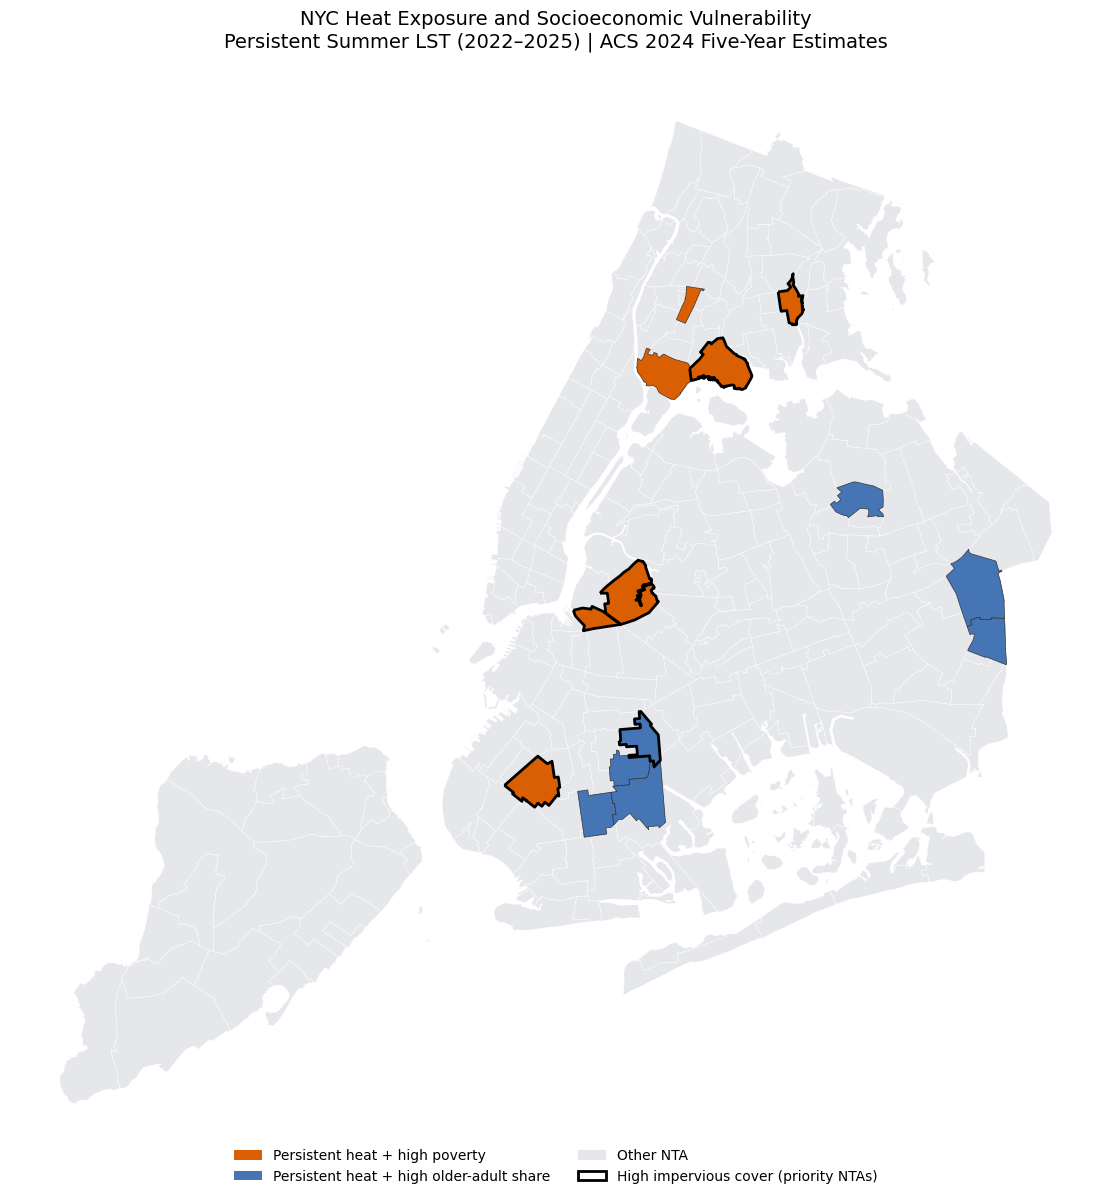

In [ ]:

import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# Build classifications from the 197 standard NTAs
map_data = residential_socioeconomic[
    [
        "nta2020",
        "Persistent_Hotspot",
        "High_Poverty",
        "High_Older_Adult"
    ]
].copy()

map_data["Priority_Type"] = "Other NTA"

map_data.loc[
    map_data["Persistent_Hotspot"]
    & map_data["High_Poverty"],
    "Priority_Type"
] = "Persistent heat + high poverty"

map_data.loc[
    map_data["Persistent_Hotspot"]
    & map_data["High_Older_Adult"],
    "Priority_Type"
] = "Persistent heat + high older-adult share"

# Join classifications and impervious data to polygons
map_gdf = (
    nta_gdf.merge(
        map_data,
        on="nta2020",
        how="left",
        validate="one_to_one"
    )
    .merge(
        impervious_df[
            ["nta2020", "Impervious_Percent"]
        ],
        on="nta2020",
        how="left",
        validate="one_to_one"
    )
)

map_gdf = map_gdf.to_crs("EPSG:2263")

colors = {
    "Persistent heat + high poverty": "#D95F02",
    "Persistent heat + high older-adult share": "#4575B4"
}

fig, ax = plt.subplots(figsize=(12, 12))

# Background neighborhoods
map_gdf.plot(
    ax=ax,
    color="#E5E7EB",
    edgecolor="white",
    linewidth=0.3
)

# Highlight priority categories
for category, color in colors.items():
    map_gdf[
        map_gdf["Priority_Type"] == category
    ].plot(
        ax=ax,
        color=color,
        edgecolor="#333333",
        linewidth=0.5
    )

# Outline priority neighborhoods with high impervious cover
high_imp_priority = map_gdf[
    map_gdf["Priority_Type"].isin(colors.keys())
    & (map_gdf["Impervious_Percent"] >= impervious_threshold)
]

high_imp_priority.boundary.plot(
    ax=ax,
    color="black",
    linewidth=2
)

legend_items = [
    Patch(facecolor="#D95F02",
          label="Persistent heat + high poverty"),
    Patch(facecolor="#4575B4",
          label="Persistent heat + high older-adult share"),
    Patch(facecolor="#E5E7EB",
          label="Other NTA"),
    Patch(facecolor="none", edgecolor="black",
          linewidth=2,
          label="High impervious cover (priority NTAs)")
]

ax.legend(
    handles=legend_items,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.04),
    frameon=False,
    ncol=2
)

ax.set_title(
    "NYC Heat Exposure and Socioeconomic Vulnerability\n"
    "Persistent Summer LST (2022–2025) | ACS 2024 Five-Year Estimates",
    fontsize=14,
    pad=18
)

ax.set_axis_off()
plt.tight_layout()
plt.show()


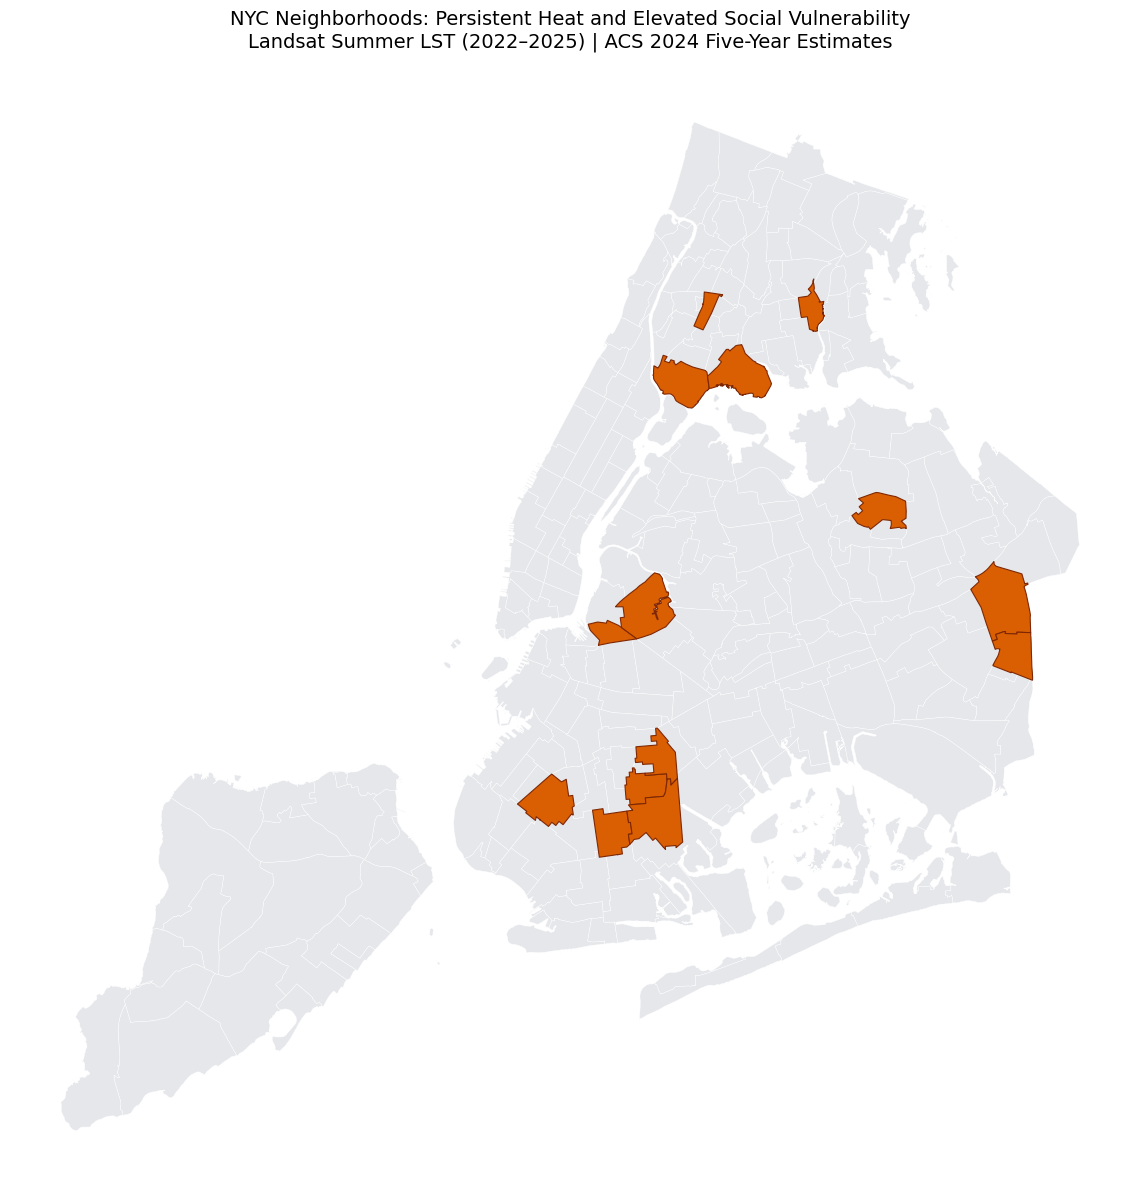

In [ ]:

import geopandas as gpd
import matplotlib.pyplot as plt

# Attach priority classifications to NTA polygons
priority_codes = set(priority_neighborhoods["nta2020"])

nta_map = nta_gdf.copy()

nta_map["Priority_Status"] = nta_map["nta2020"].apply(
    lambda code: (
        "Heat + social vulnerability"
        if code in priority_codes
        else "Other NTA"
    )
)

# Use a projected CRS for plotting
nta_map = nta_map.to_crs("EPSG:2263")

fig, ax = plt.subplots(figsize=(12, 12))

nta_map.plot(
    ax=ax,
    color="#E5E7EB",
    edgecolor="white",
    linewidth=0.3
)

nta_map[
    nta_map["Priority_Status"]
    == "Heat + social vulnerability"
].plot(
    ax=ax,
    color="#D95F02",
    edgecolor="#7F2704",
    linewidth=0.8
)

ax.set_title(
    "NYC Neighborhoods: Persistent Heat and Elevated Social Vulnerability\n"
    "Landsat Summer LST (2022–2025) | ACS 2024 Five-Year Estimates",
    fontsize=14,
    pad=18
)

ax.set_axis_off()
plt.tight_layout()
plt.show()


In [ ]:

# Add 2021 impervious surface coverage
priority_infrastructure = priority_neighborhoods.merge(
    impervious_df[
        ["nta2020", "Impervious_Percent"]
    ],
    on="nta2020",
    how="left",
    validate="one_to_one"
)

# Compare against the citywide 75th percentile
priority_infrastructure["High_Impervious"] = (
    priority_infrastructure["Impervious_Percent"]
    >= impervious_threshold
)

print("Priority neighborhoods:", len(priority_infrastructure))

print("\nPriority neighborhoods with high impervious cover:")
print(priority_infrastructure["High_Impervious"].sum())

print("\nNeighborhood comparison:")
print(
    priority_infrastructure[
        [
            "ntaname",
            "boroname",
            "Avg_LST_2022_2025",
            "Poverty_Rate",
            "Percent_65_Plus",
            "Impervious_Percent",
            "High_Impervious"
        ]
    ].round(2).to_string(index=False)
)


Priority neighborhoods: 14

Priority neighborhoods with high impervious cover:
6

Neighborhood comparison:
                           ntaname boroname  Avg_LST_2022_2025  Poverty_Rate  Percent_65_Plus  Impervious_Percent  High_Impervious
                    Queens Village   Queens              41.11          9.55            21.36               75.57            False
            East Flatbush-Farragut Brooklyn              41.05         13.00            22.10               85.17            False
                 East Williamsburg Brooklyn              41.03         24.05            13.30               91.95             True
                      Borough Park Brooklyn              41.00         33.70             9.78               90.48             True
                         Flatlands Brooklyn              40.63         11.60            20.49               85.91            False
                   Cambria Heights   Queens              40.62          7.58            24.04              

In [ ]:

# Identify neighborhoods with persistent heat and
# at least one elevated socioeconomic vulnerability indicator
priority_neighborhoods = (
    residential_socioeconomic[
        residential_socioeconomic["Persistent_Hotspot"]
        & residential_socioeconomic["Elevated_Social_Vulnerability"]
    ]
    .copy()
)

# Count elevated indicators, without assigning arbitrary weights
priority_neighborhoods["Elevated_Indicator_Count"] = (
    priority_neighborhoods["High_Poverty"].astype(int)
    + priority_neighborhoods["High_Older_Adult"].astype(int)
)

priority_neighborhoods = priority_neighborhoods.sort_values(
    ["Elevated_Indicator_Count", "Avg_LST_2022_2025"],
    ascending=[False, False]
)

print("Priority neighborhoods:", len(priority_neighborhoods))

print(
    priority_neighborhoods[
        [
            "ntaname",
            "boroname",
            "Avg_LST_2022_2025",
            "Years_In_Top_Quartile",
            "Poverty_Rate",
            "Percent_65_Plus",
            "High_Poverty",
            "High_Older_Adult"
        ]
    ].round(2).to_string(index=False)
)


Priority neighborhoods: 14
                           ntaname boroname  Avg_LST_2022_2025  Years_In_Top_Quartile  Poverty_Rate  Percent_65_Plus  High_Poverty  High_Older_Adult
                    Queens Village   Queens              41.11                      4          9.55            21.36         False              True
            East Flatbush-Farragut Brooklyn              41.05                      4         13.00            22.10         False              True
                 East Williamsburg Brooklyn              41.03                      4         24.05            13.30          True             False
                      Borough Park Brooklyn              41.00                      4         33.70             9.78          True             False
                         Flatlands Brooklyn              40.63                      4         11.60            20.49         False              True
                   Cambria Heights   Queens              40.62                 

In [ ]:

# Calculate thresholds using all standard NTAs
poverty_threshold = (
    residential_socioeconomic["Poverty_Rate"].quantile(0.75)
)

older_adult_threshold = (
    residential_socioeconomic["Percent_65_Plus"].quantile(0.75)
)

print(f"High-poverty threshold: {poverty_threshold:.2f}%")
print(f"High-older-adult threshold: {older_adult_threshold:.2f}%")

# Flag elevated socioeconomic vulnerability
residential_socioeconomic["High_Poverty"] = (
    residential_socioeconomic["Poverty_Rate"] >= poverty_threshold
)

residential_socioeconomic["High_Older_Adult"] = (
    residential_socioeconomic["Percent_65_Plus"] >= older_adult_threshold
)

residential_socioeconomic["Elevated_Social_Vulnerability"] = (
    residential_socioeconomic["High_Poverty"]
    | residential_socioeconomic["High_Older_Adult"]
)

# Cross-tabulate persistent heat and social vulnerability
print("\nHeat and vulnerability overlap:")
print(
    pd.crosstab(
        residential_socioeconomic["Persistent_Hotspot"],
        residential_socioeconomic["Elevated_Social_Vulnerability"],
        margins=True
    )
)


High-poverty threshold: 23.42%
High-older-adult threshold: 19.82%

Heat and vulnerability overlap:
Elevated_Social_Vulnerability  False  True  All
Persistent_Hotspot                             
False                             80    81  161
True                              22    14   36
All                              102    95  197


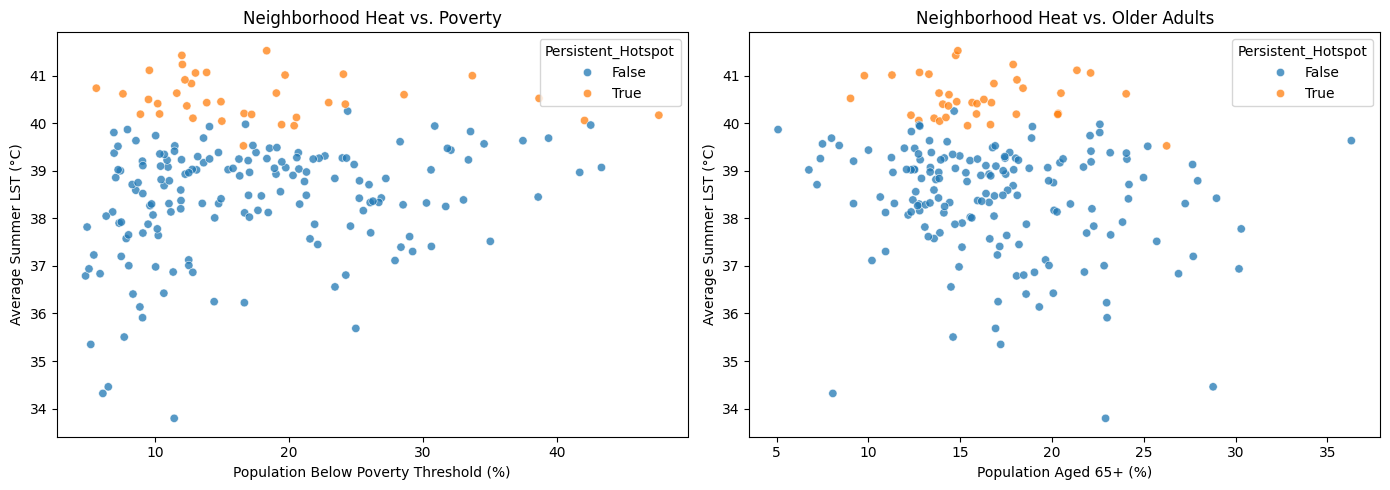

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(
    data=residential_socioeconomic,
    x="Poverty_Rate",
    y="Avg_LST_2022_2025",
    hue="Persistent_Hotspot",
    ax=axes[0],
    alpha=0.75
)

axes[0].set_title("Neighborhood Heat vs. Poverty")
axes[0].set_xlabel("Population Below Poverty Threshold (%)")
axes[0].set_ylabel("Average Summer LST (°C)")

sns.scatterplot(
    data=residential_socioeconomic,
    x="Percent_65_Plus",
    y="Avg_LST_2022_2025",
    hue="Persistent_Hotspot",
    ax=axes[1],
    alpha=0.75
)

axes[1].set_title("Neighborhood Heat vs. Older Adults")
axes[1].set_xlabel("Population Aged 65+ (%)")
axes[1].set_ylabel("Average Summer LST (°C)")

plt.tight_layout()
plt.show()


In [ ]:

# Build one record per standard NTA
residential_socioeconomic = (
    neighborhood_4yr.merge(
        nta_socioeconomic[
            [
                "nta2020",
                "Poverty_Rate",
                "Percent_65_Plus",
                "Total_Population"
            ]
        ],
        on="nta2020",
        how="left",
        validate="one_to_one"
    )
    .merge(
        heat_persistence[
            ["nta2020", "Years_In_Top_Quartile"]
        ],
        on="nta2020",
        how="left",
        validate="one_to_one"
    )
)

residential_socioeconomic["Persistent_Hotspot"] = (
    residential_socioeconomic["Years_In_Top_Quartile"] >= 3
)

print("Standard NTAs:", len(residential_socioeconomic))
print(
    "Persistent hotspots:",
    residential_socioeconomic["Persistent_Hotspot"].sum()
)

comparison = (
    residential_socioeconomic
    .groupby("Persistent_Hotspot")[
        ["Poverty_Rate", "Percent_65_Plus", "Avg_LST_2022_2025"]
    ]
    .mean()
    .round(2)
)

print("\nNeighborhood group averages:")
print(comparison)

print("\nMissing socioeconomic values:")
print(
    residential_socioeconomic[
        ["Poverty_Rate", "Percent_65_Plus"]
    ].isna().sum()
)


Standard NTAs: 197
Persistent hotspots: 36

Neighborhood group averages:
                    Poverty_Rate  Percent_65_Plus  Avg_LST_2022_2025
Persistent_Hotspot                                                  
False                      17.36            16.98              38.37
True                       17.99            16.13              40.54

Missing socioeconomic values:
Poverty_Rate       0
Percent_65_Plus    0
dtype: int64


In [ ]:

# Count missing and zero-denominator tract estimates
acs_nta["Missing_Poverty_Data"] = (
    acs_nta["B17001_001E"].isna()
    | acs_nta["B17001_002E"].isna()
)

acs_nta["Missing_Age_Data"] = (
    acs_nta["B01001_001E"].isna()
    | acs_nta["Population_65_Plus"].isna()
)

nta_quality = (
    acs_nta.groupby("ntacode", as_index=False)
    .agg(
        Tract_Count=("geoid", "count"),
        Missing_Poverty_Tracts=("Missing_Poverty_Data", "sum"),
        Missing_Age_Tracts=("Missing_Age_Data", "sum"),
        Poverty_Universe=("B17001_001E", "sum"),
        Total_Population=("B01001_001E", "sum")
    )
)

# Replace missing aggregate counts where every tract is missing
# with NaN rather than interpreting them as zero.
for col in ["Poverty_Universe", "Total_Population"]:
    nta_quality[col] = (
        acs_nta.groupby("ntacode")[col.replace(
            "Poverty_Universe", "B17001_001E"
        ).replace(
            "Total_Population", "B01001_001E"
        )].sum(min_count=1).values
    )

print("NTAs with missing tract estimates:")
print(
    (nta_quality[
        ["Missing_Poverty_Tracts", "Missing_Age_Tracts"]
    ] > 0).sum()
)

print("\nNTAs with no eligible poverty population:")
print((nta_quality["Poverty_Universe"] <= 0).sum())

print("\nNTAs with no estimated population:")
print((nta_quality["Total_Population"] <= 0).sum())

print("\nSample of affected NTAs:")
print(
    nta_quality[
        (nta_quality["Missing_Poverty_Tracts"] > 0)
        | (nta_quality["Missing_Age_Tracts"] > 0)
    ].head(15).to_string(index=False)
)


NTAs with missing tract estimates:
Missing_Poverty_Tracts    0
Missing_Age_Tracts        0
dtype: int64

NTAs with no eligible poverty population:
50

NTAs with no estimated population:
48

Sample of affected NTAs:
Empty DataFrame
Columns: [ntacode, Tract_Count, Missing_Poverty_Tracts, Missing_Age_Tracts, Poverty_Universe, Total_Population]
Index: []


In [ ]:

# Merge socioeconomic data with persistent heat hotspots
heat_vulnerability_df = citywide_persistent_hotspots.merge(
    nta_socioeconomic[
        [
            "nta2020",
            "Total_Population",
            "Poverty_Rate",
            "Percent_65_Plus"
        ]
    ],
    on="nta2020",
    how="left",
    validate="one_to_one"
)

print(
    heat_vulnerability_df[
        [
            "ntaname",
            "boroname",
            "Avg_LST_2022_2025",
            "Years_In_Top_Quartile",
            "Poverty_Rate",
            "Percent_65_Plus"
        ]
    ].head(15).round(2).to_string(index=False)
)

print("\nMissing socioeconomic values:")
print(
    heat_vulnerability_df[
        ["Poverty_Rate", "Percent_65_Plus"]
    ].isna().sum()
)


               ntaname      boroname  Avg_LST_2022_2025  Years_In_Top_Quartile  Poverty_Rate  Percent_65_Plus
               Jamaica        Queens              41.52                      4         18.32            14.87
   South Richmond Hill        Queens              41.42                      4         11.98            14.76
      South Ozone Park        Queens              41.23                      4         12.02            17.88
        Queens Village        Queens              41.11                      4          9.55            21.36
         South Jamaica        Queens              41.06                      4         13.83            12.79
East Flatbush-Farragut      Brooklyn              41.05                      4         13.00            22.10
     East Williamsburg      Brooklyn              41.03                      4         24.05            13.30
         Port Richmond Staten Island              41.01                      4         19.70            11.28
          

In [ ]:

# Aggregate tract population counts to NTAs
nta_socioeconomic = (
    acs_nta.groupby("ntacode", as_index=False)
    .agg(
        Poverty_Universe=("B17001_001E", "sum"),
        Population_Below_Poverty=("B17001_002E", "sum"),
        Total_Population=("B01001_001E", "sum"),
        Population_65_Plus=("Population_65_Plus", "sum")
    )
)

# Calculate NTA-level rates
nta_socioeconomic["Poverty_Rate"] = (
    nta_socioeconomic["Population_Below_Poverty"]
    / nta_socioeconomic["Poverty_Universe"].replace(0, np.nan)
    * 100
)

nta_socioeconomic["Percent_65_Plus"] = (
    nta_socioeconomic["Population_65_Plus"]
    / nta_socioeconomic["Total_Population"].replace(0, np.nan)
    * 100
)

# Rename geographic identifier for compatibility
nta_socioeconomic = nta_socioeconomic.rename(
    columns={"ntacode": "nta2020"}
)

print("Total NTAs:", len(nta_socioeconomic))

print(
    nta_socioeconomic[
        [
            "nta2020",
            "Total_Population",
            "Poverty_Rate",
            "Percent_65_Plus"
        ]
    ].head(10).round(2).to_string(index=False)
)

print("\nNTA socioeconomic summary:")
print(
    nta_socioeconomic[
        ["Poverty_Rate", "Percent_65_Plus"]
    ].describe().round(2)
)


Total NTAs: 262
nta2020  Total_Population  Poverty_Rate  Percent_65_Plus
 BK0101             39784          9.03             9.19
 BK0102             66612         13.08             6.76
 BK0103             50948         38.68             9.03
 BK0104             50775         24.05            13.30
 BK0201             26031          4.78            18.07
 BK0202             39977         14.73             9.19
 BK0203             33180         16.67            14.11
 BK0204             29205          9.82            12.17
 BK0261                 0           NaN              NaN
 BK0301             90068         25.97             7.20

NTA socioeconomic summary:
       Poverty_Rate  Percent_65_Plus
count        212.00           214.00
mean          17.70            16.30
std           11.75             6.66
min            0.00             0.00
25%            9.97            12.84
50%           14.72            15.93
75%           23.42            19.81
max           79.26            42

In [ ]:

# Confirm geographic identifier coverage
acs_geoids = set(acs_df["geoid"])
crosswalk_geoids = set(crosswalk_clean["geoid"])

print("ACS tracts:", len(acs_geoids))
print("Crosswalk tracts:", len(crosswalk_geoids))

print(
    "Matching tract GEOIDs:",
    len(acs_geoids & crosswalk_geoids)
)

print(
    "ACS tracts without crosswalk match:",
    len(acs_geoids - crosswalk_geoids)
)

# Merge ACS counts with NTA crosswalk
acs_nta = crosswalk_clean.merge(
    acs_df[
        [
            "geoid",
            "B17001_001E",
            "B17001_002E",
            "B01001_001E",
            "Population_65_Plus"
        ]
    ],
    on="geoid",
    how="left",
    validate="one_to_one"
)

print("\nMerged records:", len(acs_nta))

print(
    "Unmatched ACS records:",
    acs_nta["B01001_001E"].isna().sum()
)


ACS tracts: 2327
Crosswalk tracts: 2327
Matching tract GEOIDs: 2327
ACS tracts without crosswalk match: 0

Merged records: 2327
Unmatched ACS records: 0


In [ ]:

import numpy as np

# Create Census tract GEOID
acs_df["geoid"] = (
    acs_df["state"]
    + acs_df["county"]
    + acs_df["tract"]
)

# Convert Census estimates to numeric
estimate_columns = [
    "B17001_001E",
    "B17001_002E",
    "B01001_001E"
] + age_65_variables

for col in estimate_columns:
    acs_df[col] = pd.to_numeric(
        acs_df[col],
        errors="coerce"
    )

# Replace Census missing-value codes with NaN
acs_df[estimate_columns] = (
    acs_df[estimate_columns]
    .mask(acs_df[estimate_columns] < 0)
)

# Calculate population aged 65+
acs_df["Population_65_Plus"] = (
    acs_df[age_65_variables].sum(
        axis=1,
        min_count=len(age_65_variables)
    )
)

# Calculate poverty rate
acs_df["Poverty_Rate"] = (
    acs_df["B17001_002E"]
    / acs_df["B17001_001E"].replace(0, np.nan)
    * 100
)

# Calculate percentage aged 65+
acs_df["Percent_65_Plus"] = (
    acs_df["Population_65_Plus"]
    / acs_df["B01001_001E"].replace(0, np.nan)
    * 100
)

print(
    acs_df[
        ["geoid", "Poverty_Rate", "Percent_65_Plus"]
    ].head(10).round(2).to_string(index=False)
)

print("\nMissing tract-level rates:")
print(
    acs_df[
        ["Poverty_Rate", "Percent_65_Plus"]
    ].isna().sum()
)


      geoid  Poverty_Rate  Percent_65_Plus
36005000100           NaN             3.08
36005000200         12.88            14.88
36005000400          4.47            14.06
36005001600         15.16            21.65
36005001901         22.45             3.23
36005001902         39.56             3.17
36005001903           NaN              NaN
36005001904           NaN              NaN
36005002001         52.39            15.43
36005002002         42.97            32.22

Missing tract-level rates:
Poverty_Rate       88
Percent_65_Plus    84
dtype: int64


In [ ]:

# Create the 11-digit Census tract GEOID
acs_df["geoid"] = (
    acs_df["state"]
    + acs_df["county"]
    + acs_df["tract"]
)

# Convert estimate columns to numeric
estimate_columns = [
    "B17001_001E",
    "B17001_002E",
    "B01001_001E"
] + age_65_variables

for col in estimate_columns:
    acs_df[col] = pd.to_numeric(
        acs_df[col],
        errors="coerce"
    )

# Census missing-value sentinels should not be treated
# as actual population counts.
acs_df[estimate_columns] = (
    acs_df[estimate_columns]
    .mask(acs_df[estimate_columns] < 0)
)

# Calculate total population aged 65+
acs_df["Population_65_Plus"] = (
    acs_df[age_65_variables].sum(
        axis=1,
        min_count=len(age_65_variables)
    )
)

# Calculate tract poverty rate
acs_df["Poverty_Rate"] = (
    acs_df["B17001_002E"]
    / acs_df["B17001_001E"].replace(0, float("nan"))
    * 100
)

# Calculate tract percentage aged 65+
acs_df["Percent_65_Plus"] = (
    acs_df["Population_65_Plus"]
    / acs_df["B01001_001E"].replace(0, float("nan"))
    * 100
)

print(
    acs_df[
        [
            "geoid",
            "Poverty_Rate",
            "Percent_65_Plus"
        ]
    ].head(10).round(2)
)

print("\nMissing values:")
print(
    acs_df[
        ["Poverty_Rate", "Percent_65_Plus"]
    ].isna().sum()
)


         geoid  Poverty_Rate  Percent_65_Plus
0  36005000100           NaN             3.08
1  36005000200         12.88            14.88
2  36005000400          4.47            14.06
3  36005001600         15.16            21.65
4  36005001901         22.45             3.23
5  36005001902         39.56             3.17
6  36005001903           NaN              NaN
7  36005001904           NaN              NaN
8  36005002001         52.39            15.43
9  36005002002         42.97            32.22

Missing values:
Poverty_Rate       88
Percent_65_Plus    84
dtype: int64


In [ ]:

import requests
import pandas as pd
from getpass import getpass

# Enter your Census API key securely
census_api_key = getpass("Enter your Census API key: ")

base_url = "https://api.census.gov/data/2024/acs/acs5"

nyc_counties = {
    "005": "Bronx",
    "047": "Brooklyn",
    "061": "Manhattan",
    "081": "Queens",
    "085": "Staten Island"
}

age_65_variables = (
    [f"B01001_{i:03d}E" for i in range(20, 26)]
    + [f"B01001_{i:03d}E" for i in range(44, 50)]
)

variables = [
    "NAME",
    "B17001_001E",
    "B17001_002E",
    "B01001_001E"
] + age_65_variables

county_data = []

for county_code, borough in nyc_counties.items():

    params = {
        "get": ",".join(variables),
        "for": "tract:*",
        "in": f"state:36 county:{county_code}",
        "key": census_api_key
    }

    response = requests.get(
        base_url,
        params=params,
        timeout=60
    )

    response.raise_for_status()

    # Verify that the API returned JSON, not HTML
    if "json" not in response.headers.get(
        "Content-Type", ""
    ).lower():
        raise RuntimeError(
            f"{borough}: Unexpected response: "
            f"{response.text[:300]}"
        )

    data = response.json()

    county_df = pd.DataFrame(
        data[1:],
        columns=data[0]
    )

    county_data.append(county_df)

    print(f"{borough}: {len(county_df)} tracts")

acs_df = pd.concat(
    county_data,
    ignore_index=True
)

print("\nTotal ACS tract records:", len(acs_df))
print(acs_df.head())


Enter your Census API key: ··········
Bronx: 361 tracts
Brooklyn: 805 tracts
Manhattan: 310 tracts
Queens: 725 tracts
Staten Island: 126 tracts

Total ACS tract records: 2327
                                         NAME B17001_001E B17001_002E  \
0      Census Tract 1; Bronx County; New York           0           0   
1      Census Tract 2; Bronx County; New York        5061         652   
2      Census Tract 4; Bronx County; New York        6649         297   
3     Census Tract 16; Bronx County; New York        5329         808   
4  Census Tract 19.01; Bronx County; New York        2258         507   

  B01001_001E B01001_020E B01001_021E B01001_022E B01001_023E B01001_024E  \
0        2950          11          35           5           9          31   
1        5061          25         124          20          48           0   
2        6649          32         321          81          39           0   
3        5611           7         128         160          41          12   
4

In [ ]:

# Keep only the columns needed for our analysis
crosswalk_clean = tract_nta_crosswalk[
    ["geoid", "ntacode", "ntaname", "boroname"]
].copy()

# Standardize geographic identifiers
crosswalk_clean["geoid"] = (
    crosswalk_clean["geoid"].astype(str).str.zfill(11)
)

crosswalk_clean["ntacode"] = (
    crosswalk_clean["ntacode"].astype(str).str.strip()
)

# Check for duplicate Census tract identifiers
print(
    "Duplicate tract GEOIDs:",
    crosswalk_clean["geoid"].duplicated().sum()
)

# Check whether crosswalk NTA codes match our polygons
nta_codes = set(nta_gdf["nta2020"].astype(str))

crosswalk_codes = set(crosswalk_clean["ntacode"])

print(
    "Crosswalk NTA codes:",
    len(crosswalk_codes)
)

print(
    "Matching NTA codes:",
    len(crosswalk_codes & nta_codes)
)

print(
    "Unmatched crosswalk NTA codes:",
    sorted(crosswalk_codes - nta_codes)
)


Duplicate tract GEOIDs: 0
Crosswalk NTA codes: 262
Matching NTA codes: 262
Unmatched crosswalk NTA codes: []


In [ ]:

import pandas as pd

# Official NYC Department of City Planning crosswalk
url = (
    "https://data.cityofnewyork.us/"
    "resource/hm78-6dwm.csv?$limit=5000"
)

tract_nta_crosswalk = pd.read_csv(
    url,
    dtype=str
)

print("Rows:", len(tract_nta_crosswalk))

print("\nColumns:")
print(tract_nta_crosswalk.columns.tolist())

print("\nFirst five records:")
print(tract_nta_crosswalk.head().to_string(index=False))


Rows: 2327

Columns:
['geoid', 'countyfips', 'borocode', 'boroname', 'boroct2020', 'ct2020', 'ctlabel', 'ntacode', 'ntatype', 'ntaname', 'ntaabbrev', 'cdtacode', 'cdtatype', 'cdtaname']

First five records:
      geoid countyfips borocode boroname boroct2020 ct2020 ctlabel ntacode ntatype                ntaname ntaabbrev cdtacode cdtatype                                                 cdtaname
36005001901        005        2    Bronx    2001901 001901   19.01  BX0101       0 Mott Haven-Port Morris    MttHvn     BX01       CD BX01 Melrose-Mott Haven-Port Morris (CD 1 Approximation)
36005001902        005        2    Bronx    2001902 001902   19.02  BX0101       0 Mott Haven-Port Morris    MttHvn     BX01       CD BX01 Melrose-Mott Haven-Port Morris (CD 1 Approximation)
36005001903        005        2    Bronx    2001903 001903   19.03  BX0101       0 Mott Haven-Port Morris    MttHvn     BX01       CD BX01 Melrose-Mott Haven-Port Morris (CD 1 Approximation)
36005002300        005       

In [ ]:

# Inspect NTA geography and identifiers
print("NTA columns:")
print(nta_gdf.columns.tolist())

print("\nNTA geography sample:")
print(
    nta_gdf[
        ["nta2020", "ntaname", "boroname"]
    ].head(10).to_string(index=False)
)

print("\nTotal NTA polygons:", len(nta_gdf))

print("\nCoordinate reference system:")
print(nta_gdf.crs)


NTA columns:
[':id', ':version', ':created_at', ':updated_at', 'borocode', 'boroname', 'countyfips', 'nta2020', 'ntaname', 'ntaabbrev', 'ntatype', 'cdta2020', 'cdtaname', 'shape_leng', 'shape_area', 'geometry']

NTA geography sample:
nta2020                             ntaname boroname
 BK0101                          Greenpoint Brooklyn
 BK0102                        Williamsburg Brooklyn
 BK0103                  South Williamsburg Brooklyn
 BK0104                   East Williamsburg Brooklyn
 BK0201                    Brooklyn Heights Brooklyn
 BK0202 Downtown Brooklyn-DUMBO-Boerum Hill Brooklyn
 BK0203                         Fort Greene Brooklyn
 BK0204                        Clinton Hill Brooklyn
 BK0261                  Brooklyn Navy Yard Brooklyn
 BK0301           Bedford-Stuyvesant (West) Brooklyn

Total NTA polygons: 262

Coordinate reference system:
EPSG:4326


In [ ]:

# Apply high-impervious threshold to all persistent hotspots
persistent_high_impervious = citywide_persistent_hotspots[
    citywide_persistent_hotspots["Impervious_Percent"]
    >= impervious_threshold
].copy()

print(
    "Persistent heat + high impervious neighborhoods:",
    len(persistent_high_impervious)
)

print(
    persistent_high_impervious[
        [
            "ntaname",
            "boroname",
            "Avg_LST_2022_2025",
            "Impervious_Percent",
            "Years_In_Top_Quartile"
        ]
    ].round(2).to_string(index=False)
)


Persistent heat + high impervious neighborhoods: 13
                   ntaname boroname  Avg_LST_2022_2025  Impervious_Percent  Years_In_Top_Quartile
                   Jamaica   Queens              41.52               88.81                      4
         East Williamsburg Brooklyn              41.03               91.95                      4
              Borough Park Brooklyn              41.00               90.48                      4
                   Maspeth   Queens              40.83               90.58                      4
               Hunts Point    Bronx              40.60               89.35                      4
        Westchester Square    Bronx              40.40               88.28                      4
       East Flatbush-Rugby Brooklyn              40.18               88.09                      4
                    Corona   Queens              40.12               89.47                      4
        Ozone Park (North)   Queens              40.63            

In [ ]:

# Combine citywide heat persistence with impervious coverage
citywide_persistence = heat_persistence.merge(
    impervious_df,
    on="nta2020",
    how="left",
    validate="one_to_one"
)

# Add four-year average temperatures
citywide_persistence = citywide_persistence.merge(
    neighborhood_4yr[
        ["nta2020", "Avg_LST_2022_2025"]
    ],
    on="nta2020",
    how="left",
    validate="one_to_one"
)

# Identify all neighborhoods hot in 3 or more summers
citywide_persistent_hotspots = citywide_persistence[
    citywide_persistence["Years_In_Top_Quartile"] >= 3
].sort_values(
    ["Years_In_Top_Quartile", "Avg_LST_2022_2025"],
    ascending=False
)

print(
    "Total citywide persistent heat hotspots:",
    len(citywide_persistent_hotspots)
)

print(
    citywide_persistent_hotspots[
        [
            "ntaname",
            "boroname",
            "Avg_LST_2022_2025",
            "Impervious_Percent",
            "Years_In_Top_Quartile"
        ]
    ].head(20).round(2).to_string(index=False)
)


Total citywide persistent heat hotspots: 36
                                     ntaname      boroname  Avg_LST_2022_2025  Impervious_Percent  Years_In_Top_Quartile
                                     Jamaica        Queens              41.52               88.81                      4
                         South Richmond Hill        Queens              41.42               86.76                      4
                            South Ozone Park        Queens              41.23               82.80                      4
                              Queens Village        Queens              41.11               75.57                      4
                               South Jamaica        Queens              41.06               77.27                      4
                      East Flatbush-Farragut      Brooklyn              41.05               85.17                      4
                           East Williamsburg      Brooklyn              41.03               91.95            

In [ ]:

# Count flagged neighborhoods by heat persistence
print(
    priority_persistence[
        "Years_In_Top_Quartile"
    ].value_counts().sort_index()
)

# Display neighborhoods consistently in the hottest quartile
persistent_hotspots = priority_persistence[
    priority_persistence["Years_In_Top_Quartile"] >= 3
].sort_values(
    ["Years_In_Top_Quartile", "Avg_LST_2022_2025"],
    ascending=False
)

print("\nPersistent heat hotspots (3–4 years):")
print(
    persistent_hotspots[
        [
            "ntaname",
            "boroname",
            "Avg_LST_2022_2025",
            "Impervious_Percent",
            "Years_In_Top_Quartile"
        ]
    ].round(2).to_string(index=False)
)


Years_In_Top_Quartile
1    4
2    2
3    5
4    8
Name: count, dtype: int64

Persistent heat hotspots (3–4 years):
                   ntaname boroname  Avg_LST_2022_2025  Impervious_Percent  Years_In_Top_Quartile
                   Jamaica   Queens              41.52               88.81                      4
         East Williamsburg Brooklyn              41.03               91.95                      4
              Borough Park Brooklyn              41.00               90.48                      4
                   Maspeth   Queens              40.83               90.58                      4
               Hunts Point    Bronx              40.60               89.35                      4
        Westchester Square    Bronx              40.40               88.28                      4
       East Flatbush-Rugby Brooklyn              40.18               88.09                      4
                    Corona   Queens              40.12               89.47                      4
   

In [ ]:

# Use all standard neighborhoods
heat_history = residential_df.copy()

# Calculate each year's 75th-percentile LST
heat_history["Annual_Heat_Threshold"] = (
    heat_history.groupby("Year")["Summer_LST_C"]
    .transform(lambda x: x.quantile(0.75))
)

# Flag whether each neighborhood is in the hottest quartile
heat_history["Top_Heat_Quartile"] = (
    heat_history["Summer_LST_C"]
    >= heat_history["Annual_Heat_Threshold"]
)

# Count hot years for each neighborhood
heat_persistence = (
    heat_history
    .groupby(["nta2020", "ntaname", "boroname"], as_index=False)
    .agg(
        Years_In_Top_Quartile=(
            "Top_Heat_Quartile", "sum"
        ),
        Years_Observed=("Year", "nunique")
    )
)

# Add persistence to our 2025 priority neighborhoods
priority_persistence = priority_4yr.merge(
    heat_persistence[
        ["nta2020", "Years_In_Top_Quartile"]
    ],
    on="nta2020",
    how="left",
    validate="one_to_one"
)

print(
    priority_persistence[
        [
            "ntaname",
            "boroname",
            "Avg_LST_2022_2025",
            "Impervious_Percent",
            "Years_In_Top_Quartile"
        ]
    ].sort_values(
        ["Years_In_Top_Quartile", "Avg_LST_2022_2025"],
        ascending=False
    ).round(2).to_string(index=False)
)


                                     ntaname boroname  Avg_LST_2022_2025  Impervious_Percent  Years_In_Top_Quartile
                                     Jamaica   Queens              41.52               88.81                      4
                           East Williamsburg Brooklyn              41.03               91.95                      4
                                Borough Park Brooklyn              41.00               90.48                      4
                                     Maspeth   Queens              40.83               90.58                      4
                                 Hunts Point    Bronx              40.60               89.35                      4
                          Westchester Square    Bronx              40.40               88.28                      4
                         East Flatbush-Rugby Brooklyn              40.18               88.09                      4
                                      Corona   Queens              40.12

In [ ]:

# Get IDs of neighborhoods flagged in 2025
flagged_nta_ids = priority_neighborhoods["nta2020"].unique()

# Get all four years for those neighborhoods
priority_history = residential_df[
    residential_df["nta2020"].isin(flagged_nta_ids)
].copy()

# Calculate four-year summary
priority_4yr = (
    priority_history
    .groupby(
        ["nta2020", "ntaname", "boroname"],
        as_index=False
    )
    .agg(
        Avg_LST_2022_2025=("Summer_LST_C", "mean"),
        Min_LST=("Summer_LST_C", "min"),
        Max_LST=("Summer_LST_C", "max"),
        Years_Observed=("Year", "nunique")
    )
)

# Merge impervious coverage
priority_4yr = priority_4yr.merge(
    impervious_df,
    on="nta2020",
    how="left",
    validate="one_to_one"
)

print(
    priority_4yr.sort_values(
        "Avg_LST_2022_2025",
        ascending=False
    ).round(2).to_string(index=False)
)


nta2020                                      ntaname boroname  Avg_LST_2022_2025  Min_LST  Max_LST  Years_Observed  Impervious_Percent
 QN1201                                      Jamaica   Queens              41.52    40.46    42.03               4               88.81
 BK0104                            East Williamsburg Brooklyn              41.03    39.40    42.14               4               91.95
 BK1202                                 Borough Park Brooklyn              41.00    39.56    41.76               4               90.48
 QN0501                                      Maspeth   Queens              40.83    39.11    41.88               4               90.58
 QN0904                           Ozone Park (North)   Queens              40.63    39.49    42.19               4               89.50
 BX0201                                  Hunts Point    Bronx              40.60    40.15    41.01               4               89.35
 BK0103                           South Williamsburg Br

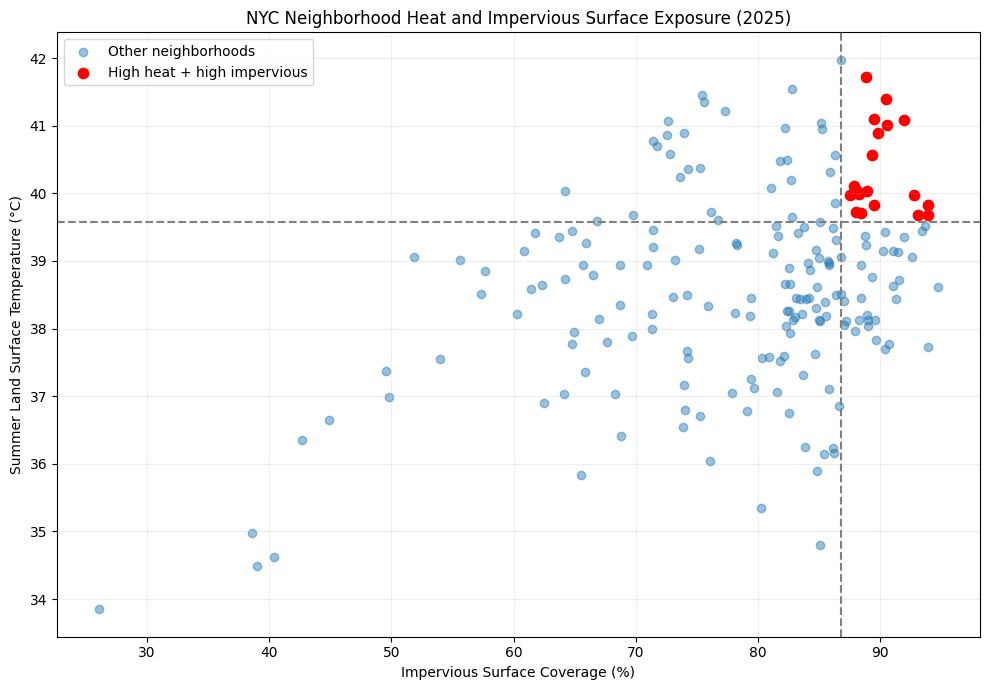

In [ ]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 7))

plt.scatter(
    priority_df["Impervious_Percent"],
    priority_df["Summer_LST_C"],
    alpha=0.45,
    label="Other neighborhoods"
)

plt.scatter(
    priority_neighborhoods["Impervious_Percent"],
    priority_neighborhoods["Summer_LST_C"],
    color="red",
    s=55,
    label="High heat + high impervious"
)

plt.axhline(
    heat_threshold,
    color="gray",
    linestyle="--"
)

plt.axvline(
    impervious_threshold,
    color="gray",
    linestyle="--"
)

plt.xlabel("Impervious Surface Coverage (%)")
plt.ylabel("Summer Land Surface Temperature (°C)")
plt.title("NYC Neighborhood Heat and Impervious Surface Exposure (2025)")

plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


In [ ]:

# Use standard neighborhoods in 2025
priority_df = infra_model_df.copy()

# Calculate 75th-percentile thresholds
heat_threshold = priority_df["Summer_LST_C"].quantile(0.75)
impervious_threshold = priority_df["Impervious_Percent"].quantile(0.75)

# Flag neighborhoods exceeding both thresholds
priority_df["High_Heat"] = (
    priority_df["Summer_LST_C"] >= heat_threshold
)

priority_df["High_Impervious"] = (
    priority_df["Impervious_Percent"] >= impervious_threshold
)

priority_df["Priority_Flag"] = (
    priority_df["High_Heat"]
    & priority_df["High_Impervious"]
)

# Display preliminary priority neighborhoods
priority_neighborhoods = (
    priority_df[priority_df["Priority_Flag"]]
    .sort_values("Summer_LST_C", ascending=False)
)

print("Heat threshold:", round(heat_threshold, 2), "°C")
print("Impervious threshold:", round(impervious_threshold, 2), "%")

print("\nNeighborhoods meeting both thresholds:")
print(
    priority_neighborhoods[
        [
            "ntaname",
            "boroname",
            "Summer_LST_C",
            "Impervious_Percent",
            "Mean_NDVI"
        ]
    ].round(2).to_string(index=False)
)

print("\nTotal priority neighborhoods:", len(priority_neighborhoods))


Heat threshold: 39.58 °C
Impervious threshold: 86.82 %

Neighborhoods meeting both thresholds:
                                     ntaname boroname  Summer_LST_C  Impervious_Percent  Mean_NDVI
                                     Jamaica   Queens         41.73               88.81       0.20
                                Borough Park Brooklyn         41.40               90.48       0.22
                          Ozone Park (North)   Queens         41.11               89.50       0.21
                           East Williamsburg Brooklyn         41.09               91.95       0.16
                                     Maspeth   Queens         41.01               90.58       0.17
                          South Williamsburg Brooklyn         40.90               89.83       0.21
                                 Hunts Point    Bronx         40.56               89.35       0.15
                                    Woodside   Queens         40.11               87.87       0.21
              

In [ ]:

print("NDVI-only model:")
print(
    model_ndvi.params["Mean_NDVI"],
    model_ndvi.pvalues["Mean_NDVI"]
)

print("\nImpervious-only model:")
print(
    model_impervious.params["Impervious_Percent"],
    model_impervious.pvalues["Impervious_Percent"]
)

print("\nCombined model:")
print(
    model_both.params[
        ["Mean_NDVI", "Impervious_Percent"]
    ]
)

print(
    model_both.pvalues[
        ["Mean_NDVI", "Impervious_Percent"]
    ]
)


NDVI-only model:
-6.372472942941103 2.8436383693737974e-07

Impervious-only model:
0.06833585585784849 4.239845569108829e-12

Combined model:
Mean_NDVI             4.273964
Impervious_Percent    0.102459
dtype: float64
Mean_NDVI             0.079010
Impervious_Percent    0.000003
dtype: float64


In [ ]:

import statsmodels.formula.api as smf
import pandas as pd

model_ndvi = smf.ols(
    "Summer_LST_C ~ Mean_NDVI + C(boroname)",
    data=infra_model_df
).fit(cov_type="HC3")

model_impervious = smf.ols(
    "Summer_LST_C ~ Impervious_Percent + C(boroname)",
    data=infra_model_df
).fit(cov_type="HC3")

model_both = model_infrastructure

model_summary = pd.DataFrame({
    "Model": [
        "NDVI + Borough",
        "Impervious + Borough",
        "NDVI + Impervious + Borough"
    ],
    "R_Squared": [
        model_ndvi.rsquared,
        model_impervious.rsquared,
        model_both.rsquared
    ],
    "Adjusted_R_Squared": [
        model_ndvi.rsquared_adj,
        model_impervious.rsquared_adj,
        model_both.rsquared_adj
    ],
    "AIC": [
        model_ndvi.aic,
        model_impervious.aic,
        model_both.aic
    ]
})

print(model_summary.round(3))


                         Model  R_Squared  Adjusted_R_Squared      AIC
0               NDVI + Borough      0.476               0.462  596.620
1         Impervious + Borough      0.530               0.518  575.067
2  NDVI + Impervious + Borough      0.539               0.524  573.520


In [ ]:

from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm
import pandas as pd

X = infra_model_df[
    ["Mean_NDVI", "Impervious_Percent"]
].copy()

X = sm.add_constant(X)

vif_df = pd.DataFrame({
    "Variable": X.columns,
    "VIF": [
        variance_inflation_factor(X.values, i)
        for i in range(X.shape[1])
    ]
})

print(vif_df.round(2))


             Variable   VIF
0               const  1.00
1           Mean_NDVI  9.23
2  Impervious_Percent  9.23


In [ ]:

import statsmodels.formula.api as smf

# Keep complete observations
infra_model_df = infra_2025.dropna(
    subset=[
        "Summer_LST_C",
        "Mean_NDVI",
        "Impervious_Percent",
        "boroname"
    ]
).copy()

# Fit regression model
model_infrastructure = smf.ols(
    formula=(
        "Summer_LST_C ~ Mean_NDVI "
        "+ Impervious_Percent "
        "+ C(boroname)"
    ),
    data=infra_model_df
).fit(cov_type="HC3")

print(model_infrastructure.summary())


                            OLS Regression Results                            
Dep. Variable:           Summer_LST_C   R-squared:                       0.539
Model:                            OLS   Adj. R-squared:                  0.524
Method:                 Least Squares   F-statistic:                     30.93
Date:                Thu, 15 Oct 2026   Prob (F-statistic):           8.95e-26
Time:                        17:49:27   Log-Likelihood:                -279.76
No. Observations:                 197   AIC:                             573.5
Df Residuals:                     190   BIC:                             596.5
Df Model:                           6                                         
Covariance Type:                  HC3                                         
                                   coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------------
Intercept       

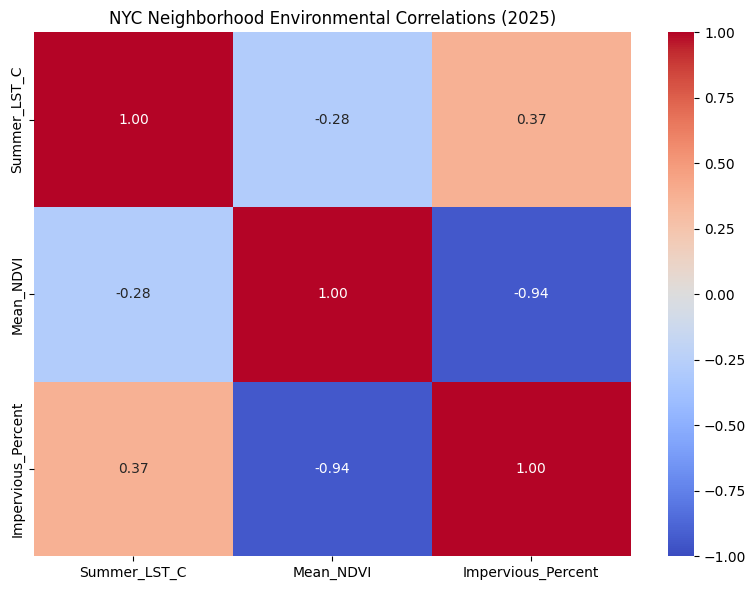

In [ ]:

import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    fmt=".2f"
)

plt.title(
    "NYC Neighborhood Environmental Correlations (2025)"
)

plt.tight_layout()
plt.show()


In [ ]:

# Filter to standard neighborhoods in 2025
infra_2025 = infrastructure_df[
    (infrastructure_df["Year"] == 2025) &
    (infrastructure_df["ntatype"].astype(str) == "0")
].copy()

variables = [
    "Summer_LST_C",
    "Mean_NDVI",
    "Impervious_Percent"
]

# Calculate correlations
correlation_matrix = infra_2025[variables].corr()

print(correlation_matrix.round(3))


                    Summer_LST_C  Mean_NDVI  Impervious_Percent
Summer_LST_C               1.000     -0.282               0.372
Mean_NDVI                 -0.282      1.000              -0.944
Impervious_Percent         0.372     -0.944               1.000


In [ ]:

# Merge infrastructure data with heat and vegetation
infrastructure_df = heat_vegetation_df.merge(
    impervious_df,
    on="nta2020",
    how="left",
    validate="many_to_one"
)

print(
    infrastructure_df[
        [
            "ntaname",
            "Year",
            "Summer_LST_C",
            "Mean_NDVI",
            "Impervious_Percent"
        ]
    ].head(10).round(2)
)

print(
    "\nMissing impervious values:",
    infrastructure_df["Impervious_Percent"].isna().sum()
)


                               ntaname  Year  Summer_LST_C  Mean_NDVI  \
0                           Greenpoint  2022         40.42       0.15   
1                         Williamsburg  2022         40.13       0.20   
2                   South Williamsburg  2022         41.49       0.21   
3                    East Williamsburg  2022         42.14       0.16   
4                     Brooklyn Heights  2022         37.36       0.28   
5  Downtown Brooklyn-DUMBO-Boerum Hill  2022         39.34       0.23   
6                          Fort Greene  2022         39.25       0.31   
7                         Clinton Hill  2022         38.78       0.30   
8                   Brooklyn Navy Yard  2022         41.85       0.14   
9            Bedford-Stuyvesant (West)  2022         38.70       0.26   

   Impervious_Percent  
0               93.68  
1               91.44  
2               89.83  
3               91.95  
4               86.63  
5               85.51  
6               78.13  
7   

In [ ]:

# Calculate mean impervious surface percentage by NTA
impervious_stats = impervious_2021.reduceRegions(
    collection=nta_ee,
    reducer=ee.Reducer.mean(),
    scale=30,
    tileScale=4
)

impervious_df = geemap.ee_to_df(impervious_stats)

impervious_df = impervious_df[
    ["nta2020", "mean"]
].rename(
    columns={
        "mean": "Impervious_Percent"
    }
)

print(impervious_df.head(10).round(2))

print(
    "\nImpervious surface summary:"
)

print(
    impervious_df["Impervious_Percent"]
    .describe()
    .round(2)
)


  nta2020  Impervious_Percent
0  BK0101               93.68
1  BK0102               91.44
2  BK0103               89.83
3  BK0104               91.95
4  BK0201               86.63
5  BK0202               85.51
6  BK0203               78.13
7  BK0204               83.05
8  BK0261               84.85
9  BK0301               84.06

Impervious surface summary:
count    262.00
mean      67.65
std       24.82
min        0.00
25%       57.42
50%       77.56
75%       85.77
max       94.73
Name: Impervious_Percent, dtype: float64


In [ ]:

# Load the 2021 NLCD impervious surface dataset
nlcd = ee.ImageCollection(
    "USGS/NLCD_RELEASES/2021_REL/NLCD"
)

impervious_2021 = (
    nlcd
    .filter(ee.Filter.eq("system:index", "2021"))
    .first()
    .select("impervious")
)

print("Impervious surface image created successfully!")
print("Bands:", impervious_2021.bandNames().getInfo())


Impervious surface image created successfully!
Bands: ['impervious']


In [ ]:

# Measure NDVI variation within each neighborhood
ndvi_variation = (
    panel_df
    .groupby(["nta2020", "ntaname", "boroname"])
    .agg(
        Mean_NDVI=("Mean_NDVI", "mean"),
        NDVI_Std=("Mean_NDVI", "std"),
        NDVI_Min=("Mean_NDVI", "min"),
        NDVI_Max=("Mean_NDVI", "max")
    )
    .reset_index()
)

ndvi_variation["NDVI_Range"] = (
    ndvi_variation["NDVI_Max"]
    - ndvi_variation["NDVI_Min"]
)

print("Within-neighborhood NDVI variation:")
print(
    ndvi_variation[
        ["NDVI_Std", "NDVI_Range"]
    ].describe().round(4)
)


Within-neighborhood NDVI variation:
       NDVI_Std  NDVI_Range
count  197.0000    197.0000
mean     0.0079      0.0180
std      0.0034      0.0078
min      0.0015      0.0036
25%      0.0053      0.0120
50%      0.0075      0.0166
75%      0.0099      0.0230
max      0.0182      0.0435


In [ ]:

models = [
    ("2025 Simple OLS", model),
    ("Borough + Year FE", model_adjusted),
    ("Neighborhood + Year FE", model_nta_fe)
]

comparison = []

for name, fitted_model in models:
    comparison.append({
        "Model": name,
        "NDVI_Coefficient": fitted_model.params["Mean_NDVI"],
        "Effect_per_0.1_NDVI_C": (
            fitted_model.params["Mean_NDVI"] * 0.1
        ),
        "P_Value": fitted_model.pvalues["Mean_NDVI"],
        "R_Squared": fitted_model.rsquared
    })

comparison_df = pd.DataFrame(comparison)

print(comparison_df.round(4))


                    Model  NDVI_Coefficient  Effect_per_0.1_NDVI_C  P_Value  \
0         2025 Simple OLS           -4.1979                -0.4198   0.0001   
1       Borough + Year FE           -7.6108                -0.7611   0.0000   
2  Neighborhood + Year FE           -6.5682                -0.6568   0.2916   

   R_Squared  
0     0.0797  
1     0.5167  
2     0.8926  


In [ ]:

import statsmodels.formula.api as smf

# Neighborhood and year fixed-effects regression
model_nta_fe = smf.ols(
    formula=(
        "Summer_LST_C ~ Mean_NDVI "
        "+ C(nta2020) + C(Year)"
    ),
    data=panel_df
).fit(
    cov_type="cluster",
    cov_kwds={
        "groups": panel_df["nta2020"]
    }
)

print(
    "NDVI coefficient:",
    round(model_nta_fe.params["Mean_NDVI"], 4)
)

print(
    "Standard error:",
    round(model_nta_fe.bse["Mean_NDVI"], 4)
)

print(
    "P-value:",
    model_nta_fe.pvalues["Mean_NDVI"]
)

print(
    "95% confidence interval:",
    model_nta_fe.conf_int().loc["Mean_NDVI"].round(4).tolist()
)

print(
    "Effect per +0.1 NDVI:",
    round(model_nta_fe.params["Mean_NDVI"] * 0.1, 3),
    "°C"
)

print(
    "R-squared:",
    round(model_nta_fe.rsquared, 4)
)


NDVI coefficient: -6.5682
Standard error: 6.2281
P-value: 0.2916056520707211
95% confidence interval: [-18.775, 5.6386]
Effect per +0.1 NDVI: -0.657 °C
R-squared: 0.8926


In [ ]:

model_comparison = pd.DataFrame({
    "Model": [
        "2025 Simple OLS",
        "2022–2025 Adjusted OLS"
    ],
    "NDVI_Coefficient": [
        model.params["Mean_NDVI"],
        model_adjusted.params["Mean_NDVI"]
    ],
    "Effect_per_0.1_NDVI_C": [
        model.params["Mean_NDVI"] * 0.1,
        model_adjusted.params["Mean_NDVI"] * 0.1
    ],
    "R_Squared": [
        model.rsquared,
        model_adjusted.rsquared
    ],
    "P_Value": [
        model.pvalues["Mean_NDVI"],
        model_adjusted.pvalues["Mean_NDVI"]
    ]
})

print(model_comparison.round(4))


                    Model  NDVI_Coefficient  Effect_per_0.1_NDVI_C  R_Squared  \
0         2025 Simple OLS           -4.1979                -0.4198     0.0797   
1  2022–2025 Adjusted OLS           -7.6108                -0.7611     0.5167   

   P_Value  
0   0.0001  
1   0.0000  


In [ ]:

import statsmodels.formula.api as smf

# Use all four years of standard NTA observations
panel_df = analysis_df.copy()

# Fit regression with borough and year fixed effects
model_adjusted = smf.ols(
    formula=(
        "Summer_LST_C ~ Mean_NDVI "
        "+ C(boroname) + C(Year)"
    ),
    data=panel_df
).fit(
    cov_type="cluster",
    cov_kwds={
        "groups": panel_df["nta2020"]
    }
)

print(model_adjusted.summary())

print(
    "\nEstimated LST difference per +0.1 NDVI:",
    round(
        model_adjusted.params["Mean_NDVI"] * 0.1,
        3
    ),
    "°C"
)


                            OLS Regression Results                            
Dep. Variable:           Summer_LST_C   R-squared:                       0.517
Model:                            OLS   Adj. R-squared:                  0.512
Method:                 Least Squares   F-statistic:                     229.1
Date:                Thu, 15 Oct 2026   Prob (F-statistic):           4.23e-95
Time:                        17:38:22   Log-Likelihood:                -1191.6
No. Observations:                 788   AIC:                             2401.
Df Residuals:                     779   BIC:                             2443.
Df Model:                           8                                         
Covariance Type:              cluster                                         
                                   coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------------
Intercept       

In [ ]:

import statsmodels.api as sm

X = sm.add_constant(data_2025["Mean_NDVI"])
y = data_2025["Summer_LST_C"]

model = sm.OLS(y, X).fit()

print(model.summary())

# Express the coefficient per 0.1 NDVI increase
effect_per_01 = model.params["Mean_NDVI"] * 0.1

print(
    "\nEstimated LST difference per +0.1 NDVI:",
    round(effect_per_01, 2),
    "°C"
)


                            OLS Regression Results                            
Dep. Variable:           Summer_LST_C   R-squared:                       0.080
Model:                            OLS   Adj. R-squared:                  0.075
Method:                 Least Squares   F-statistic:                     16.90
Date:                Thu, 15 Oct 2026   Prob (F-statistic):           5.81e-05
Time:                        17:36:08   Log-Likelihood:                -347.82
No. Observations:                 197   AIC:                             699.6
Df Residuals:                     195   BIC:                             706.2
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         39.8844      0.313    127.315      0.0

In [ ]:

# Keep standard NTAs with valid values
analysis_df = heat_vegetation_df[
    heat_vegetation_df["ntatype"].astype(str) == "0"
].dropna(
    subset=["Summer_LST_C", "Mean_NDVI"]
).copy()

correlation_results = []

for year in study_years:

    subset = analysis_df[
        analysis_df["Year"] == year
    ]

    correlation = subset[
        "Mean_NDVI"
    ].corr(
        subset["Summer_LST_C"]
    )

    correlation_results.append({
        "Year": year,
        "Neighborhoods": len(subset),
        "NDVI_LST_Correlation": correlation
    })

correlation_df = pd.DataFrame(correlation_results)

print(correlation_df.round(3))


   Year  Neighborhoods  NDVI_LST_Correlation
0  2022            197                -0.426
1  2023            197                -0.244
2  2024            197                -0.371
3  2025            197                -0.282


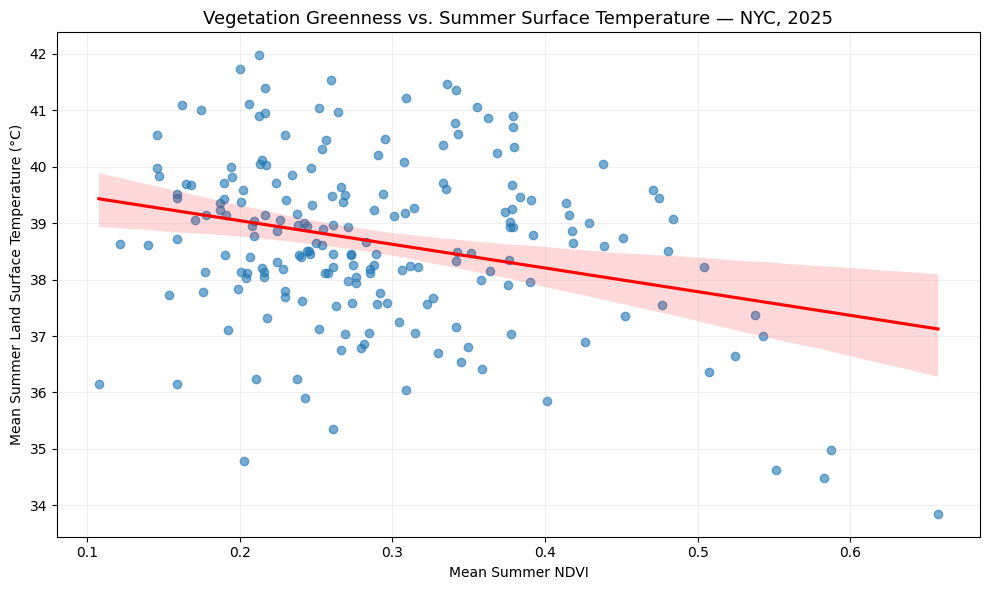

In [ ]:

import seaborn as sns
import matplotlib.pyplot as plt

data_2025 = heat_vegetation_df[
    (heat_vegetation_df["Year"] == 2025)
    & (heat_vegetation_df["ntatype"].astype(str) == "0")
].dropna(
    subset=["Summer_LST_C", "Mean_NDVI"]
)

plt.figure(figsize=(10, 6))

sns.regplot(
    data=data_2025,
    x="Mean_NDVI",
    y="Summer_LST_C",
    scatter_kws={"alpha": 0.6},
    line_kws={"color": "red"}
)

plt.title(
    "Vegetation Greenness vs. Summer Surface Temperature — NYC, 2025",
    fontsize=13
)

plt.xlabel("Mean Summer NDVI")
plt.ylabel("Mean Summer Land Surface Temperature (°C)")

plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


In [ ]:

# Merge NDVI with neighborhood temperatures
heat_vegetation_df = neighborhood_final.merge(
    ndvi_df,
    on=["nta2020", "Year"],
    how="left",
    validate="one_to_one"
)

# Check for missing values
print(
    heat_vegetation_df[
        ["Summer_LST_C", "Mean_NDVI"]
    ].isna().sum()
)

print(
    heat_vegetation_df[
        [
            "ntaname",
            "boroname",
            "Year",
            "Summer_LST_C",
            "Mean_NDVI"
        ]
    ].head(10).round(3)
)


Summer_LST_C    0
Mean_NDVI       0
dtype: int64
                               ntaname  boroname  Year  Summer_LST_C  \
0                           Greenpoint  Brooklyn  2022        40.420   
1                         Williamsburg  Brooklyn  2022        40.126   
2                   South Williamsburg  Brooklyn  2022        41.486   
3                    East Williamsburg  Brooklyn  2022        42.137   
4                     Brooklyn Heights  Brooklyn  2022        37.359   
5  Downtown Brooklyn-DUMBO-Boerum Hill  Brooklyn  2022        39.342   
6                          Fort Greene  Brooklyn  2022        39.251   
7                         Clinton Hill  Brooklyn  2022        38.781   
8                   Brooklyn Navy Yard  Brooklyn  2022        41.848   
9            Bedford-Stuyvesant (West)  Brooklyn  2022        38.700   

   Mean_NDVI  
0      0.152  
1      0.204  
2      0.213  
3      0.162  
4      0.279  
5      0.232  
6      0.309  
7      0.304  
8      0.144  
9      0

In [ ]:

ndvi_results = []

for year in study_years:

    stats = ndvi_images[year].reduceRegions(
        collection=nta_ee,
        reducer=ee.Reducer.mean(),
        scale=30,
        tileScale=4
    )

    year_df = geemap.ee_to_df(stats)
    year_df["Year"] = year

    ndvi_results.append(year_df)

ndvi_df = pd.concat(
    ndvi_results,
    ignore_index=True
)

ndvi_df = ndvi_df[
    ["nta2020", "Year", "mean"]
].rename(
    columns={"mean": "Mean_NDVI"}
)

print(ndvi_df.head(10).round(3))


  nta2020  Year  Mean_NDVI
0  BK0101  2022      0.152
1  BK0102  2022      0.204
2  BK0103  2022      0.213
3  BK0104  2022      0.162
4  BK0201  2022      0.279
5  BK0202  2022      0.232
6  BK0203  2022      0.309
7  BK0204  2022      0.304
8  BK0261  2022      0.144
9  BK0301  2022      0.262


In [ ]:

def get_summer_ndvi(year):

    start = f"{year}-06-01"
    end = f"{year}-09-01"

    l8 = (
        ee.ImageCollection("LANDSAT/LC08/C02/T1_L2")
        .filterBounds(nyc)
        .filterDate(start, end)
    )

    l9 = (
        ee.ImageCollection("LANDSAT/LC09/C02/T1_L2")
        .filterBounds(nyc)
        .filterDate(start, end)
    )

    images = l8.merge(l9).map(process_ndvi)

    monthly_means = []

    for month in [6, 7, 8]:

        monthly = images.filterDate(
            ee.Date.fromYMD(year, month, 1),
            ee.Date.fromYMD(year, month, 1)
              .advance(1, "month")
        )

        monthly_means.append(
            monthly.mean().select("NDVI")
        )

    return (
        ee.ImageCollection.fromImages(monthly_means)
        .mean()
        .updateMask(land_mask)
        .rename("NDVI")
    )


ndvi_images = {
    year: get_summer_ndvi(year)
    for year in study_years
}

print("Summer NDVI images created!")


Summer NDVI images created!


In [ ]:

def process_ndvi(image):

    qa = image.select("QA_PIXEL")

    cloud_mask = qa.bitwiseAnd(
        int("11111", 2)
    ).eq(0)

    saturation_mask = (
        image.select("QA_RADSAT").eq(0)
    )

    # Apply Landsat Collection 2 reflectance scaling
    red = (
        image.select("SR_B4")
        .multiply(0.0000275)
        .add(-0.2)
    )

    nir = (
        image.select("SR_B5")
        .multiply(0.0000275)
        .add(-0.2)
    )

    # Calculate NDVI using scaled reflectance
    ndvi = (
        nir.subtract(red)
        .divide(nir.add(red))
        .rename("NDVI")
    )

    return (
        ndvi
        .updateMask(cloud_mask)
        .updateMask(saturation_mask)
        .copyProperties(image, ["system:time_start"])
    )

print("NDVI processing function created!")


NDVI processing function created!


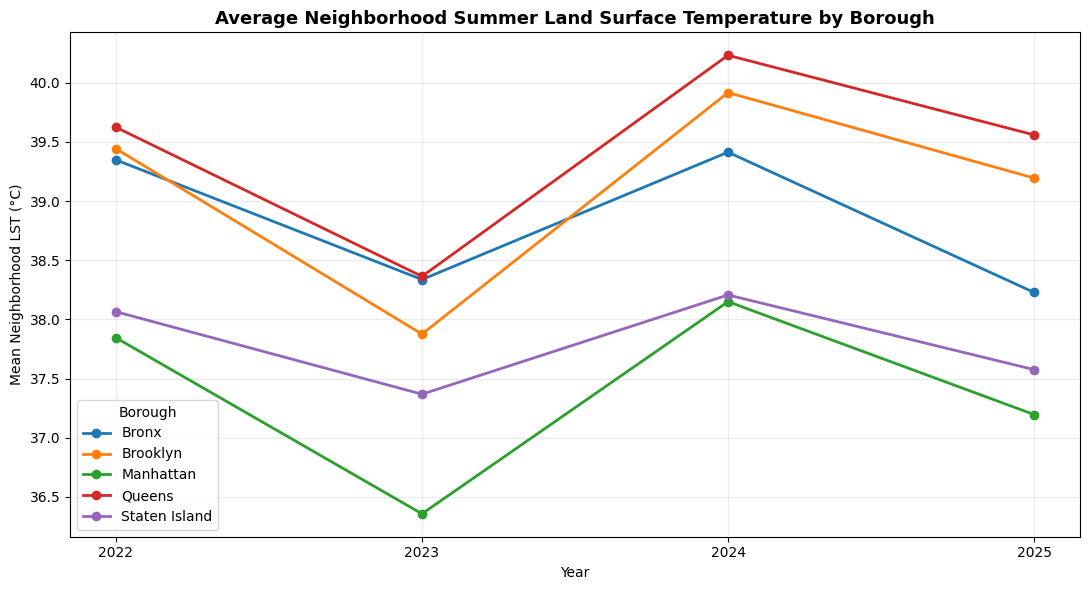

In [ ]:

fig, ax = plt.subplots(figsize=(11, 6))

for borough, group in borough_summary.groupby("boroname"):

    ax.plot(
        group["Year"],
        group["Mean_Neighborhood_LST"],
        marker="o",
        linewidth=2,
        label=borough
    )

ax.set_title(
    "Average Neighborhood Summer Land Surface Temperature by Borough",
    fontsize=13,
    fontweight="bold"
)

ax.set_xlabel("Year")
ax.set_ylabel("Mean Neighborhood LST (°C)")
ax.set_xticks(study_years)
ax.grid(alpha=0.25)
ax.legend(title="Borough")

plt.tight_layout()
plt.show()


In [ ]:

borough_summary = (
    residential_df
    .groupby(["boroname", "Year"], as_index=False)
    .agg(
        Mean_Neighborhood_LST=("Summer_LST_C", "mean"),
        Median_Neighborhood_LST=("Summer_LST_C", "median"),
        Neighborhoods=("nta2020", "nunique")
    )
)

borough_pivot = borough_summary.pivot(
    index="boroname",
    columns="Year",
    values="Mean_Neighborhood_LST"
)

print(borough_pivot.round(2))


Year            2022   2023   2024   2025
boroname                                 
Bronx          39.35  38.34  39.41  38.23
Brooklyn       39.44  37.88  39.92  39.19
Manhattan      37.84  36.36  38.15  37.20
Queens         39.62  38.36  40.23  39.56
Staten Island  38.06  37.37  38.21  37.58


In [ ]:

# Focus on standard residential-type NTAs
residential_df = neighborhood_final[
    neighborhood_final["ntatype"].astype(str) == "0"
].copy()

# Calculate four-year temperature averages
neighborhood_4yr = (
    residential_df
    .groupby(
        ["nta2020", "ntaname", "boroname"],
        as_index=False
    )
    .agg(
        Avg_LST_2022_2025=("Summer_LST_C", "mean"),
        Min_LST=("Summer_LST_C", "min"),
        Max_LST=("Summer_LST_C", "max"),
        Avg_Completeness=("Complete_Month_Percent", "mean"),
        Years_Observed=("Summer_LST_C", "count")
    )
)

# Rank neighborhoods by four-year average temperature
hottest_4yr = (
    neighborhood_4yr
    .sort_values(
        "Avg_LST_2022_2025",
        ascending=False
    )
    .head(15)
)

print(hottest_4yr.round(2))


    nta2020                 ntaname       boroname  Avg_LST_2022_2025  \
165  QN1201                 Jamaica         Queens              41.52   
155  QN0903     South Richmond Hill         Queens              41.42   
158  QN1001        South Ozone Park         Queens              41.23   
173  QN1303          Queens Village         Queens              41.11   
166  QN1202           South Jamaica         Queens              41.06   
47   BK1702  East Flatbush-Farragut       Brooklyn              41.05   
3    BK0104       East Williamsburg       Brooklyn              41.03   
186  SI0106           Port Richmond  Staten Island              41.01   
32   BK1202            Borough Park       Brooklyn              41.00   
170  QN1206                  Hollis         Queens              40.91   
135  QN0501                 Maspeth         Queens              40.83   
175  QN1305               Laurelton         Queens              40.73   
156  QN0904      Ozone Park (North)         Queens 

In [ ]:

top_hot_quality = (
    neighborhood_final[
        (neighborhood_final["Year"] == 2025)
        & (neighborhood_final["ntatype"].astype(str) == "0")
    ]
    .sort_values(
        "Summer_LST_C",
        ascending=False
    )
    [
        [
            "ntaname",
            "boroname",
            "Summer_LST_C",
            "Complete_Month_Percent"
        ]
    ]
    .head(10)
)

print(top_hot_quality.round(2))


                  ntaname  boroname  Summer_LST_C  Complete_Month_Percent
989   South Richmond Hill    Queens         41.98                   100.0
1001              Jamaica    Queens         41.73                   100.0
992      South Ozone Park    Queens         41.54                   100.0
1006               Hollis    Queens         41.46                   100.0
825          Borough Park  Brooklyn         41.40                   100.0
1009       Queens Village    Queens         41.36                   100.0
1002        South Jamaica    Queens         41.22                   100.0
990    Ozone Park (North)    Queens         41.11                   100.0
789     East Williamsburg  Brooklyn         41.09                   100.0
1011            Laurelton    Queens         41.07                   100.0


In [ ]:

neighborhood_final = neighborhood_df_fixed.merge(
    quality_df[
        ["nta2020", "Year", "Complete_Month_Percent"]
    ],
    on=["nta2020", "Year"],
    how="left",
    validate="one_to_one"
)

print(
    neighborhood_final[
        [
            "ntaname",
            "Year",
            "Summer_LST_C",
            "Complete_Month_Percent"
        ]
    ].head(10).round(2)
)


                               ntaname  Year  Summer_LST_C  \
0                           Greenpoint  2022         40.42   
1                         Williamsburg  2022         40.13   
2                   South Williamsburg  2022         41.49   
3                    East Williamsburg  2022         42.14   
4                     Brooklyn Heights  2022         37.36   
5  Downtown Brooklyn-DUMBO-Boerum Hill  2022         39.34   
6                          Fort Greene  2022         39.25   
7                         Clinton Hill  2022         38.78   
8                   Brooklyn Navy Yard  2022         41.85   
9            Bedford-Stuyvesant (West)  2022         38.70   

   Complete_Month_Percent  
0                   93.46  
1                   99.50  
2                  100.00  
3                  100.00  
4                  100.00  
5                  100.00  
6                  100.00  
7                  100.00  
8                   98.24  
9                  100.00  


In [ ]:

# Calculate neighborhood-level three-month completeness
quality_results = []

for year in study_years:

    months = study_images[year].select("Months_Observed")

    # 1 where all three months were observed; 0 otherwise
    complete_pixels = (
        months.eq(3)
        .unmask(0)
        .updateMask(land_mask)
        .rename("Complete")
    )

    stats = complete_pixels.reduceRegions(
        collection=nta_ee,
        reducer=ee.Reducer.mean(),
        scale=30,
        tileScale=4
    )

    year_df = geemap.ee_to_df(stats)
    year_df["Year"] = year

    quality_results.append(year_df)

quality_df = pd.concat(
    quality_results,
    ignore_index=True
)

quality_df = quality_df[
    ["nta2020", "Year", "mean"]
].rename(
    columns={"mean": "Complete_Month_Fraction"}
)

quality_df["Complete_Month_Percent"] = (
    quality_df["Complete_Month_Fraction"] * 100
)

print(quality_df.head())


  nta2020  Year  Complete_Month_Fraction  Complete_Month_Percent
0  BK0101  2022                 0.934555               93.455491
1  BK0102  2022                 0.994960               99.496025
2  BK0103  2022                 1.000000              100.000000
3  BK0104  2022                 1.000000              100.000000
4  BK0201  2022                 1.000000              100.000000


In [ ]:

# Identify the 10 hottest geographic areas in 2025
hottest_2025 = (
    neighborhood_df_fixed[
        neighborhood_df_fixed["Year"] == 2025
    ]
    .sort_values(
        "Summer_LST_C",
        ascending=False
    )
    [
        [
            "ntaname",
            "boroname",
            "ntatype",
            "Summer_LST_C"
        ]
    ]
    .head(10)
)

print(hottest_2025.round(2))


                                    ntaname  boroname ntatype  Summer_LST_C
989                     South Richmond Hill    Queens       0         41.98
948                 Sunnyside Yards (North)    Queens       6         41.77
1001                                Jamaica    Queens       0         41.73
992                        South Ozone Park    Queens       0         41.54
1006                                 Hollis    Queens       0         41.46
825                            Borough Park  Brooklyn       0         41.40
1022  John F. Kennedy International Airport    Queens       8         41.38
1009                         Queens Village    Queens       0         41.36
1019                      LaGuardia Airport    Queens       8         41.31
1002                          South Jamaica    Queens       0         41.22


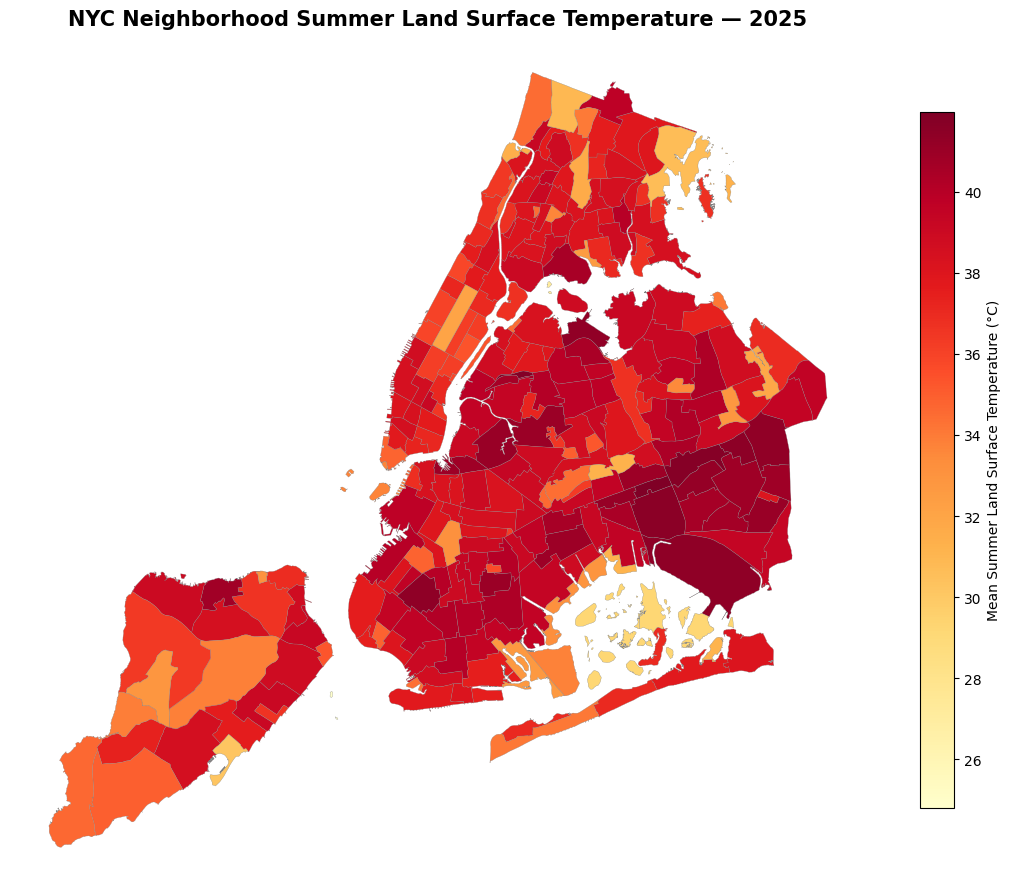

In [ ]:

fig, ax = plt.subplots(figsize=(11, 11))

heat_map_2025.plot(
    column="Summer_LST_C",
    cmap="YlOrRd",
    legend=True,
    edgecolor="gray",
    linewidth=0.2,
    ax=ax,
    legend_kwds={
        "label": "Mean Summer Land Surface Temperature (°C)",
        "shrink": 0.65
    }
)

ax.set_title(
    "NYC Neighborhood Summer Land Surface Temperature — 2025",
    fontsize=15,
    fontweight="bold"
)

ax.set_axis_off()

plt.tight_layout()
plt.show()


In [ ]:

# Select 2025 neighborhood temperatures
temp_2025 = neighborhood_df_fixed[
    neighborhood_df_fixed["Year"] == 2025
][["nta2020", "Summer_LST_C"]]

# Merge temperature data with geographic boundaries
heat_map_2025 = nta_gdf.merge(
    temp_2025,
    on="nta2020",
    how="left",
    validate="one_to_one"
)

print("Neighborhoods mapped:", len(heat_map_2025))
print(
    "Missing temperatures:",
    heat_map_2025["Summer_LST_C"].isna().sum()
)


Neighborhoods mapped: 262
Missing temperatures: 0


In [ ]:

neighborhood_results_fixed = []

for year in study_years:

    temperature = study_images[year].select("LST_C")

    stats = temperature.reduceRegions(
        collection=nta_ee,
        reducer=ee.Reducer.mean(),
        scale=30,
        tileScale=4
    )

    year_df = geemap.ee_to_df(stats)
    year_df["Year"] = year

    neighborhood_results_fixed.append(year_df)

neighborhood_df_fixed = pd.concat(
    neighborhood_results_fixed,
    ignore_index=True
)

neighborhood_df_fixed = (
    neighborhood_df_fixed[
        [
            "nta2020",
            "ntaname",
            "boroname",
            "ntatype",
            "Year",
            "mean"
        ]
    ]
    .rename(columns={"mean": "Summer_LST_C"})
)

# Check missing values
missing_fixed = (
    neighborhood_df_fixed
    .groupby("Year")["Summer_LST_C"]
    .agg(
        Total="size",
        Missing=lambda x: x.isna().sum(),
        Valid="count"
    )
)

missing_fixed["Missing_Percent"] = (
    missing_fixed["Missing"]
    / missing_fixed["Total"] * 100
)

print(missing_fixed.round(2))


      Total  Missing  Valid  Missing_Percent
Year                                        
2022    262        0    262              0.0
2023    262        0    262              0.0
2024    262        0    262              0.0
2025    262        0    262              0.0


In [ ]:

# Replace the problematic land mask
land_mask = land_mask_fixed

# Rebuild temperature and completeness layers
summer_layers = {
    year: create_summer_layers(year)
    for year in range(2021, 2026)
}

study_images = {
    year: summer_layers[year]
    for year in [2022, 2023, 2024, 2025]
}

print("Summer layers rebuilt with corrected land mask!")


Summer layers rebuilt with corrected land mask!


In [ ]:

land_test = (
    land_mask_fixed
    .rename("land")
    .reduceRegion(
        reducer=ee.Reducer.mean(),
        geometry=test_nta.geometry(),
        scale=30,
        maxPixels=1e10,
        tileScale=4
    )
)

print("Corrected land fraction:")
print(land_test.getInfo())


Corrected land fraction:


{'land': 1}


In [ ]:

# Load historical surface-water occurrence
water_occurrence = (
    ee.Image("JRC/GSW1_4/GlobalSurfaceWater")
    .select("occurrence")
)

# Treat missing occurrence data as zero occurrence
land_mask_fixed = (
    water_occurrence
    .unmask(0)
    .lt(50)
)

print("Corrected land mask created!")


Corrected land mask created!


In [ ]:

# Select the 2022 summer temperature image
temperature = study_images[2022].select("LST_C")

# Count valid temperature pixels inside South Williamsburg
valid_temperature = (
    temperature.mask()
    .unmask(0)
    .rename("valid")
)

temperature_stats = valid_temperature.reduceRegion(
    reducer=ee.Reducer.mean(),
    geometry=test_nta.geometry(),
    scale=30,
    maxPixels=1e10,
    tileScale=4
)

# Check land-mask coverage
land_stats = (
    land_mask.unmask(0).rename("land")
    .reduceRegion(
        reducer=ee.Reducer.mean(),
        geometry=test_nta.geometry(),
        scale=30,
        maxPixels=1e10,
        tileScale=4
    )
)

print("Valid temperature fraction:", temperature_stats.getInfo())
print("Land-mask fraction:", land_stats.getInfo())


Valid temperature fraction: {'valid': 0}
Land-mask fraction: {'land': 0}


In [ ]:

# South Williamsburg boundary
test_nta = nta_ee.filter(
    ee.Filter.eq("nta2020", "BK0103")
)

# Check neighborhood geometry
print("NTA feature count:", test_nta.size().getInfo())

print(
    "NTA area (km²):",
    test_nta.geometry().area().divide(1e6).getInfo()
)

# Check Landsat imagery intersecting the neighborhood
test_images = (
    get_all_summer_images(2022)
    .filterBounds(test_nta.geometry())
)

print(
    "Landsat scenes intersecting neighborhood:",
    test_images.size().getInfo()
)


NTA feature count: 1
NTA area (km²): 1.4112435235017344
Landsat scenes intersecting neighborhood: 22


In [ ]:

missing_by_nta = neighborhood_df.pivot(
    index=["nta2020", "ntaname", "boroname"],
    columns="Year",
    values="Summer_LST_C"
)

always_missing = missing_by_nta[
    missing_by_nta.isna().all(axis=1)
]

print("Neighborhoods missing in all years:", len(always_missing))
print(always_missing.head(15))


Neighborhoods missing in all years: 106
Year                                                             2022  2023  \
nta2020 ntaname                                        boroname               
BK0103  South Williamsburg                             Brooklyn   NaN   NaN   
BK0203  Fort Greene                                    Brooklyn   NaN   NaN   
BK0204  Clinton Hill                                   Brooklyn   NaN   NaN   
BK0301  Bedford-Stuyvesant (West)                      Brooklyn   NaN   NaN   
BK0302  Bedford-Stuyvesant (East)                      Brooklyn   NaN   NaN   
BK0401  Bushwick (West)                                Brooklyn   NaN   NaN   
BK0402  Bushwick (East)                                Brooklyn   NaN   NaN   
BK0471  The Evergreens Cemetery                        Brooklyn   NaN   NaN   
BK0501  Cypress Hills                                  Brooklyn   NaN   NaN   
BK0502  East New York (North)                          Brooklyn   NaN   NaN   
BK0503  East

In [ ]:

# Select South Williamsburg
test_nta = nta_ee.filter(
    ee.Filter.eq("nta2020", "BK0103")
)

# Calculate its 2022 temperature directly
test_result = (
    study_images[2022]
    .select("LST_C")
    .reduceRegion(
        reducer=ee.Reducer.mean(),
        geometry=test_nta.geometry(),
        scale=30,
        maxPixels=1e10,
        tileScale=4
    )
)

print("South Williamsburg 2022:")
print(test_result.getInfo())


South Williamsburg 2022:
{'LST_C': None}


In [ ]:

# Check the range of neighborhood temperatures
print(
    neighborhood_df
    .groupby("Year")["Summer_LST_C"]
    .agg(["count", "min", "median", "mean", "max"])
    .round(2)
)


      count    min  median   mean    max
Year                                    
2022    156  26.13   33.80  34.15  45.66
2023    156  25.72   32.42  32.84  44.72
2024    156  24.75   33.60  33.90  45.37
2025    156  25.35   33.13  33.32  44.15


In [ ]:

# Count missing temperature values by year
missing_summary = (
    neighborhood_df
    .groupby("Year")["Summer_LST_C"]
    .agg(
        Total="size",
        Missing=lambda x: x.isna().sum(),
        Valid="count"
    )
)

missing_summary["Missing_Percent"] = (
    missing_summary["Missing"]
    / missing_summary["Total"]
    * 100
)

print(missing_summary.round(2))


      Total  Missing  Valid  Missing_Percent
Year                                        
2022    262      106    156            40.46
2023    262      106    156            40.46
2024    262      106    156            40.46
2025    262      106    156            40.46


In [ ]:

# Calculate mean temperature for each NTA and year
neighborhood_results = []

for year in study_years:

    temperature = study_images[year].select("LST_C")

    neighborhood_stats = temperature.reduceRegions(
        collection=nta_ee,
        reducer=ee.Reducer.mean(),
        scale=30,
        tileScale=4
    )

    # Transfer results to a Pandas DataFrame
    year_df = geemap.ee_to_df(neighborhood_stats)

    year_df["Year"] = year

    neighborhood_results.append(year_df)

# Combine all years
neighborhood_df = pd.concat(
    neighborhood_results,
    ignore_index=True
)

# Keep relevant columns
neighborhood_df = neighborhood_df[
    [
        "nta2020",
        "ntaname",
        "boroname",
        "ntatype",
        "Year",
        "mean"
    ]
].rename(
    columns={"mean": "Summer_LST_C"}
)

print("Total neighborhood-year observations:", len(neighborhood_df))

print(neighborhood_df.head(10))


Total neighborhood-year observations: 1048
  nta2020                              ntaname  boroname ntatype  Year  \
0  BK0101                           Greenpoint  Brooklyn       0  2022   
1  BK0102                         Williamsburg  Brooklyn       0  2022   
2  BK0103                   South Williamsburg  Brooklyn       0  2022   
3  BK0104                    East Williamsburg  Brooklyn       0  2022   
4  BK0201                     Brooklyn Heights  Brooklyn       0  2022   
5  BK0202  Downtown Brooklyn-DUMBO-Boerum Hill  Brooklyn       0  2022   
6  BK0203                          Fort Greene  Brooklyn       0  2022   
7  BK0204                         Clinton Hill  Brooklyn       0  2022   
8  BK0261                   Brooklyn Navy Yard  Brooklyn       6  2022   
9  BK0301            Bedford-Stuyvesant (West)  Brooklyn       0  2022   

   Summer_LST_C  
0     41.638537  
1     35.659854  
2           NaN  
3     39.842713  
4     34.807948  
5     37.942747  
6           NaN 

In [ ]:

print(
    nta_clean.groupby("ntatype")
    .size()
)

print(
    nta_clean[
        ["nta2020", "ntaname", "ntatype"]
    ].head(15)
)


ntatype
0    197
5      1
6      8
7     14
8      2
9     40
dtype: int64
   nta2020                              ntaname ntatype
0   BK0101                           Greenpoint       0
1   BK0102                         Williamsburg       0
2   BK0103                   South Williamsburg       0
3   BK0104                    East Williamsburg       0
4   BK0201                     Brooklyn Heights       0
5   BK0202  Downtown Brooklyn-DUMBO-Boerum Hill       0
6   BK0203                          Fort Greene       0
7   BK0204                         Clinton Hill       0
8   BK0261                   Brooklyn Navy Yard       6
9   BK0301            Bedford-Stuyvesant (West)       0
10  BK0302            Bedford-Stuyvesant (East)       0
11  BK0401                      Bushwick (West)       0
12  BK0402                      Bushwick (East)       0
13  BK0471              The Evergreens Cemetery       7
14  BK0501                        Cypress Hills       0


In [ ]:

import geemap

# Keep the columns needed for our analysis
nta_clean = nta_gdf[
    [
        "nta2020",
        "ntaname",
        "boroname",
        "ntatype",
        "geometry"
    ]
].copy()

# Make sure coordinates are longitude/latitude
nta_clean = nta_clean.to_crs("EPSG:4326")

# Convert GeoPandas to Earth Engine
nta_ee = geemap.geopandas_to_ee(nta_clean)

print("Neighborhood boundaries transferred!")
print("Total areas:", nta_ee.size().getInfo())


Neighborhood boundaries transferred!
Total areas: 262


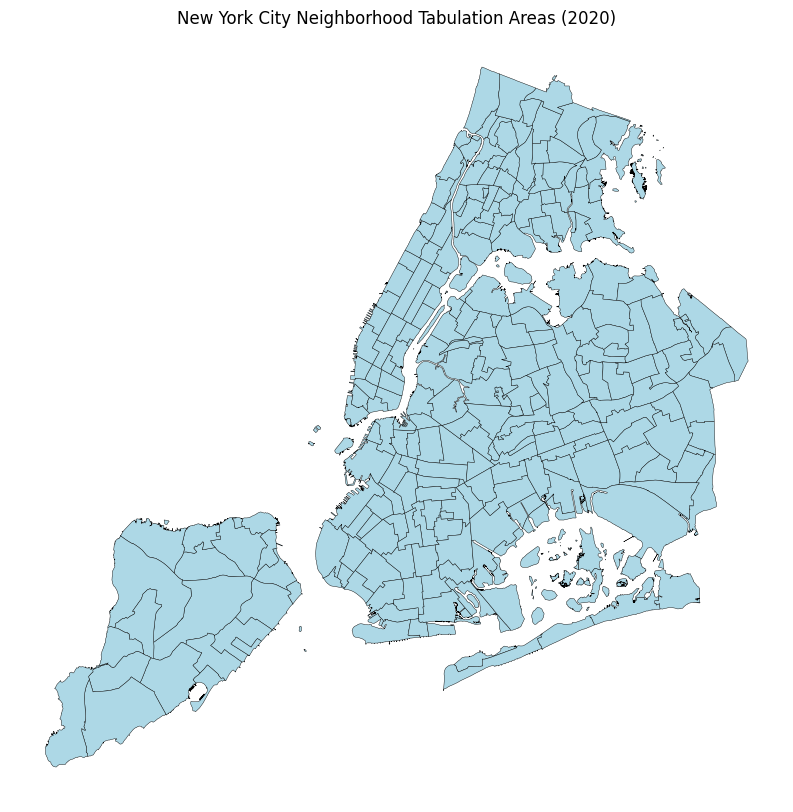

In [ ]:

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 10))

nta_gdf.plot(
    ax=ax,
    edgecolor="black",
    linewidth=0.3,
    color="lightblue"
)

ax.set_title(
    "New York City Neighborhood Tabulation Areas (2020)"
)
ax.set_axis_off()

plt.show()


In [ ]:

import geopandas as gpd
import io

filename = next(iter(uploaded))

nta_gdf = gpd.read_file(
    io.BytesIO(uploaded[filename])
)

print("Number of geographic areas:", len(nta_gdf))
print("Columns:")
print(nta_gdf.columns.tolist())

nta_gdf.head()


Number of geographic areas: 262
Columns:
[':id', ':version', ':created_at', ':updated_at', 'borocode', 'boroname', 'countyfips', 'nta2020', 'ntaname', 'ntaabbrev', 'ntatype', 'cdta2020', 'cdtaname', 'shape_leng', 'shape_area', 'geometry']


,:id,:version,:created_at,:updated_at,borocode,boroname,countyfips,nta2020,ntaname,ntaabbrev,ntatype,cdta2020,cdtaname,shape_leng,shape_area,geometry
0,row-bmvw_d9i9~nqb4,rv-i7ie.ap2h_d5bw,2026-05-28 15:11:18.238000+00:00,2026-05-28 15:11:18.238000+00:00,3,Brooklyn,047,BK0101,Greenpoint,Grnpt,0,BK01,BK01 Williamsburg-Greenpoint (CD 1 Equivalent),28919.5607283,35321808.4385,"MULTIPOLYGON (((-73.93213 40.72816, -73.93238 ..."
1,row-tzx2-czu8~tc2w,rv-gmc9_dhf8.unct,2026-05-28 15:11:18.238000+00:00,2026-05-28 15:11:18.238000+00:00,3,Brooklyn,047,BK0102,Williamsburg,Wllmsbrg,0,BK01,BK01 Williamsburg-Greenpoint (CD 1 Equivalent),28134.0830277,28852852.8918,"MULTIPOLYGON (((-73.95814 40.7244, -73.95772 4..."
2,row-5932~7ib6-cb2s,rv-agbp~rpt8_5qcr,2026-05-28 15:11:18.238000+00:00,2026-05-28 15:11:18.238000+00:00,3,Brooklyn,047,BK0103,South Williamsburg,SWllmsbrg,0,BK01,BK01 Williamsburg-Greenpoint (CD 1 Equivalent),18250.2800908,15208960.645,"MULTIPOLYGON (((-73.95024 40.70547, -73.94984 ..."
3,row-eqcc_vxra.mikr,rv-93f3-x87m-kp3a,2026-05-28 15:11:18.238000+00:00,2026-05-28 15:11:18.238000+00:00,3,Brooklyn,047,BK0104,East Williamsburg,EWllmsbrg,0,BK01,BK01 Williamsburg-Greenpoint (CD 1 Equivalent),43184.8003755,52267406.735,"MULTIPOLYGON (((-73.92406 40.71411, -73.92404 ..."
4,row-vrih~m6fc_qrz8,rv-ggtx-pe4m-iawc,2026-05-28 15:11:18.238000+00:00,2026-05-28 15:11:18.238000+00:00,3,Brooklyn,047,BK0201,Brooklyn Heights,BkHts,0,BK02,BK02 Downtown Brooklyn-Fort Greene (CD 2 Appro...,14312.1922849,9982022.78755,"MULTIPOLYGON (((-73.99236 40.68969, -73.99436 ..."


In [ ]:

from google.colab import files

uploaded = files.upload()


Saving 2020_Neighborhood_Tabulation_Areas_(NTAs)_20261015.geojson to 2020_Neighborhood_Tabulation_Areas_(NTAs)_20261015.geojson


In [ ]:

# Primary study period: 2022–2025
study_years = [2022, 2023, 2024, 2025]

# Reuse our existing temperature and completeness layers
study_images = {
    year: summer_layers[year]
    for year in study_years
}

print("Primary study period:", study_years)

for year in study_years:
    print(
        year,
        "- Bands:",
        study_images[year].bandNames().getInfo()
    )


Primary study period: [2022, 2023, 2024, 2025]
2022 - Bands: ['LST_C', 'Months_Observed']
2023 - Bands: ['LST_C', 'Months_Observed']
2024 - Bands: ['LST_C', 'Months_Observed']
2025 - Bands: ['LST_C', 'Months_Observed']


In [ ]:

completeness_results = []

for year in range(2021, 2026):

    image = summer_layers[year].select("Months_Observed")

    # Calculate frequency of 0, 1, 2, or 3 observed months
    histogram = image.reduceRegion(
        reducer=ee.Reducer.frequencyHistogram(),
        geometry=nyc.geometry(),
        scale=30,
        maxPixels=1e10,
        tileScale=4
    ).get("Months_Observed").getInfo()

    for months in range(4):

        count = histogram.get(str(months), 0)

        completeness_results.append({
            "Year": year,
            "Months_Observed": months,
            "Pixel_Count": count
        })

completeness_df = pd.DataFrame(completeness_results)

# Calculate percentage within each year
completeness_df["Percent"] = (
    completeness_df["Pixel_Count"]
    / completeness_df.groupby("Year")["Pixel_Count"].transform("sum")
    * 100
)

print(
    completeness_df.pivot(
        index="Year",
        columns="Months_Observed",
        values="Percent"
    ).round(2)
)


Months_Observed     0     1      2      3
Year                                     
2021             0.47  5.20  70.13  24.20
2022             0.51  1.37   5.04  93.09
2023             0.03  0.47   2.95  96.56
2024             0.43  1.68   4.24  93.65
2025             0.08  0.80   8.59  90.52


In [ ]:

def create_summer_layers(year):

    images = get_all_summer_images(year)

    monthly_means = []
    monthly_counts = []

    for month in [6, 7, 8]:

        start = ee.Date.fromYMD(year, month, 1)
        end = start.advance(1, "month")

        monthly = images.filterDate(start, end)

        monthly_mean = monthly.mean().select("LST_C")

        monthly_count = (
            monthly.select("LST_C")
            .count()
            .unmask(0)
            .gt(0)
            .rename("valid_month")
        )

        monthly_means.append(monthly_mean)
        monthly_counts.append(monthly_count)

    # Average monthly temperatures where available
    summer_temperature = (
        ee.ImageCollection.fromImages(monthly_means)
        .mean()
        .updateMask(land_mask)
        .rename("LST_C")
    )

    # Count number of months with observations
    completeness = (
        ee.ImageCollection.fromImages(monthly_counts)
        .sum()
        .updateMask(land_mask)
        .rename("Months_Observed")
    )

    return summer_temperature.addBands(completeness)


summer_layers = {
    year: create_summer_layers(year)
    for year in range(2021, 2026)
}

print("Temperature and completeness layers created!")


Temperature and completeness layers created!


In [ ]:

expanded_results = []

for year in range(2021, 2026):

    images = get_all_summer_images(year)

    for month in [6, 7, 8]:

        start = ee.Date.fromYMD(year, month, 1)
        end = start.advance(1, "month")

        monthly = images.filterDate(start, end)

        observed = (
            monthly.select("LST_C")
            .count()
            .unmask(0)
            .gt(0)
            .updateMask(land_mask)
            .rename("observed")
        )

        stats = observed.reduceRegion(
            reducer=ee.Reducer.mean(),
            geometry=nyc.geometry(),
            scale=30,
            maxPixels=1e10,
            tileScale=4
        )

        coverage = stats.get("observed").getInfo()

        expanded_results.append({
            "Year": year,
            "Month": month,
            "Images": monthly.size().getInfo(),
            "Coverage_Percent": (
                coverage * 100
                if coverage is not None else None
            )
        })

expanded_df = pd.DataFrame(expanded_results)

print(expanded_df.round(2))


    Year  Month  Images  Coverage_Percent
0   2021      6       5             94.78
1   2021      7       5             24.79
2   2021      8       5             98.49
3   2022      6      10             95.14
4   2022      7      12             98.77
5   2022      8      11             96.80
6   2023      6      11             99.62
7   2023      7      10             99.71
8   2023      8       7             96.71
9   2024      6       9             94.50
10  2024      7      12             97.46
11  2024      8      11             99.15
12  2025      6       8             91.01
13  2025      7      12             99.90
14  2025      8      11             98.65


In [ ]:

# New collection: no scene-level cloud threshold
def get_all_summer_images(year):

    start = f"{year}-06-01"
    end = f"{year}-09-01"

    l8 = (
        ee.ImageCollection("LANDSAT/LC08/C02/T1_L2")
        .filterBounds(nyc)
        .filterDate(start, end)
    )

    l9 = (
        ee.ImageCollection("LANDSAT/LC09/C02/T1_L2")
        .filterBounds(nyc)
        .filterDate(start, end)
    )

    return l8.merge(l9).map(process_landsat)

print("Updated Landsat collection ready!")


Updated Landsat collection ready!


In [ ]:

# Fraction of NYC land pixels retained in both years
matched_coverage_image = (
    common_mask
    .unmask(0)
    .updateMask(land_mask)
    .rename("matched")
)

coverage_stats = matched_coverage_image.reduceRegion(
    reducer=ee.Reducer.mean(),
    geometry=nyc.geometry(),
    scale=30,
    maxPixels=1e10,
    tileScale=4
)

matched_coverage = (
    coverage_stats.get("matched").getInfo() * 100
)

print(
    "Shared 2021–2025 land coverage:",
    round(matched_coverage, 2),
    "%"
)


Shared 2021–2025 land coverage: 21.44 %


In [ ]:

matched_results = []

for year, image in [
    (2021, matched_2021),
    (2025, matched_2025)
]:

    stats = image.reduceRegion(
        reducer=ee.Reducer.mean(),
        geometry=nyc.geometry(),
        scale=30,
        maxPixels=1e10,
        tileScale=4
    )

    matched_results.append({
        "Year": year,
        "Matched_LST_C": stats.get("LST_C").getInfo()
    })

matched_df = pd.DataFrame(matched_results)

print(matched_df.round(2))


   Year  Matched_LST_C
0  2021          31.03
1  2025          30.18


In [ ]:

# Get complete summer temperature images
summer_2021_complete = get_complete_summer(2021)
summer_2025_complete = get_complete_summer(2025)

# Identify pixels valid in both years
common_mask = (
    summer_2021_complete.select("LST_C").mask()
    .And(summer_2025_complete.select("LST_C").mask())
    .And(land_mask)
)

# Apply the same geographic mask to both years
matched_2021 = summer_2021_complete.updateMask(common_mask)
matched_2025 = summer_2025_complete.updateMask(common_mask)

print("Common observation mask created!")


Common observation mask created!


In [ ]:

# Measure coverage of complete three-month summer composites
complete_coverage = []

for year in range(2021, 2026):

    image = get_complete_summer(year)

    # 1 for valid summer pixels, 0 for missing pixels
    valid_pixels = (
        image.select("LST_C")
        .mask()
        .unmask(0)
        .updateMask(land_mask)
        .rename("valid")
    )

    stats = valid_pixels.reduceRegion(
        reducer=ee.Reducer.mean(),
        geometry=nyc.geometry(),
        scale=30,
        maxPixels=1e10,
        tileScale=4
    )

    coverage = stats.get("valid").getInfo()

    complete_coverage.append({
        "Year": year,
        "Complete_Summer_Coverage_Percent": (
            coverage * 100
            if coverage is not None else None
        )
    })

complete_coverage_df = pd.DataFrame(
    complete_coverage
)

print(complete_coverage_df.round(2))


   Year  Complete_Summer_Coverage_Percent
0  2021                             22.25
1  2022                             91.98
2  2023                             71.47
3  2024                             92.86
4  2025                             90.18


In [ ]:

def get_complete_summer(year):

    images = get_combined_summer(year)
    monthly_means = []
    monthly_valid = []

    for month in [6, 7, 8]:

        start = ee.Date.fromYMD(year, month, 1)
        end = start.advance(1, "month")

        month_images = images.filterDate(start, end)

        monthly_mean = month_images.mean().select("LST_C")

        # At least one valid temperature observation
        valid = (
            month_images.select("LST_C")
            .count()
            .unmask(0)
            .gt(0)
        )

        monthly_means.append(monthly_mean)
        monthly_valid.append(valid)

    # Require valid observations in all three months
    complete_mask = (
        monthly_valid[0]
        .And(monthly_valid[1])
        .And(monthly_valid[2])
        .And(land_mask)
    )

    # Equal weight for June, July, and August
    summer = (
        ee.ImageCollection.fromImages(monthly_means)
        .mean()
        .updateMask(complete_mask)
        .rename("LST_C")
    )

    return summer


# Calculate complete-month summer temperatures
complete_results = []

for year in range(2021, 2026):

    image = get_complete_summer(year)

    stats = image.reduceRegion(
        reducer=ee.Reducer.mean(),
        geometry=nyc.geometry(),
        scale=30,
        maxPixels=1e10,
        tileScale=4
    )

    complete_results.append({
        "Year": year,
        "Complete_Summer_LST_C": (
            stats.get("LST_C").getInfo()
        )
    })

complete_df = pd.DataFrame(complete_results)

print(complete_df.round(2))


   Year  Complete_Summer_LST_C
0  2021                  31.03
1  2022                  32.61
2  2023                  31.79
3  2024                  32.28
4  2025                  30.92


In [ ]:

# Calculate monthly coverage using Landsat 8 + 9
combined_monthly_results = []

for year in range(2021, 2026):

    for month in [6, 7, 8]:

        start = ee.Date.fromYMD(year, month, 1)
        end = start.advance(1, "month")

        images = (
            get_combined_summer(year)
            .filterDate(start, end)
        )

        count_image = images.select("LST_C").count()

        observed = (
            count_image
            .unmask(0)
            .gt(0)
            .updateMask(land_mask)
            .rename("observed")
        )

        stats = observed.reduceRegion(
            reducer=ee.Reducer.mean(),
            geometry=nyc.geometry(),
            scale=30,
            maxPixels=1e10,
            tileScale=4
        )

        coverage = stats.get("observed").getInfo()

        combined_monthly_results.append({
            "Year": year,
            "Month": month,
            "Images": images.size().getInfo(),
            "Coverage_Percent": (
                coverage * 100
                if coverage is not None else None
            )
        })

combined_monthly_df = pd.DataFrame(
    combined_monthly_results
)

print(combined_monthly_df.round(2))


    Year  Month  Images  Coverage_Percent
0   2021      6       5             94.78
1   2021      7       1             23.28
2   2021      8       2             97.29
3   2022      6       5             94.34
4   2022      7       9             98.52
5   2022      8       6             96.22
6   2023      6       6             72.98
7   2023      7       7             99.71
8   2023      8       3             96.23
9   2024      6       7             94.50
10  2024      7       5             96.48
11  2024      8       7             99.15
12  2025      6       5             91.01
13  2025      7       7             99.90
14  2025      8       5             98.20


In [ ]:

# Corrected monthly observation coverage
monthly_coverage_fixed = []

for year in range(2021, 2026):
    for month in [6, 7, 8]:

        start = ee.Date.fromYMD(year, month, 1)
        end = start.advance(1, "month")

        images = (
            landsat8
            .filterBounds(nyc)
            .filterDate(start, end)
            .filter(ee.Filter.lt("CLOUD_COVER", 50))
            .map(process_landsat)
        )

        count_image = images.select("LST_C").count()

        # Unmask zero-observation pixels before measuring coverage
        observed = (
            count_image
            .unmask(0)
            .gt(0)
            .updateMask(land_mask)
            .rename("observed")
        )

        stats = observed.reduceRegion(
            reducer=ee.Reducer.mean(),
            geometry=nyc.geometry(),
            scale=30,
            maxPixels=1e10,
            tileScale=4
        )

        coverage = stats.get("observed").getInfo()

        monthly_coverage_fixed.append({
            "Year": year,
            "Month": month,
            "Images": images.size().getInfo(),
            "Coverage_Percent": (
                coverage * 100
                if coverage is not None else None
            )
        })

coverage_fixed_df = pd.DataFrame(monthly_coverage_fixed)

print(coverage_fixed_df.round(2))


    Year  Month  Images  Coverage_Percent
0   2021      6       5             94.78
1   2021      7       1             23.28
2   2021      8       2             97.29
3   2022      6       5             94.34
4   2022      7       4             93.26
5   2022      8       5             88.81
6   2023      6       2             31.29
7   2023      7       4             99.38
8   2023      8       2             85.91
9   2024      6       4             84.75
10  2024      7       4             79.19
11  2024      8       1             92.40
12  2025      6       3             88.66
13  2025      7       3             99.63
14  2025      8       2             88.16


In [ ]:

# Evaluate monthly Landsat 8 coverage
monthly_results = []

for year in range(2021, 2026):
    for month in [6, 7, 8]:

        start = ee.Date.fromYMD(year, month, 1)
        end = start.advance(1, "month")

        images = (
            landsat8
            .filterBounds(nyc)
            .filterDate(start, end)
            .filter(ee.Filter.lt("CLOUD_COVER", 50))
            .map(process_landsat)
        )

        # Number of valid temperature observations
        count_image = images.select("LST_C").count()

        # Fraction of land pixels with at least one observation
        observed = count_image.gt(0).updateMask(land_mask)

        coverage = observed.reduceRegion(
            reducer=ee.Reducer.mean(),
            geometry=nyc.geometry(),
            scale=30,
            maxPixels=1e10,
            tileScale=4
        ).get("LST_C").getInfo()

        monthly_results.append({
            "Year": year,
            "Month": month,
            "Images": images.size().getInfo(),
            "Land_Coverage_Percent": (
                coverage * 100 if coverage is not None else None
            )
        })

monthly_df = pd.DataFrame(monthly_results)

print(monthly_df.round(2))


    Year  Month  Images  Land_Coverage_Percent
0   2021      6       5                    100
1   2021      7       1                    100
2   2021      8       2                    100
3   2022      6       5                    100
4   2022      7       4                    100
5   2022      8       5                    100
6   2023      6       2                    100
7   2023      7       4                    100
8   2023      8       2                    100
9   2024      6       4                    100
10  2024      7       4                    100
11  2024      8       1                    100
12  2025      6       3                    100
13  2025      7       3                    100
14  2025      8       2                    100


In [ ]:

# Compare original Landsat 8 temperatures
# with month-balanced Landsat 8 temperatures

balanced_comparison = df.merge(
    balanced_df,
    on="Year"
)

balanced_comparison["Difference_C"] = (
    balanced_comparison["Balanced_LST_C"]
    - balanced_comparison["Avg_LST_C"]
)

print(balanced_comparison.round(2))


   Year  Avg_LST_C  Balanced_LST_C  Difference_C
0  2021      31.31           31.71          0.40
1  2022      32.70           32.94          0.24
2  2023      32.67           32.48         -0.20
3  2024      32.38           32.42          0.05
4  2025      31.03           30.66         -0.37


In [ ]:

# Calculate a month-balanced summer temperature image
def get_balanced_summer(year):

    monthly_images = []

    for month in [6, 7, 8]:

        start = ee.Date.fromYMD(year, month, 1)
        end = start.advance(1, "month")

        images = (
            landsat8
            .filterBounds(nyc)
            .filterDate(start, end)
            .filter(ee.Filter.lt("CLOUD_COVER", 50))
            .map(process_landsat)
        )

        # Monthly mean temperature
        monthly_mean = images.mean()

        monthly_images.append(monthly_mean)

    # Average the three monthly temperature images
    return ee.ImageCollection.fromImages(
        monthly_images
    ).mean().rename("LST_C")


balanced_results = []

for year in range(2021, 2026):

    image = get_balanced_summer(year).updateMask(land_mask)

    stats = image.reduceRegion(
        reducer=ee.Reducer.mean(),
        geometry=nyc.geometry(),
        scale=30,
        maxPixels=1e10,
        tileScale=4
    )

    balanced_results.append({
        "Year": year,
        "Balanced_LST_C": stats.get("LST_C").getInfo()
    })

balanced_df = pd.DataFrame(balanced_results)

print(balanced_df.round(2))


   Year  Balanced_LST_C
0  2021           31.71
1  2022           32.94
2  2023           32.48
3  2024           32.42
4  2025           30.66


In [ ]:

# Compare acquisition dates for Landsat 8 and Landsat 9

date_results = []

for year in [2022, 2025]:

    for satellite, collection in [
        ("Landsat 8", landsat8),
        ("Landsat 9", landsat9)
    ]:

        images = (
            collection
            .filterBounds(nyc)
            .filterDate(f"{year}-06-01", f"{year}-09-01")
            .filter(ee.Filter.lt("CLOUD_COVER", 50))
        )

        dates = (
            images
            .aggregate_array("system:time_start")
            .getInfo()
        )

        for timestamp in dates:

            date_results.append({
                "Year": year,
                "Satellite": satellite,
                "Date": pd.to_datetime(
                    timestamp, unit="ms"
                ).strftime("%Y-%m-%d")
            })

dates_df = pd.DataFrame(date_results)

print(
    dates_df.sort_values(
        ["Year", "Satellite", "Date"]
    ).to_string(index=False)
)


 Year Satellite       Date
 2022 Landsat 8 2022-06-10
 2022 Landsat 8 2022-06-10
 2022 Landsat 8 2022-06-19
 2022 Landsat 8 2022-06-26
 2022 Landsat 8 2022-06-26
 2022 Landsat 8 2022-07-05
 2022 Landsat 8 2022-07-12
 2022 Landsat 8 2022-07-12
 2022 Landsat 8 2022-07-21
 2022 Landsat 8 2022-08-06
 2022 Landsat 8 2022-08-13
 2022 Landsat 8 2022-08-13
 2022 Landsat 8 2022-08-29
 2022 Landsat 8 2022-08-29
 2022 Landsat 9 2022-07-04
 2022 Landsat 9 2022-07-04
 2022 Landsat 9 2022-07-13
 2022 Landsat 9 2022-07-20
 2022 Landsat 9 2022-07-20
 2022 Landsat 9 2022-08-30
 2025 Landsat 8 2025-06-02
 2025 Landsat 8 2025-06-02
 2025 Landsat 8 2025-06-11
 2025 Landsat 8 2025-07-04
 2025 Landsat 8 2025-07-04
 2025 Landsat 8 2025-07-29
 2025 Landsat 8 2025-08-05
 2025 Landsat 8 2025-08-30
 2025 Landsat 9 2025-06-03
 2025 Landsat 9 2025-06-19
 2025 Landsat 9 2025-07-05
 2025 Landsat 9 2025-07-21
 2025 Landsat 9 2025-07-28
 2025 Landsat 9 2025-07-28
 2025 Landsat 9 2025-08-13
 2025 Landsat 9 2025-08-22
 

In [ ]:

# Compare Landsat 8 and Landsat 9 separately
sensor_results = []

for year in range(2022, 2026):

    for satellite, collection in [
        ("Landsat 8", landsat8),
        ("Landsat 9", landsat9)
    ]:

        images = (
            collection
            .filterBounds(nyc)
            .filterDate(f"{year}-06-01", f"{year}-09-01")
            .filter(ee.Filter.lt("CLOUD_COVER", 50))
            .map(process_landsat)
        )

        summer_image = images.mean().updateMask(land_mask)

        stats = summer_image.reduceRegion(
            reducer=ee.Reducer.mean(),
            geometry=nyc.geometry(),
            scale=30,
            maxPixels=1e10,
            tileScale=4
        )

        sensor_results.append({
            "Year": year,
            "Satellite": satellite,
            "Images": images.size().getInfo(),
            "Avg_LST_C": stats.get("LST_C").getInfo()
        })

sensor_df = pd.DataFrame(sensor_results)

print(sensor_df.round(2))


   Year  Satellite  Images  Avg_LST_C
0  2022  Landsat 8      14      32.70
1  2022  Landsat 9       6      34.96
2  2023  Landsat 8       8      32.67
3  2023  Landsat 9       8      32.57
4  2024  Landsat 8       9      32.38
5  2024  Landsat 9      10      32.25
6  2025  Landsat 8       8      31.03
7  2025  Landsat 9       9      32.38


In [ ]:

comparison_df = df.merge(
    updated_df,
    on="Year",
    suffixes=("_L8", "_L8_L9")
)

comparison_df["Difference_C"] = (
    comparison_df["Avg_LST_C_L8_L9"]
    - comparison_df["Avg_LST_C_L8"]
)

print(comparison_df.round(2))


   Year  Avg_LST_C_L8  Avg_LST_C_L8_L9  Difference_C
0  2021         31.31            31.31          0.00
1  2022         32.70            33.50          0.80
2  2023         32.67            32.57         -0.10
3  2024         32.38            32.27         -0.10
4  2025         31.03            31.67          0.64


In [ ]:

# Calculate NYC average summer LST using Landsat 8 + 9
updated_results = []

for year in range(2021, 2026):

    images = get_combined_summer(year)

    summer_image = images.mean().updateMask(land_mask)

    stats = summer_image.reduceRegion(
        reducer=ee.Reducer.mean(),
        geometry=nyc.geometry(),
        scale=30,
        maxPixels=1e10,
        tileScale=4
    )

    updated_results.append({
        "Year": year,
        "Avg_LST_C": stats.get("LST_C").getInfo()
    })

updated_df = pd.DataFrame(updated_results)

print(updated_df.round(2))


   Year  Avg_LST_C
0  2021      31.31
1  2022      33.50
2  2023      32.57
3  2024      32.27
4  2025      31.67


In [ ]:

combined_results = []

for year in range(2021, 2026):

    images = get_combined_summer(year)

    valid_count = images.select("LST_C").count()

    stats = valid_count.updateMask(land_mask).reduceRegion(
        reducer=ee.Reducer.mean(),
        geometry=nyc.geometry(),
        scale=30,
        maxPixels=1e10,
        tileScale=4
    )

    combined_results.append({
        "Year": year,
        "Satellite_Images": images.size().getInfo(),
        "Avg_Valid_Observations": stats.get("LST_C").getInfo()
    })

combined_df = pd.DataFrame(combined_results)

print(combined_df.round(2))


   Year  Satellite_Images  Avg_Valid_Observations
0  2021                 8                    4.15
1  2022                20                    9.89
2  2023                16                    7.50
3  2024                19                    9.07
4  2025                17                    9.12


In [ ]:

# Load both Landsat 8 and Landsat 9
landsat8 = ee.ImageCollection(
    "LANDSAT/LC08/C02/T1_L2"
)

landsat9 = ee.ImageCollection(
    "LANDSAT/LC09/C02/T1_L2"
)

# Function to calculate annual summer temperature
def get_combined_summer(year):

    start = f"{year}-06-01"
    end = f"{year}-09-01"

    l8 = (
        landsat8
        .filterBounds(nyc)
        .filterDate(start, end)
        .filter(ee.Filter.lt("CLOUD_COVER", 50))
    )

    l9 = (
        landsat9
        .filterBounds(nyc)
        .filterDate(start, end)
        .filter(ee.Filter.lt("CLOUD_COVER", 50))
    )

    combined = l8.merge(l9).map(process_landsat)

    return combined

print("Landsat 8 and 9 collections ready!")


Landsat 8 and 9 collections ready!


In [ ]:

# Count valid summer temperature observations per pixel
coverage_results = []

for year in range(2021, 2026):

    images = (
        ee.ImageCollection("LANDSAT/LC08/C02/T1_L2")
        .filterBounds(nyc)
        .filterDate(f"{year}-06-01", f"{year}-09-01")
        .filter(ee.Filter.lt("CLOUD_COVER", 50))
        .map(process_landsat)
    )

    # Number of valid observations at each pixel
    valid_count = images.select("LST_C").count()

    # Calculate average observation count across land pixels
    stats = valid_count.updateMask(land_mask).reduceRegion(
        reducer=ee.Reducer.mean(),
        geometry=nyc.geometry(),
        scale=30,
        maxPixels=1e10,
        tileScale=4
    )

    coverage_results.append({
        "Year": year,
        "Satellite_Images": images.size().getInfo(),
        "Avg_Valid_Observations": stats.get("LST_C").getInfo()
    })

coverage_df = pd.DataFrame(coverage_results)

print(coverage_df.round(2))


   Year  Satellite_Images  Avg_Valid_Observations
0  2021                 8                    4.15
1  2022                14                    6.62
2  2023                 8                    3.80
3  2024                 9                    3.94
4  2025                 8                    4.44


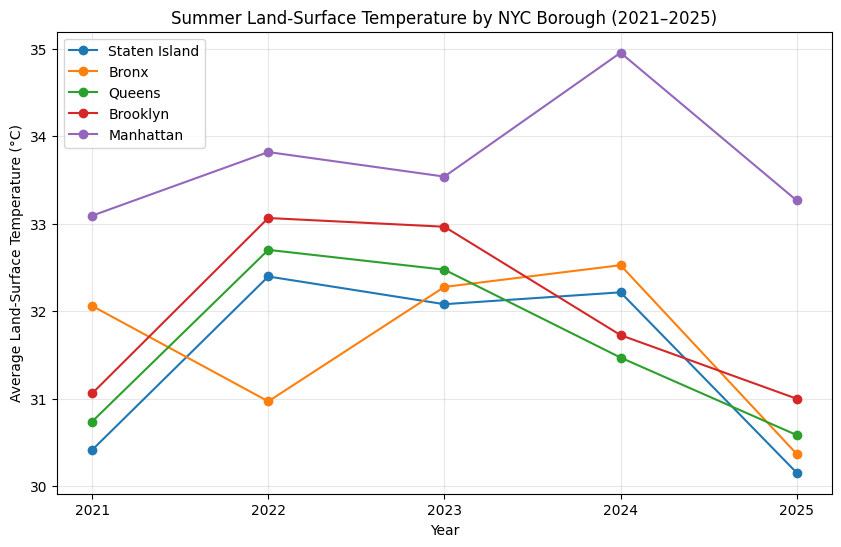

In [ ]:

plt.figure(figsize=(10, 6))

for borough in borough_df["Borough"].unique():

    subset = borough_df[
        borough_df["Borough"] == borough
    ].sort_values("Year")

    plt.plot(
        subset["Year"],
        subset["Avg_LST_C"],
        marker="o",
        label=borough
    )

plt.title("Summer Land-Surface Temperature by NYC Borough (2021–2025)")
plt.xlabel("Year")
plt.ylabel("Average Land-Surface Temperature (°C)")
plt.xticks(range(2021, 2026))
plt.legend()
plt.grid(alpha=0.3)
plt.show()


In [ ]:

# Compare temperatures across years
borough_table = borough_df.pivot(
    index="Borough",
    columns="Year",
    values="Avg_LST_C"
)

# Calculate change from 2021 to 2025
borough_table["Change_2021_2025"] = (
    borough_table[2025] - borough_table[2021]
)

print(borough_table.round(2))


Year            2021   2022   2023   2024   2025  Change_2021_2025
Borough                                                           
Bronx          32.06  30.97  32.28  32.52  30.37             -1.69
Brooklyn       31.06  33.06  32.96  31.73  31.00             -0.06
Manhattan      33.09  33.82  33.54  34.95  33.26              0.17
Queens         30.74  32.70  32.47  31.47  30.58             -0.15
Staten Island  30.41  32.40  32.08  32.21  30.15             -0.26


In [ ]:

# NYC county names converted to borough names
borough_map = {
    "Bronx": "Bronx",
    "Kings": "Brooklyn",
    "New York": "Manhattan",
    "Queens": "Queens",
    "Richmond": "Staten Island"
}

borough_results = []

for year in range(2021, 2026):

    image = summer_images[year].updateMask(land_mask)

    stats = image.reduceRegions(
        collection=nyc,
        reducer=ee.Reducer.mean(),
        scale=30,
        tileScale=4
    )

    for feature in stats.getInfo()["features"]:

        county = feature["properties"]["NAME"]
        temperature = feature["properties"].get("mean")

        borough_results.append({
            "Year": year,
            "Borough": borough_map[county],
            "Avg_LST_C": temperature
        })

borough_df = pd.DataFrame(borough_results)

print(borough_df)


    Year        Borough  Avg_LST_C
0   2021  Staten Island  30.412877
1   2021          Bronx  32.058958
2   2021         Queens  30.737594
3   2021       Brooklyn  31.059241
4   2021      Manhattan  33.090417
5   2022  Staten Island  32.395440
6   2022          Bronx  30.968296
7   2022         Queens  32.699643
8   2022       Brooklyn  33.063598
9   2022      Manhattan  33.817397
10  2023  Staten Island  32.078749
11  2023          Bronx  32.276192
12  2023         Queens  32.473238
13  2023       Brooklyn  32.963980
14  2023      Manhattan  33.536854
15  2024  Staten Island  32.214381
16  2024          Bronx  32.524410
17  2024         Queens  31.468672
18  2024       Brooklyn  31.725460
19  2024      Manhattan  34.952533
20  2025  Staten Island  30.152964
21  2025          Bronx  30.367861
22  2025         Queens  30.583397
23  2025       Brooklyn  30.998694
24  2025      Manhattan  33.264194


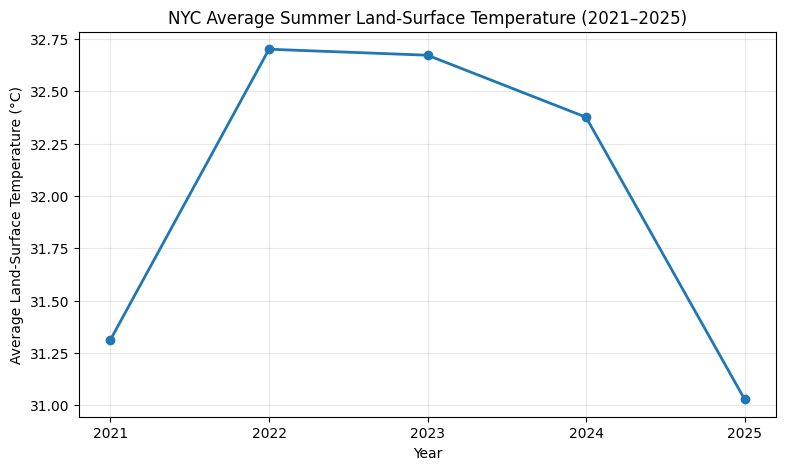

In [ ]:

plt.figure(figsize=(9, 5))

plt.plot(
    df["Year"],
    df["Avg_LST_C"],
    marker="o",
    linewidth=2
)

plt.title("NYC Average Summer Land-Surface Temperature (2021–2025)")
plt.xlabel("Year")
plt.ylabel("Average Land-Surface Temperature (°C)")
plt.xticks(df["Year"])
plt.grid(alpha=0.3)

plt.show()


In [ ]:

# Exclude permanent water pixels from calculations
water = ee.Image("JRC/GSW1_4/GlobalSurfaceWater").select(
    "occurrence"
)

# Retain pixels with less than 50% historical water occurrence
land_mask = water.lt(50)

results = []

for year in years:

    image = summer_images[year].updateMask(land_mask)

    stats = image.reduceRegion(
        reducer=ee.Reducer.mean(),
        geometry=nyc.geometry(),
        scale=30,
        maxPixels=1e10,
        tileScale=4
    )

    avg_temp = stats.get("LST_C").getInfo()

    results.append({
        "Year": year,
        "Avg_LST_C": avg_temp
    })

df = pd.DataFrame(results)

print(df)


   Year  Avg_LST_C
0  2021  31.312948
1  2022  32.701454
2  2023  32.672818
3  2024  32.376423
4  2025  31.028425


In [ ]:

# Calculate average summer LST for any year
def get_summer_temperature(year):

    start = f"{year}-06-01"
    end = f"{year}-09-01"

    images = (
        ee.ImageCollection("LANDSAT/LC08/C02/T1_L2")
        .filterBounds(nyc)
        .filterDate(start, end)
        .filter(ee.Filter.lt("CLOUD_COVER", 50))
        .map(process_landsat)
    )

    return images.mean().set("year", year)

# Generate annual summer temperature images
years = range(2021, 2026)

summer_images = {
    year: get_summer_temperature(year)
    for year in years
}

print("Created summer temperature images for 2021–2025!")


Created summer temperature images for 2021–2025!


In [ ]:

# Calculate average land-surface temperature
nyc_temperature = summer_2021.reduceRegion(
    reducer=ee.Reducer.mean(),
    geometry=nyc.geometry(),
    scale=30,
    maxPixels=1e9
)

print(
    "NYC Summer 2021 Average LST:",
    nyc_temperature.get("LST_C").getInfo(),
    "°C"
)


NYC Summer 2021 Average LST: 32.39611358343256 °C


In [ ]:

# Function to clean Landsat images and calculate temperature
def process_landsat(image):

    # Get quality assessment band
    qa = image.select("QA_PIXEL")

    # Mask fill, dilated cloud, cirrus, cloud, and shadow
    cloud_mask = qa.bitwiseAnd(int("11111", 2)).eq(0)

    # Mask saturated pixels
    saturation_mask = image.select("QA_RADSAT").eq(0)

    # Convert Landsat surface temperature to Celsius
    temperature = (
        image.select("ST_B10")
        .multiply(0.00341802)
        .add(149.0)
        .subtract(273.15)
        .rename("LST_C")
    )

    return (
        temperature
        .updateMask(cloud_mask)
        .updateMask(saturation_mask)
        .copyProperties(image, ["system:time_start"])
    )

# Process the summer 2021 satellite images
landsat_clean = landsat.map(process_landsat)

# Calculate mean summer land-surface temperature
summer_2021 = landsat_clean.mean()

print("Summer 2021 temperature image created!")


Summer 2021 temperature image created!


In [ ]:

landsat = (
    ee.ImageCollection("LANDSAT/LC08/C02/T1_L2")
    .filterBounds(nyc)
    .filterDate("2021-06-01", "2021-09-01")
    .filter(ee.Filter.lt("CLOUD_COVER", 50))
)

print("2021 Landsat images:", landsat.size().getInfo())


2021 Landsat images: 8


In [ ]:

# Install geemap if necessary
!pip -q install geemap

import geemap

# Create an interactive NYC map
Map = geemap.Map(center=[40.73, -73.94], zoom=10)

# Add borough boundaries
Map.addLayer(
    nyc.style(
        color="blue",
        fillColor="00000000",
        width=2
    ),
    {},
    "NYC Borough Boundaries"
)

Map


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 47.1 MB/s eta 0:00:00


Map(center=[40.73, -73.94], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright…

In [ ]:

# Display the county names
borough_names = nyc.aggregate_array("NAME").getInfo()

print("NYC borough counties:")
for name in sorted(borough_names):
    print("-", name)


NYC borough counties:
- Bronx
- Kings
- New York
- Queens
- Richmond


In [ ]:

# Load US Census county boundaries
counties = ee.FeatureCollection("TIGER/2018/Counties")

# NYC boroughs identified by their county FIPS codes
nyc_fips = ["005", "047", "061", "081", "085"]

nyc = counties.filter(
    ee.Filter.And(
        ee.Filter.eq("STATEFP", "36"),
        ee.Filter.inList("COUNTYFP", nyc_fips)
    )
)

# Confirm that all five boroughs loaded
print("Number of NYC boroughs:", nyc.size().getInfo())


Number of NYC boroughs: 5


In [ ]:

# Test Google Earth Engine
test = ee.Number(2025)

print("Study endpoint year:", test.getInfo())


Study endpoint year: 2025


In [ ]:

import ee
import pandas as pd
import matplotlib.pyplot as plt

# Authenticate with Google Earth Engine
ee.Authenticate()

# Replace with your Google Cloud project ID
ee.Initialize(project='nyc-heat-vulnerability-21-25')

print("Google Earth Engine connected successfully!")


Google Earth Engine connected successfully!
